In [1]:
# ============================================================
# Step 1: Verify the Python Environment and Required Packages
# ============================================================
# Purpose:
# 1. Confirm that the Python environment is working correctly.
# 2. Confirm that pandas is available for data processing.
# 3. Confirm that pyodbc is available for connecting to CGMS SQL Server.

# Import pandas for data loading, cleaning, and analysis
import pandas as pd



# Display package versions to confirm the environment setup
print("Python environment is ready!")
print("Pandas version:", pd.__version__)


Python environment is ready!
Pandas version: 2.3.3


In [2]:
# ============================================================
# Step 2: Install the SQL Server Connection Package
# ============================================================
# pyodbc is required to connect Python to the CGMS SQL Server database.
# %pip installs the package into the Python environment used by this notebook.

%pip install pyodbc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ============================================================
# Step 3: Verify the Database Connection Package
# ============================================================
# Import pyodbc and confirm that the installation was successful.

import pyodbc

print("pyodbc is ready!")
print("pyodbc version:", pyodbc.version)

pyodbc is ready!
pyodbc version: 5.3.0


In [4]:
# ============================================================
# Step 4: Check Available SQL Server ODBC Drivers
# ============================================================
# Purpose:
# Check which ODBC drivers are installed on the local computer.
# Python will use one of these drivers to connect to the CGMS SQL Server.

import pyodbc

drivers = pyodbc.drivers()

print("Available ODBC drivers:")
for driver in drivers:
    print("-", driver)

Available ODBC drivers:
- SQL Server


In [5]:
# ============================================================
# Step 5: Connect to the CGMS SQL Server Database
# ============================================================
# Purpose:
# 1. Connect Python to the CGMS_MDL local replica.
# 2. Use Windows Authentication / SSO instead of username and password.
# 3. Verify that the database connection works successfully.

import pyodbc

# Database connection parameters
server = "he-db.mdl.ccm.conti.de"
database = "CGMS_MDL"

# Build the connection string using Windows Authentication
# No username or password is required because SSO is enabled.
connection_string = (
    "DRIVER={SQL Server};"
    f"SERVER={server},1433;"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

# Try to connect to the CGMS SQL Server
try:
    conn = pyodbc.connect(connection_string)

    print("Database connection successful!")
    print("Server:", server)
    print("Database:", database)
    print("Authentication: Windows Authentication / SSO")

except pyodbc.Error as error:
    print("Database connection failed.")
    print("Error:", error)

Database connection successful!
Server: he-db.mdl.ccm.conti.de
Database: CGMS_MDL
Authentication: Windows Authentication / SSO


In [6]:
# ============================================================
# Step 6: Test Data Extraction from CGMS
# ============================================================
# Purpose:
# 1. Verify that Python can execute SQL queries on CGMS_MDL.
# 2. Load a small sample of production order data into pandas.
# 3. Confirm that the database connection and data extraction work correctly.

# Test query: retrieve a small sample from the Orders table
test_query = """
SELECT TOP 10 *
FROM [Orders]
"""

# Execute the SQL query and load the result into a pandas DataFrame
df_test = pd.read_sql(test_query, conn)

# Display the first rows
print("Data extraction successful!")
print("Number of rows:", len(df_test))
print("Number of columns:", len(df_test.columns))

df_test.head()

Data extraction successful!
Number of rows: 10
Number of columns: 73


C:\Users\Wangw3\AppData\Local\Temp\ipykernel_27360\1142827995.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_test = pd.read_sql(test_query, conn)


,OrderID,OrderIDLinked,OrderIDParent,OrderTypeID,WorkCenterID,RecipeID,MaterialMasterID,CarrierTypeID,OrderStatusID,PlantCode,...,OrderIDPaired,ExtTerminated,OrderIDCoupled,WorkCenterNameCoupled,MaterialMasterIDCoupled,OrderIDLeading,WorkCenterNameLeading,MaterialMasterIDLeading,PhaseInOut,IsGAPOrder
0,0100305433,None,None,NaN,651,119926,992540000200,None,12,9200,...,None,False,None,None,None,None,None,None,,False
1,0100305435,None,None,NaN,651,119926,992540000200,None,12,9200,...,None,False,None,None,None,None,None,None,,False
2,0100305438,None,None,NaN,651,119926,992540000200,None,11,9200,...,None,False,None,None,None,None,None,None,,False
3,0100305480,None,None,NaN,651,119928,992540001700,None,12,9200,...,None,False,None,None,None,None,None,None,,False
4,0100305508,None,None,NaN,651,119928,992540001700,None,12,9200,...,None,False,None,None,None,None,None,None,,False


In [7]:
# ============================================================
# Step 7: Extract Production Data for TB Capacity Analysis
# ============================================================
# Purpose:
# 1. Extract TB production order data from CGMS_MDL.
# 2. Combine production orders with Work Center, Production Version,
#    and Recipe information.
# 3. Load the SQL query result into a pandas DataFrame.
# 4. Create the main dataset for the following capacity analysis.

# Paste the validated SQL query from DBeaver between the triple quotes
query = """

SELECT
    -- ============================================================
    -- 1. Original fields from Orders
    -- ============================================================

    a.[OrderID],
    a.[OrderIDLinked],
    a.[WorkCenterID],
    a.[RecipeID],
    a.[MaterialMasterID],
    a.[Comment],

    -- Planned quantity
    a.[QuantitySet] AS PlannedQuantity,

    -- Actual finished quantity
    a.[QuantityDone],

    a.[ShiftNumber],
    a.[ShiftDate],
    a.[ActualStartTime],
    a.[ActualEndTime],
    a.[PlannedStartTime],
    a.[PlannedEndTime],
    a.[ProdVersion],
    a.[ProdVariant],
    a.[DestinationInfo],
    a.[ETOFlag],
    a.[PLCOrderNumber],
    a.[StatusUpdatedOn],
    a.[IsParent],
    a.[CreatedByCGMS],
    a.[InsertedOn],
    a.[UpdatedOn],
    a.[UserIDInsertedBy],
    a.[ExtTerminated],
    a.[OrderIDCoupled],
    a.[WorkCenterNameCoupled],
    a.[MaterialMasterIDCoupled],
    a.[PhaseInOut],
    a.[IsGAPOrder],


    -- ============================================================
    -- 2. Actual production duration
    --
    -- Formula:
    -- ActualEndTime - ActualStartTime
    --
    -- Unit: Seconds
    -- ============================================================

    DATEDIFF_BIG(
        SECOND,
        a.[ActualStartTime],
        a.[ActualEndTime]
    ) AS ActualProcessingTime,


    -- ============================================================
    -- 3. Actual production time per tire
    --
    -- Formula:
    -- (ActualEndTime - ActualStartTime) / QuantityDone
    --
    -- Unit: Seconds per tire
    -- ============================================================

    CASE
        WHEN a.[QuantityDone] > 0
        THEN
            CAST(
                DATEDIFF_BIG(
                    SECOND,
                    a.[ActualStartTime],
                    a.[ActualEndTime]
                ) AS DECIMAL(18, 4)
            )
            /
            CAST(
                a.[QuantityDone] AS DECIMAL(18, 4)
            )
        ELSE NULL
    END AS ActualTimePerTire,


    -- ============================================================
    -- 4. Descriptive information
    -- ============================================================

    -- Order status
    b.[GlobalName] AS OrderStatus,

    -- Work center name
    c.[Name] AS WorkCenterName,


    -- ============================================================
    -- 5. IE standard data from ProductionVersion
    --
    -- Matching:
    -- MaterialMasterID + WorkCenterID
    -- ============================================================

    d.[CycleTimePieces] AS CycleTimePieces,

    -- IE standard cycle time per 100 tires
    d.[CycleTime] AS IEStandardCycleTimePer100Tire,

    -- IE cycle time tolerance per 100 tires
    d.[CycleTimeTolerance] AS CycleTimeTolerancePer100Tire,

    -- IE standard total time per tire
    d.[TotalTime] AS IEStandardTotalTimePerTire,

    -- IE standard setup time per 100 tires
    d.[StandardSetupTime] AS StandardSetupTimePer100Tire,


    -- ============================================================
    -- 6. Operator information from UserLogin
    -- ============================================================

    -- Internal User ID
    ul.[UserID] AS OperatorUserID,

    -- Employee number
    ul.[EmployeeNumber] AS OperatorEmployeeNumber,

    -- Operator login start
    ul.[StartDate] AS OperatorStartDate,

    -- Operator login end
    ul.[EndDate] AS OperatorEndDate,

    -- Team leader flag
    ul.[IsTeamLeader] AS OperatorIsTeamLeader,

    -- Operator role
    ul.[OperatorWorkcenterRoleCatalogID]
        AS OperatorWorkcenterRoleCatalogID,


    -- ============================================================
    -- 7. Operator overlap start
    --
    -- Take later timestamp between:
    -- ActualStartTime and Operator StartDate
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        WHEN ul.[StartDate] > a.[ActualStartTime]
            THEN ul.[StartDate]

        ELSE a.[ActualStartTime]

    END AS OperatorOverlapStart,


    -- ============================================================
    -- 8. Operator overlap end
    --
    -- Take earlier timestamp between:
    -- ActualEndTime and Operator EndDate
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        WHEN ul.[EndDate] < a.[ActualEndTime]
            THEN ul.[EndDate]

        ELSE a.[ActualEndTime]

    END AS OperatorOverlapEnd,


    -- ============================================================
    -- 9. Operator overlap duration
    --
    -- Unit: Seconds
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        ELSE
            DATEDIFF_BIG(
                SECOND,

                CASE
                    WHEN ul.[StartDate] > a.[ActualStartTime]
                        THEN ul.[StartDate]
                    ELSE a.[ActualStartTime]
                END,

                CASE
                    WHEN ul.[EndDate] < a.[ActualEndTime]
                        THEN ul.[EndDate]
                    ELSE a.[ActualEndTime]
                END
            )

    END AS OperatorOverlapSeconds,


    -- ============================================================
    -- 10. Operator Coverage Ratio
    --
    -- Formula:
    -- OperatorOverlapSeconds / ActualProcessingTime
    --
    -- Examples:
    -- 1.00 = Operator covers 100% of Order duration
    -- 0.80 = Operator covers 80%
    -- 0.50 = Operator covers 50%
    -- 0.05 = Operator covers 5%
    -- ============================================================

    CASE
        WHEN ul.[UserID] IS NULL
            THEN NULL

        ELSE
            CAST(
                DATEDIFF_BIG(
                    SECOND,

                    CASE
                        WHEN ul.[StartDate] > a.[ActualStartTime]
                            THEN ul.[StartDate]
                        ELSE a.[ActualStartTime]
                    END,

                    CASE
                        WHEN ul.[EndDate] < a.[ActualEndTime]
                            THEN ul.[EndDate]
                        ELSE a.[ActualEndTime]
                    END

                ) AS DECIMAL(18, 4)
            )
            /
            NULLIF(
                CAST(
                    DATEDIFF_BIG(
                        SECOND,
                        a.[ActualStartTime],
                        a.[ActualEndTime]
                    ) AS DECIMAL(18, 4)
                ),
                0
            )

    END AS OperatorCoverageRatio


-- ================================================================
-- 11. Main table: Orders
-- ================================================================

FROM [Orders] a WITH (NOLOCK)


-- ================================================================
-- 12. Join OrderStatus
-- ================================================================

INNER JOIN [OrderStatus] b WITH (NOLOCK)
    ON a.[OrderStatusID] = b.[OrderStatusID]


-- ================================================================
-- 13. Join WorkCenter
-- ================================================================

INNER JOIN [WorkCenter] c WITH (NOLOCK)
    ON a.[WorkCenterID] = c.[WorkCenterID]


-- ================================================================
-- 14. Join ProductionVersion
--
-- Match using:
-- MaterialMasterID + WorkCenterID
-- ================================================================

LEFT JOIN [ProductionVersion] d WITH (NOLOCK)
    ON a.[MaterialMasterID] = d.[MaterialMasterID]
    AND a.[WorkCenterID] = d.[WorkCenterID]


-- ================================================================
-- 15. Join UserLogin
--
-- Operator / Order matching logic:
--
-- 1. Same WorkCenterID
-- 2. Operator StartDate < Order ActualEndTime
-- 3. Operator EndDate > Order ActualStartTime
--
-- Therefore:
-- Operator login period overlaps with Order production period.
--
-- LEFT JOIN:
-- Keep Order even when no valid Operator record is found.
-- ================================================================

LEFT JOIN [UserLogin] ul WITH (NOLOCK)

    -- Same WorkCenter
    ON a.[WorkCenterID] = ul.[WorkCenterID]

    -- Operator starts before the Order finishes
    AND ul.[StartDate] < a.[ActualEndTime]

    -- Operator ends after the Order starts
    AND ul.[EndDate] > a.[ActualStartTime]

    -- Only use completed UserLogin sessions
    AND ul.[EndDate] IS NOT NULL


-- ================================================================
-- 16. Data filters
-- ================================================================

WHERE c.[Name] LIKE 'TB%'

    -- Actual production start must exist
    AND a.[ActualStartTime] IS NOT NULL

    -- Actual production end must exist
    AND a.[ActualEndTime] IS NOT NULL

    -- End time cannot be before start time
    AND a.[ActualEndTime] >= a.[ActualStartTime]

    -- Only include QuantityDone > 0
    AND a.[QuantityDone] > 0

    -- Only include completed Orders
    AND b.[GlobalName] = 'Completed'

    -- Only retain current MaterialMasterID scope
    AND a.[MaterialMasterID] LIKE '99268%'

    -- Exclude CWM Orders
    AND a.[OrderID] NOT LIKE 'CWM%'


-- ================================================================
-- 17. Sort newest inserted Orders first
-- ================================================================

ORDER BY a.[InsertedOn] DESC;


"""

# Execute the SQL query and load the result into a pandas DataFrame
df_capacity = pd.read_sql(query, conn)

# Check the extracted dataset
print("Data extraction completed!")
print("Number of rows:", len(df_capacity))
print("Number of columns:", len(df_capacity.columns))

# Preview the first 5 records
df_capacity.head()

C:\Users\Wangw3\AppData\Local\Temp\ipykernel_27360\911673561.py:380: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_capacity = pd.read_sql(query, conn)


Data extraction completed!
Number of rows: 61098
Number of columns: 50


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorIsTeamLeader,OperatorWorkcenterRoleCatalogID,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
0,0132147924,0132147952,507,167612,992681042300,1: N0430-D222V,150.0,125.0,03,2026-11-09,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
1,0131913982,0131913417,510,176185,992681076100,1: H2100-S111,140.0,136.0,01,2026-11-10,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
2,0132147073,0132147145,509,134657,992680947300,1: N0430-D222V,100.0,110.0,03,2026-11-09,...,662.0,161982,2026-11-09 15:58:53.197,2026-11-10 00:02:41.820,True,None,2026-11-09 20:43:35.287,2026-11-09 22:49:58.797,7583.0,1.0
3,0132356165,0132355983,526,155236,992681015700,1: N0430-D222V,100.0,86.0,01,2026-11-10,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
4,0132126057,0132126435,724,177836,992680972800,1: N03303-D111V,150.0,103.0,03,2026-11-09,...,1221.0,254375,2026-11-09 19:24:11.597,2026-11-09 23:03:20.360,True,None,2026-11-09 20:18:09.923,2026-11-09 22:56:07.597,9478.0,1.0


In [8]:
# ============================================================
# Step 8: Initial Data Quality Check
# ============================================================
# Purpose:
# 1. Check the overall structure of the extracted dataset.
# 2. Review all column names and data types.
# 3. Check missing values across the full dataset.
# 4. Check duplicate rows and unique OrderIDs.
# 5. Understand the dataset before selecting analysis features.
# ============================================================


# ============================================================
# 8.1 Dataset dimensions
# ============================================================

print("Dataset shape:", df_capacity.shape)
print("Number of rows:", df_capacity.shape[0])
print("Number of columns:", df_capacity.shape[1])


# ============================================================
# 8.2 Display all column names
# ============================================================

print("\nColumns:")

for column in df_capacity.columns:
    print("-", column)


# ============================================================
# 8.3 Check data types
# ============================================================

print("\nData types:")

print(df_capacity.dtypes)


# ============================================================
# 8.4 Check missing values for ALL columns
# ============================================================
# Do not define key columns yet.
# First inspect missing values across the whole dataset.

missing_summary = pd.DataFrame({
    "MissingCount": df_capacity.isnull().sum(),
    "MissingPercent": (
        df_capacity.isnull().mean() * 100
    ).round(2)
})

missing_summary = (
    missing_summary
    .sort_values(
        "MissingPercent",
        ascending=False
    )
)

print("\nMissing values summary:")

display(missing_summary)


# ============================================================
# 8.5 Check completely duplicated rows
# ============================================================

duplicate_rows = df_capacity.duplicated().sum()

print("\nCompletely duplicated rows:", duplicate_rows)


# ============================================================
# 8.6 Check OrderID uniqueness
# ============================================================
# Important:
# One OrderID may appear multiple times because one production
# order can overlap with multiple Operator login records.

print("\nOrderID check:")

print("Total rows:", len(df_capacity))

print(
    "Unique OrderIDs:",
    df_capacity["OrderID"].nunique()
)

print(
    "Rows above unique OrderIDs:",
    len(df_capacity)
    - df_capacity["OrderID"].nunique()
)


# ============================================================
# 8.7 Preview the dataset
# ============================================================

print("\nDataset preview:")

display(df_capacity.head())

Dataset shape: (61098, 50)
Number of rows: 61098
Number of columns: 50

Columns:
- OrderID
- OrderIDLinked
- WorkCenterID
- RecipeID
- MaterialMasterID
- Comment
- PlannedQuantity
- QuantityDone
- ShiftNumber
- ShiftDate
- ActualStartTime
- ActualEndTime
- PlannedStartTime
- PlannedEndTime
- ProdVersion
- ProdVariant
- DestinationInfo
- ETOFlag
- PLCOrderNumber
- StatusUpdatedOn
- IsParent
- CreatedByCGMS
- InsertedOn
- UpdatedOn
- UserIDInsertedBy
- ExtTerminated
- OrderIDCoupled
- WorkCenterNameCoupled
- MaterialMasterIDCoupled
- PhaseInOut
- IsGAPOrder
- ActualProcessingTime
- ActualTimePerTire
- OrderStatus
- WorkCenterName
- CycleTimePieces
- IEStandardCycleTimePer100Tire
- CycleTimeTolerancePer100Tire
- IEStandardTotalTimePerTire
- StandardSetupTimePer100Tire
- OperatorUserID
- OperatorEmployeeNumber
- OperatorStartDate
- OperatorEndDate
- OperatorIsTeamLeader
- OperatorWorkcenterRoleCatalogID
- OperatorOverlapStart
- OperatorOverlapEnd
- OperatorOverlapSeconds
- OperatorCoverage

,MissingCount,MissingPercent
OperatorWorkcenterRoleCatalogID,61098,100.00
CreatedByCGMS,61098,100.00
OperatorIsTeamLeader,23035,37.70
OperatorEmployeeNumber,23035,37.70
IsParent,9991,16.35
UserIDInsertedBy,9991,16.35
OperatorStartDate,2531,4.14
OperatorUserID,2531,4.14
OperatorOverlapEnd,2531,4.14
OperatorOverlapStart,2531,4.14



Completely duplicated rows: 0

OrderID check:
Total rows: 61098
Unique OrderIDs: 23354
Rows above unique OrderIDs: 37744

Dataset preview:


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorIsTeamLeader,OperatorWorkcenterRoleCatalogID,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
0,0132147924,0132147952,507,167612,992681042300,1: N0430-D222V,150.0,125.0,03,2026-11-09,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
1,0131913982,0131913417,510,176185,992681076100,1: H2100-S111,140.0,136.0,01,2026-11-10,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
2,0132147073,0132147145,509,134657,992680947300,1: N0430-D222V,100.0,110.0,03,2026-11-09,...,662.0,161982,2026-11-09 15:58:53.197,2026-11-10 00:02:41.820,True,None,2026-11-09 20:43:35.287,2026-11-09 22:49:58.797,7583.0,1.0
3,0132356165,0132355983,526,155236,992681015700,1: N0430-D222V,100.0,86.0,01,2026-11-10,...,NaN,None,NaT,NaT,None,None,NaT,NaT,NaN,NaN
4,0132126057,0132126435,724,177836,992680972800,1: N03303-D111V,150.0,103.0,03,2026-11-09,...,1221.0,254375,2026-11-09 19:24:11.597,2026-11-09 23:03:20.360,True,None,2026-11-09 20:18:09.923,2026-11-09 22:56:07.597,9478.0,1.0


In [9]:
# ============================================================
# Step 9: Check Data Granularity and Order Duplication
# ============================================================
# Purpose:
# 1. Check whether one OrderID appears multiple times.
# 2. Understand how many rows exist for each OrderID.
# 3. Check whether duplicated OrderIDs are caused by multiple Operators.
# 4. Keep the original data unchanged at this stage.
# ============================================================


# ============================================================
# 9.1 Basic OrderID statistics
# ============================================================

total_rows = len(df_capacity)
unique_orders = df_capacity["OrderID"].nunique()
duplicated_order_rows = total_rows - unique_orders

print("Total rows:", total_rows)
print("Unique OrderIDs:", unique_orders)
print("Additional rows due to repeated OrderIDs:", duplicated_order_rows)


# ============================================================
# 9.2 Count number of rows per OrderID
# ============================================================

order_row_count = (
    df_capacity
    .groupby("OrderID")
    .size()
    .reset_index(name="RowCount")
    .sort_values("RowCount", ascending=False)
)

print("\nOrderID row count summary:")
display(order_row_count.head(20))


# ============================================================
# 9.3 Distribution of number of rows per Order
# ============================================================

order_row_distribution = (
    order_row_count["RowCount"]
    .value_counts()
    .sort_index()
    .reset_index()
)

order_row_distribution.columns = [
    "RowsPerOrder",
    "NumberOfOrders"
]

print("\nDistribution of rows per Order:")
display(order_row_distribution)


# ============================================================
# 9.4 Check number of Operators per Order
# ============================================================
# Since Orders were joined with UserLogin using WorkCenterID
# and time overlap, one Order may legitimately have multiple
# Operator records.
# ============================================================

operator_per_order = (
    df_capacity
    .groupby("OrderID")
    .agg(
        RowCount=("OrderID", "size"),
        UniqueOperatorCount=("OperatorUserID", "nunique"),
        MaxOperatorCoverage=("OperatorCoverageRatio", "max"),
        TotalOperatorCoverage=("OperatorCoverageRatio", "sum")
    )
    .reset_index()
    .sort_values(
        ["UniqueOperatorCount", "RowCount"],
        ascending=False
    )
)

print("\nOperator records per Order:")
display(operator_per_order.head(20))


# ============================================================
# 9.5 Inspect Orders with multiple Operators
# ============================================================

multi_operator_orders = operator_per_order[
    operator_per_order["UniqueOperatorCount"] > 1
]

print(
    "\nOrders with more than one Operator:",
    len(multi_operator_orders)
)

print(
    "Share of Orders with more than one Operator:",
    round(
        len(multi_operator_orders) / unique_orders * 100,
        2
    ),
    "%"
)

display(multi_operator_orders.head(20))


# ============================================================
# 9.6 Inspect detailed records for several multi-Operator Orders
# ============================================================
# This helps confirm whether duplicated OrderIDs are genuinely
# caused by different Operator login periods.
# ============================================================

sample_order_ids = (
    multi_operator_orders["OrderID"]
    .head(5)
    .tolist()
)

sample_multi_operator_records = (
    df_capacity[
        df_capacity["OrderID"].isin(sample_order_ids)
    ]
    [
        [
            "OrderID",
            "WorkCenterName",
            "ActualStartTime",
            "ActualEndTime",
            "QuantityDone",
            "ActualTimePerTire",
            "OperatorUserID",
            "OperatorEmployeeNumber",
            "OperatorStartDate",
            "OperatorEndDate",
            "OperatorOverlapSeconds",
            "OperatorCoverageRatio"
        ]
    ]
    .sort_values(
        ["OrderID", "OperatorCoverageRatio"],
        ascending=[True, False]
    )
)

print("\nExample Orders with multiple Operator records:")
display(sample_multi_operator_records)

Total rows: 61098
Unique OrderIDs: 23354
Additional rows due to repeated OrderIDs: 37744

OrderID row count summary:


,OrderID,RowCount
16651,0126496465,27
21160,0130257175,22
6089,0117157148,21
6447,0117507461,21
14893,0125092721,20
17570,0127257107,20
10939,0120893065,20
7772,0118470920,19
12349,0122999134,18
15598,0125630965,18



Distribution of rows per Order:


,RowsPerOrder,NumberOfOrders
0,1,5167
1,2,8463
2,3,5036
3,4,2543
4,5,982
5,6,557
6,7,210
7,8,145
8,9,77
9,10,58



Operator records per Order:


,OrderID,RowCount,UniqueOperatorCount,MaxOperatorCoverage,TotalOperatorCoverage
16651,0126496465,27,9,0.066674,0.979801
8196,0118773729,12,8,0.491863,1.799951
11309,0121404057,9,8,1.000000,2.421884
23319,0131914191,9,8,0.509774,1.589348
11311,0121404069,18,7,1.000000,2.634427
9246,0119711250,13,7,1.000000,1.665884
11134,0121201051,13,7,0.686505,1.059157
22228,0130898069,13,7,0.275095,0.743256
8163,0118773364,11,7,0.558000,1.998773
13320,0123651335,10,7,1.000000,4.000736



Orders with more than one Operator: 18123
Share of Orders with more than one Operator: 77.6 %


,OrderID,RowCount,UniqueOperatorCount,MaxOperatorCoverage,TotalOperatorCoverage
16651,0126496465,27,9,0.066674,0.979801
8196,0118773729,12,8,0.491863,1.799951
11309,0121404057,9,8,1.000000,2.421884
23319,0131914191,9,8,0.509774,1.589348
11311,0121404069,18,7,1.000000,2.634427
9246,0119711250,13,7,1.000000,1.665884
11134,0121201051,13,7,0.686505,1.059157
22228,0130898069,13,7,0.275095,0.743256
8163,0118773364,11,7,0.558000,1.998773
13320,0123651335,10,7,1.000000,4.000736



Example Orders with multiple Operator records:


,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,QuantityDone,ActualTimePerTire,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapSeconds,OperatorCoverageRatio
45997,0118773729,TB213,2026-09-19 15:58:29.850,2026-09-20 07:56:00.913,744.0,77.219086,656.0,161938,2026-09-19 16:00:35.550,2026-09-19 23:51:33.850,28258.0,0.491863
45987,0118773729,TB213,2026-09-19 15:58:29.850,2026-09-20 07:56:00.913,744.0,77.219086,0.0,None,2026-09-20 01:29:35.927,2026-09-21 02:48:59.307,23185.0,0.403561
45991,0118773729,TB213,2026-09-19 15:58:29.850,2026-09-20 07:56:00.913,744.0,77.219086,0.0,None,2026-09-19 21:28:15.597,2026-09-20 01:29:35.580,14480.0,0.252041
45996,0118773729,TB213,2026-09-19 15:58:29.850,2026-09-20 07:56:00.913,744.0,77.219086,635.0,151804,2026-09-20 04:33:14.610,2026-09-20 07:55:28.330,12134.0,0.211206
45989,0118773729,TB213,2026-09-19 15:58:29.850,2026-09-20 07:56:00.913,744.0,77.219086,0.0,None,2026-09-18 16:08:13.950,2026-09-19 19:13:05.433,11676.0,0.203234
...,...,...,...,...,...,...,...,...,...,...,...,...
85,0131914191,TB231,2026-11-09 05:02:52.523,2026-11-09 18:20:52.777,117.0,409.230769,708.0,172341,2026-11-09 09:14:59.683,2026-11-09 09:46:52.333,1913.0,0.039954
83,0131914191,TB231,2026-11-09 05:02:52.523,2026-11-09 18:20:52.777,117.0,409.230769,594.0,141455,2026-11-09 15:28:54.013,2026-11-09 15:57:24.657,1710.0,0.035714
77,0131914191,TB231,2026-11-09 05:02:52.523,2026-11-09 18:20:52.777,117.0,409.230769,1395.0,None,2026-11-09 09:21:28.373,2026-11-09 09:46:47.930,1519.0,0.031725
81,0131914191,TB231,2026-11-09 05:02:52.523,2026-11-09 18:20:52.777,117.0,409.230769,557.0,120870,2026-11-09 08:54:38.377,2026-11-09 09:14:30.663,1192.0,0.024896


In [10]:
# ============================================================
# Step 9.7: Inspect one Order and its Operator login sessions
# ============================================================
# Purpose:
# Check why one OrderID is matched with multiple UserLogin records.
# ============================================================

test_order = "0116037287"

order_operator_check = (
    df_capacity[
        df_capacity["OrderID"].astype(str) == test_order
    ]
    [
        [
            "OrderID",
            "WorkCenterName",
            "ActualStartTime",
            "ActualEndTime",
            "QuantityDone",
            "ActualTimePerTire",
            "OperatorUserID",
            "OperatorEmployeeNumber",
            "OperatorStartDate",
            "OperatorEndDate",
            "OperatorOverlapStart",
            "OperatorOverlapEnd",
            "OperatorOverlapSeconds",
            "OperatorCoverageRatio"
        ]
    ]
    .sort_values(
        [
            "OperatorUserID",
            "OperatorStartDate"
        ]
    )
)

display(order_operator_check)

,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,QuantityDone,ActualTimePerTire,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapStart,OperatorOverlapEnd,OperatorOverlapSeconds,OperatorCoverageRatio
55746,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,0.0,None,2026-09-10 21:13:46.197,2026-09-12 17:45:06.147,2026-09-10 21:13:46.197,2026-09-11 12:27:56.537,54850.0,0.454444
55748,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,715.0,172367,2026-09-11 08:00:41.890,2026-09-11 08:28:11.650,2026-09-11 08:00:41.890,2026-09-11 08:28:11.650,1650.0,0.013671
55747,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,715.0,172367,2026-09-11 09:04:38.167,2026-09-11 09:32:15.390,2026-09-11 09:04:38.167,2026-09-11 09:32:15.390,1657.0,0.013729
55750,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1038.0,172389,2026-09-10 08:01:00.330,2026-09-10 09:45:17.397,2026-09-10 08:01:00.330,2026-09-10 09:45:17.397,6257.0,0.051841
55749,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1038.0,172389,2026-09-10 09:46:34.380,2026-09-10 12:55:09.970,2026-09-10 09:46:34.380,2026-09-10 12:55:09.970,11315.0,0.093747
55753,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1063.0,223943,2026-09-10 09:45:12.483,2026-09-10 09:46:37.860,2026-09-10 09:45:12.483,2026-09-10 09:46:37.860,85.0,0.000704
55751,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1063.0,223943,2026-09-10 12:55:04.897,2026-09-10 15:58:18.903,2026-09-10 12:55:04.897,2026-09-10 15:58:18.903,10994.0,0.091088
55752,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1063.0,223943,2026-09-11 08:28:07.677,2026-09-11 09:04:39.693,2026-09-11 08:28:07.677,2026-09-11 09:04:39.693,2192.0,0.018161
55754,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1063.0,223943,2026-09-11 09:32:10.133,2026-09-11 15:53:44.197,2026-09-11 09:32:10.133,2026-09-11 12:27:56.537,10546.0,0.087376
55755,0116037287,TB2A1,2026-09-10 02:56:19.803,2026-09-11 12:27:56.537,147.0,821.068027,1299.0,254539,2026-09-10 15:58:26.477,2026-09-10 23:55:09.110,2026-09-10 15:58:26.477,2026-09-10 23:55:09.110,28603.0,0.236982


In [11]:
# ============================================================
# Step 10.1: Remove invalid Operator records
# ============================================================
# Purpose:
# 1. Remove OperatorUserID = 0.
# 2. Remove missing OperatorUserID.
# 3. Keep different login sessions of the same Operator.
# 4. Do NOT filter EmployeeNumber at this stage.
# ============================================================

df_capacity_clean = df_capacity[
    df_capacity["OperatorUserID"].notna()
    & (df_capacity["OperatorUserID"] != 0)
].copy()


# Check cleaning result
print("Original rows:", len(df_capacity))
print("Clean rows:", len(df_capacity_clean))
print("Rows removed:", len(df_capacity) - len(df_capacity_clean))

print(
    "Remaining OperatorUserID = 0:",
    (df_capacity_clean["OperatorUserID"] == 0).sum()
)

print(
    "Remaining missing OperatorUserID:",
    df_capacity_clean["OperatorUserID"].isna().sum()
)

Original rows: 61098
Clean rows: 52317
Rows removed: 8781
Remaining OperatorUserID = 0: 0
Remaining missing OperatorUserID: 0


In [12]:
# ============================================================
# Step 10.2: General Overview of Operator Coverage by Order
# ============================================================
# Purpose:
# 1. Analyze Operator coverage across ALL Orders.
# 2. Exclude OperatorUserID = 0.
# 3. Keep every login session separately.
# 4. Check the overall distribution of TotalOperatorCoverage.
# ============================================================

# Remove OperatorUserID = 0
df_capacity_clean = df_capacity[
    df_capacity["OperatorUserID"] != 0
].copy()


# ============================================================
# Calculate Operator coverage for every Order
# ============================================================

order_coverage_overview = (
    df_capacity_clean
    .groupby("OrderID")
    .agg(
        LoginSessionCount=("OrderID", "size"),
        UniqueOperatorCount=("OperatorUserID", "nunique"),
        TotalOperatorCoverage=("OperatorCoverageRatio", "sum"),
        MaxOperatorCoverage=("OperatorCoverageRatio", "max")
    )
    .reset_index()
)


# ============================================================
# General statistics
# ============================================================

total_orders = len(order_coverage_overview)

orders_under_100 = (
    order_coverage_overview["TotalOperatorCoverage"] < 1
).sum()

orders_around_100 = (
    order_coverage_overview["TotalOperatorCoverage"]
    .between(0.99, 1.01)
).sum()

orders_over_100 = (
    order_coverage_overview["TotalOperatorCoverage"] > 1
).sum()

orders_over_200 = (
    order_coverage_overview["TotalOperatorCoverage"] > 2
).sum()

orders_over_300 = (
    order_coverage_overview["TotalOperatorCoverage"] > 3
).sum()

orders_over_400 = (
    order_coverage_overview["TotalOperatorCoverage"] > 4
).sum()


print("===== General Operator Coverage Overview =====")

print("Total Orders:", total_orders)

print(
    "Orders with Coverage < 100%:",
    orders_under_100,
    f"({orders_under_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage around 100%:",
    orders_around_100,
    f"({orders_around_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 100%:",
    orders_over_100,
    f"({orders_over_100 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 200%:",
    orders_over_200,
    f"({orders_over_200 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 300%:",
    orders_over_300,
    f"({orders_over_300 / total_orders * 100:.2f}%)"
)

print(
    "Orders with Coverage > 400%:",
    orders_over_400,
    f"({orders_over_400 / total_orders * 100:.2f}%)"
)


# ============================================================
# Coverage descriptive statistics
# ============================================================

print("\n===== Total Operator Coverage Statistics =====")

display(
    order_coverage_overview[
        "TotalOperatorCoverage"
    ].describe()
)


# ============================================================
# Orders with the highest TotalOperatorCoverage
# ============================================================

print("\n===== Orders with Highest Operator Coverage =====")

display(
    order_coverage_overview
    .sort_values(
        "TotalOperatorCoverage",
        ascending=False
    )
    .head(20)
)

===== General Operator Coverage Overview =====
Total Orders: 23350
Orders with Coverage < 100%: 4725 (20.24%)
Orders with Coverage around 100%: 7080 (30.32%)
Orders with Coverage > 100%: 14360 (61.50%)
Orders with Coverage > 200%: 2934 (12.57%)
Orders with Coverage > 300%: 177 (0.76%)
Orders with Coverage > 400%: 29 (0.12%)

===== Total Operator Coverage Statistics =====


count    23350.000000
mean         1.415929
std          0.727697
min          0.000000
25%          1.000000
50%          1.734623
75%          2.000000
max          4.000617
Name: TotalOperatorCoverage, dtype: float64


===== Orders with Highest Operator Coverage =====


,OrderID,LoginSessionCount,UniqueOperatorCount,TotalOperatorCoverage,MaxOperatorCoverage
8745,0119366436,5,3,4.000617,1.0
10710,0120881730,5,5,4.000617,1.0
7357,0118172731,5,4,4.000562,1.0
7711,0118456585,5,4,4.000539,1.0
10706,0120880323,5,5,4.000418,1.0
9394,0119882857,5,4,4.000388,1.0
15759,0125903446,5,5,4.000354,1.0
12157,0122986662,5,4,4.000346,1.0
10019,0120150275,5,4,4.000285,1.0
14062,0124545942,5,5,4.000265,1.0


In [13]:
# ============================================================
# Step 10.3: Operator Coverage General Overview
# ============================================================
# Purpose:
# 1. Analyze Operator information for ALL Orders.
# 2. Keep different login sessions of the same Operator separately.
# 3. Count how many unique Operators are matched to each Order.
# 4. Calculate total Operator overlap time for each Order.
# 5. Keep TotalOperatorCoverage for comparison.
# ============================================================

operator_order_overview = (
    df_capacity_clean
    .groupby("OrderID")
    .agg(
        LoginSessionCount=("OrderID", "size"),

        UniqueOperatorCount=(
            "OperatorUserID",
            "nunique"
        ),

        TotalOperatorOverlapSeconds=(
            "OperatorOverlapSeconds",
            "sum"
        ),

        TotalOperatorCoverage=(
            "OperatorCoverageRatio",
            "sum"
        )
    )
    .reset_index()
)


# ============================================================
# General overview
# ============================================================

print("===== Operator Overview by Order =====")

print("Total Orders:", len(operator_order_overview))

print(
    "Average Login Sessions per Order:",
    round(operator_order_overview["LoginSessionCount"].mean(), 2)
)

print(
    "Average Unique Operators per Order:",
    round(operator_order_overview["UniqueOperatorCount"].mean(), 2)
)


# ============================================================
# Distribution of Unique Operator Count
# ============================================================

operator_count_distribution = (
    operator_order_overview[
        "UniqueOperatorCount"
    ]
    .value_counts()
    .sort_index()
    .reset_index()
)

operator_count_distribution.columns = [
    "UniqueOperatorCount",
    "NumberOfOrders"
]

print("\n===== Unique Operator Count Distribution =====")

display(operator_count_distribution)


# ============================================================
# Overall statistics
# ============================================================

print("\n===== Operator Coverage Statistics =====")

display(
    operator_order_overview[
        [
            "LoginSessionCount",
            "UniqueOperatorCount",
            "TotalOperatorOverlapSeconds",
            "TotalOperatorCoverage"
        ]
    ].describe()
)

===== Operator Overview by Order =====
Total Orders: 23350
Average Login Sessions per Order: 2.35
Average Unique Operators per Order: 1.94

===== Unique Operator Count Distribution =====


,UniqueOperatorCount,NumberOfOrders
0,0,2531
1,1,4802
2,2,9168
3,3,5407
4,4,1226
5,5,184
6,6,25
7,7,6
8,9,1



===== Operator Coverage Statistics =====


,LoginSessionCount,UniqueOperatorCount,TotalOperatorOverlapSeconds,TotalOperatorCoverage
count,23350.000000,23350.000000,23350.000000,23350.000000
mean,2.348951,1.943640,15946.086938,1.415929
std,1.546830,1.083633,12415.111973,0.727697
min,1.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,8295.000000,1.000000
50%,2.000000,2.000000,14470.000000,1.734623
75%,3.000000,3.000000,20947.750000,2.000000
max,27.000000,9.000000,439175.000000,4.000617


In [14]:
# ============================================================
# Step 10.4: Check Operator records without EmployeeNumber
# ============================================================
# Purpose:
# 1. Check non-zero UserIDs without EmployeeNumber.
# 2. Identify how frequently these UserIDs occur.
# 3. Inspect whether they represent unusually long login sessions.
# ============================================================

missing_employee_check = (
    df_capacity[
        (df_capacity["OperatorUserID"] != 0)
        & (df_capacity["OperatorEmployeeNumber"].isna())
    ]
    .groupby("OperatorUserID")
    .agg(
        RowCount=("OrderID", "size"),
        UniqueOrders=("OrderID", "nunique"),
        EarliestLogin=("OperatorStartDate", "min"),
        LatestLogout=("OperatorEndDate", "max"),
        MaxCoverage=("OperatorCoverageRatio", "max")
    )
    .reset_index()
    .sort_values("UniqueOrders", ascending=False)
)

print(
    "Unique non-zero UserIDs without EmployeeNumber:",
    missing_employee_check["OperatorUserID"].nunique()
)

display(missing_employee_check.head(30))


Unique non-zero UserIDs without EmployeeNumber: 39


,OperatorUserID,RowCount,UniqueOrders,EarliestLogin,LatestLogout,MaxCoverage
35,1408.0,1273,1272,2026-08-26 06:10:21.020,2026-11-09 02:20:08.413,1.000000
34,1407.0,1134,1134,2026-09-10 00:26:57.060,2026-11-05 17:58:45.873,1.000000
4,546.0,1017,929,2026-09-02 02:52:17.140,2026-11-07 04:08:13.447,1.000000
32,1404.0,872,871,2026-08-15 00:13:07.073,2026-11-10 03:01:35.610,1.000000
25,1392.0,825,825,2026-08-12 00:11:28.273,2026-11-08 01:48:51.273,1.000000
19,1384.0,766,765,2026-08-28 20:14:59.647,2026-11-08 21:14:54.480,1.000000
33,1405.0,748,748,2026-09-04 08:08:21.363,2026-11-06 10:23:01.080,1.000000
31,1403.0,740,739,2026-08-27 12:14:26.777,2026-10-28 18:14:37.777,1.000000
3,513.0,668,666,2026-08-27 16:27:47.623,2026-11-09 04:00:29.663,1.000000
17,1382.0,656,656,2026-08-26 16:20:22.280,2026-11-09 07:23:38.343,1.000000


In [15]:
# ============================================================
# Step 10.3A: Check Orders with 0 Unique Operators
# ============================================================

zero_operator_orders = operator_order_overview[
    operator_order_overview["UniqueOperatorCount"] == 0
]["OrderID"]

print("Orders with 0 Unique Operators:", zero_operator_orders.nunique())

zero_operator_details = df_capacity[
    df_capacity["OrderID"].isin(zero_operator_orders)
][
    [
        "OrderID",
        "WorkCenterName",
        "ActualStartTime",
        "ActualEndTime",
        "OperatorUserID",
        "OperatorEmployeeNumber",
        "OperatorStartDate",
        "OperatorEndDate",
        "OperatorOverlapSeconds",
        "OperatorCoverageRatio"
    ]
]

display(zero_operator_details.head(30))

Orders with 0 Unique Operators: 2531


,OrderID,WorkCenterName,ActualStartTime,ActualEndTime,OperatorUserID,OperatorEmployeeNumber,OperatorStartDate,OperatorEndDate,OperatorOverlapSeconds,OperatorCoverageRatio
0,0132147924,TB213,2026-11-09 23:59:22.713,2026-11-10 02:03:35.450,NaN,None,NaT,NaT,NaN,NaN
1,0131913982,TB223,2026-11-10 02:05:59.977,2026-11-10 05:07:27.230,NaN,None,NaT,NaT,NaN,NaN
3,0132356165,TB263,2026-11-10 02:01:55.403,2026-11-10 04:00:15.230,NaN,None,NaT,NaT,NaN,NaN
54,0132146868,TB241,2026-11-10 03:02:02.610,2026-11-10 04:50:04.620,NaN,None,NaT,NaT,NaN,NaN
55,0131676786,TB241,2026-11-10 01:27:40.427,2026-11-10 03:02:02.610,NaN,None,NaT,NaT,NaN,NaN
89,0131911824,TB264,2026-11-10 00:42:16.637,2026-11-10 02:46:26.300,NaN,None,NaT,NaT,NaN,NaN
193,0131914076,TB251,2026-11-10 01:24:19.190,2026-11-10 04:27:20.567,NaN,None,NaT,NaT,NaN,NaN
233,0131913098,TB271,2026-11-10 01:32:48.657,2026-11-10 02:56:54.380,NaN,None,NaT,NaT,NaN,NaN
251,0131912020,TB275,2026-11-10 01:06:31.923,2026-11-10 04:26:26.710,NaN,None,NaT,NaT,NaN,NaN
255,0131912433,TB262,2026-11-10 01:41:14.753,2026-11-10 04:40:36.530,NaN,None,NaT,NaT,NaN,NaN


In [16]:
# ============================================================
# Step 11.1: Create Green Tire Mapping Key
# ============================================================
# Purpose:
# 1. Keep the original MaterialMasterID unchanged.
# 2. Remove the last two digits "00" for Redshift mapping.
# 3. Create a separate GT mapping key.
# ============================================================

df_capacity["GT_MappingKey"] = (
    df_capacity["MaterialMasterID"]
    .astype("string")
    .str.strip()
    .str[:-2]
)

# Check
display(
    df_capacity[
        ["MaterialMasterID", "GT_MappingKey"]
    ]
    .drop_duplicates()
    .head(20)
)

,MaterialMasterID,GT_MappingKey
0,992681042300,9926810423
1,992681076100,9926810761
2,992680947300,9926809473
3,992681015700,9926810157
4,992680972800,9926809728
5,992681073200,9926810732
14,992680839600,9926808396
18,992681023000,9926810230
21,992680900100,9926809001
24,992681068000,9926810680


In [17]:
import redshift_connector

print(redshift_connector.__version__)


2.2.0


In [18]:
# ============================================================
# Step： Connect to Redshift via Azure SSO
# Purpose: Replicate the working DBeaver Azure OAuth settings
# ============================================================

import redshift_connector

conn = redshift_connector.connect(
    iam=True,

    # Redshift connection
    host="mustang-global-redshift-datamart-01.cs0z5y6iuviq.eu-central-1.redshift.amazonaws.com",
    port=5439,
    database="mustangmaster",
    cluster_identifier="mustang-global-redshift-datamart-01",

    # Azure SSO
    credentials_provider="BrowserAzureOAuth2CredentialsProvider",
    client_id="9327ae8a-80ad-486d-ac70-52374b76a1b7",
    idp_tenant="8d4b558f-7b2e-40ba-ad1f-e04d79e6265a",
    scope="api://9327ae8a-80ad-486d-ac70-52374b76a1b7/jdbc_login",
    idp_response_timeout=50
)

print("✅ Redshift connected successfully!")

✅ Redshift connected successfully!


In [19]:
# ============================================================
# Step  - Create Redshift Cursor and Test Connection
# Purpose: Verify that SQL queries can run successfully
# ============================================================

cursor = conn.cursor()

cursor.execute("""
    SELECT current_database(), current_user;
""")

result = cursor.fetchone()

print("Database:", result[0])
print("User:", result[1])

Database: mustangmaster
User: oauth_aad:uia50682@contiwan.com


In [20]:
# ============================================================
# Step 12: Extract Tire Structure Data from Redshift
# Source: he_datamarts.article
# Filter: greentire_localworkcode starts with '99268'
# Output: redshift_article_df
# ============================================================

import pandas as pd

sql = """
SELECT
    article_pk,
    articleid,
    base_articleid,
    article7,
    variant,
    plant_dot_code,
    spec_issue,
    spec_type,
    base_article7,
    base_variant,
    base_plant_dot_code,
    base_spec_issue,
    base_spec_type,
    description,
    product_line_id,
    marketing_line,
    color_code,
    tire_size,
    greentire_gutsid,
    greentire_localworkcode,
    greentire_code,
    speed_symbol,
    ssr_flag,
    enrichment_type,
    tire_group_description,
    release_note_number,
    tire_release_note,
    pog_segment,
    pog_segment_description,
    src_created_timestamp,
    src_last_modified_timestamp,
    base_src_created_timestamp,
    base_src_last_modified_timestamp,
    created_utc_timestamp,
    last_modified_utc_timestamp,
    from_tran,
    stamping_code,
    rim_diameter,
    postcureinflation_active,
    carcass_localworkcode,
    release_date,
    article_development_cluster_name,
    article_cluster_link_status,
    base_article_development_cluster_name,
    base_article_cluster_link_status,
    ply_lock,
    "1_stage_drum_width",
    "drum_profile-no",
    "2_stage_drum_diameter",
    bladder_code,
    "1_liner_-_profile_geometry_code",
    "1_liner_-_compound",
    "1_liner_-_width",
    "1_liner_-_thickness",
    "1_apex_-_compound",
    "1_apex_-_profile_geometry_code",
    "1_apex_-_width",
    "1_apex_-_thickness",
    "bead_-_bead_inner_diameter",
    "bead_-_bead_circumference",
    "bead_-_bead_construction",
    "1_ply_assembly_-_1_strip_rubber_-_compound",
    "1_ply_assembly_-_1_strip_rubber_-_width",
    "1_ply_assembly_-_1_strip_rubber_-_thickness",
    "1_carcass_ply_-_width",
    "2_carcass_ply_-_cf_code",
    "2_carcass_ply_-_width",
    "2_carcass_ply_-_thickness",
    "1_bead_reinforcement_-_cf_code",
    "1_bead_reinforcement_-_angle",
    "1_bead_reinforcement_-_width",
    "1_flange_cushion_-_compound",
    "1_sidewall_-_bom_component_setting",
    "1_sidewall_profile_-_compound",
    "1_sidewall_profile_-_weight",
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_sidewall_-_combined_profile_-_width",
    "1_belt_-_cf_code",
    "1_belt_-_gradient",
    "1_belt_-_angle",
    "1_belt_-_cf_compound_top",
    "1_belt_-_cf_construction",
    "1_belt_-_cf_epdm",
    "1_belt_-_width",
    "1_belt_ply_assembly_-_1_strip_rubber_-_compound",
    "1_belt_ply_assembly_-_1_strip_rubber_-_width",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "2_belt_-_cf_code",
    "2_belt_-_angle",
    "2_belt_-_gradient",
    "2_belt_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_thickness",
    "2_belt_ply_assembly_-_1_strip_rubber_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting",
    "1_wound_cap_ply_-_cf_code",
    "1_wound_cap_ply_-_cf_construction",
    "1_wound_cap_ply_-_spooling_construction",
    "1_wound_cap_ply_-_ptc_min",
    "1_wound_cap_ply_-_ptc_max",
    "1_tread_base_-_compound",
    "1_tread_base_-_width",
    "1_tread_cap_-_compound",
    "1_tread_wing_-_width",
    "1_tread_wing_-_profile_geometry_code",
    "1_tread-belt_assembly_-_weight",
    local_code,
    oeindicator
FROM he_datamarts.article
WHERE greentire_localworkcode LIKE '99268%'
"""

cursor = conn.cursor()
cursor.execute(sql)

columns = [desc[0] for desc in cursor.description]
redshift_article_df = pd.DataFrame(cursor.fetchall(), columns=columns)

print("Rows:", redshift_article_df.shape[0])
print("Columns:", redshift_article_df.shape[1])

display(redshift_article_df.head())

Rows: 12047
Columns: 107


,article_pk,articleid,base_articleid,article7,variant,plant_dot_code,spec_issue,spec_type,base_article7,base_variant,...,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_tread_base_-_compound,1_tread_base_-_width,1_tread_cap_-_compound,1_tread_wing_-_width,1_tread_wing_-_profile_geometry_code,1_tread-belt_assembly_-_weight,local_code,oeindicator
0,LF0311021000AA0014,LF0311021000AA0014,LF0311021000AA0014,0311021,AA,LF,001,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:RGGO,Y
1,LF0311021000AA0024,LF0311021000AA0024,LF0311021000AA0024,0311021,AA,LF,002,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
2,LF0311021000AA0034,LF0311021000AA0034,LF0311021000AA0034,0311021,AA,LF,003,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
3,LF0311021000AA0044,LF0311021000AA0044,LF0311021000AA0044,0311021,AA,LF,004,4,0311021,AA,...,15.0,75.0,T00011,262.000,T11923,14.000,07RON,9.065,:GROO,Y
4,LF0311021000AA0054,LF0311021000AA0054,LF0311021000AA0054,0311021,AA,LF,005,4,0311021,AA,...,15.0,50.0,T17771,135.000,T33025,14.000,08FET,9.142,:GROO,Y


In [21]:
# ============================================================
# Step 13 - Merge Capacity Data with Redshift Article Data
# Purpose:
# 1. Keep df_capacity as the master dataset
# 2. Keep only one Redshift record per GT
# 3. Add all Redshift structure columns
# 4. Keep the same number of rows as df_capacity
# ============================================================

# Keep only one record per GT in Redshift
redshift_article_unique = (
    redshift_article_df
    .drop_duplicates(
        subset=["greentire_localworkcode"],
        keep="first"
    )
    .copy()
)

# Merge Redshift structure data into df_capacity
df_capacity_merged = df_capacity.merge(
    redshift_article_unique,
    how="left",
    left_on="GT_MappingKey",
    right_on="greentire_localworkcode",
    validate="many_to_one"
)

# Check result
print("Original df_capacity rows:", len(df_capacity))
print("Redshift original rows:", len(redshift_article_df))
print("Redshift unique GTs:", len(redshift_article_unique))
print("Merged rows:", len(df_capacity_merged))
print("Columns after join:", df_capacity_merged.shape[1])

# Safety check
assert len(df_capacity_merged) == len(df_capacity), \
    "ERROR: Row count changed after merge!"

print("\n✅ Merge successful - df_capacity row count unchanged.")

display(df_capacity_merged.head())

Original df_capacity rows: 61098
Redshift original rows: 12047
Redshift unique GTs: 6827
Merged rows: 61098
Columns after join: 158

✅ Merge successful - df_capacity row count unchanged.


,OrderID,OrderIDLinked,WorkCenterID,RecipeID,MaterialMasterID,Comment,PlannedQuantity,QuantityDone,ShiftNumber,ShiftDate,...,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_tread_base_-_compound,1_tread_base_-_width,1_tread_cap_-_compound,1_tread_wing_-_width,1_tread_wing_-_profile_geometry_code,1_tread-belt_assembly_-_weight,local_code,oeindicator
0,0132147924,0132147952,507,167612,992681042300,1: N0430-D222V,150.0,125.0,03,2026-11-09,...,15.0,75.0,T00011,208.000,T15192,14.000,04KM1,4.974,:RAG,N
1,0131913982,0131913417,510,176185,992681076100,1: H2100-S111,140.0,136.0,01,2026-11-10,...,15.0,15.0,T00011,116.000,T02128,16.000,07A4R,5.831,A:WPW,Y
2,0132147073,0132147145,509,134657,992680947300,1: N0430-D222V,100.0,110.0,03,2026-11-09,...,15.0,75.0,T00011,224.000,T15760,14.000,09F20,6.097,:AWW,N
3,0132356165,0132355983,526,155236,992681015700,1: N0430-D222V,100.0,86.0,01,2026-11-10,...,15.0,75.0,T00011,216.000,T15760,16.000,02C0N,6.548,P:OAO,N
4,0132126057,0132126435,724,177836,992680972800,1: N03303-D111V,150.0,103.0,03,2026-11-09,...,15.0,75.0,T00011,252.000,T11347,16.000,0AAHF,7.709,:AROO,Y


In [22]:
# ============================================================
# Step 14 - Check Redshift GT Structure Matching Coverage
# Purpose:
# 1. Check how many df_capacity records matched Redshift
# 2. Calculate matching coverage
# 3. Check unmatched GTs
# ============================================================

total_rows = len(df_capacity_merged)

matched_rows = df_capacity_merged[
    "greentire_localworkcode"
].notna().sum()

unmatched_rows = df_capacity_merged[
    "greentire_localworkcode"
].isna().sum()

match_rate = matched_rows / total_rows * 100

print("Total capacity records :", total_rows)
print("Matched records        :", matched_rows)
print("Unmatched records      :", unmatched_rows)
print(f"Redshift match rate    : {match_rate:.2f}%")

Total capacity records : 61098
Matched records        : 61098
Unmatched records      : 0
Redshift match rate    : 100.00%


In [23]:
# ============================================================
# Step 15 - Final Dataset Data Quality Overview
# Purpose:
# 1. Check final dataset shape
# 2. Check numeric vs categorical columns
# 3. Check missing values
# ============================================================

print("Final dataset shape:", df_capacity_merged.shape)

# Column type overview
numeric_cols = df_capacity_merged.select_dtypes(
    include=["number"]
).columns

categorical_cols = df_capacity_merged.select_dtypes(
    exclude=["number"]
).columns

print("\nNumeric columns     :", len(numeric_cols))
print("Non-numeric columns :", len(categorical_cols))


# Missing value overview
missing_summary = (
    df_capacity_merged
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index()
)

missing_summary.columns = ["Column", "Missing_Percent"]

# Only show columns that actually have missing values
missing_summary = missing_summary[
    missing_summary["Missing_Percent"] > 0
]

print("\nColumns with missing values:", len(missing_summary))

display(missing_summary.head(30))


Final dataset shape: (61098, 158)

Numeric columns     : 21
Non-numeric columns : 137

Columns with missing values: 93


,Column,Missing_Percent
0,CreatedByCGMS,100.000000
1,OperatorWorkcenterRoleCatalogID,100.000000
2,stamping_code,100.000000
3,2_belt_ply_assembly_-_1_strip_rubber_-_thickness,99.950899
4,2_belt_ply_assembly_-_1_strip_rubber_-_bom_com...,99.950899
5,2_belt_ply_assembly_-_1_strip_rubber_-_width,99.950899
6,1_ply_assembly_-_1_strip_rubber_-_width,98.577695
7,1_ply_assembly_-_1_strip_rubber_-_thickness,98.577695
8,1_ply_assembly_-_1_strip_rubber_-_compound,98.577695
9,base_src_created_timestamp,97.630037


In [24]:
# ============================================================
# Step 16 - Review Numeric Features and Target Candidates
# Purpose:
# 1. List all numeric columns
# 2. Identify possible Actual Cycle Time target columns
# 3. Prepare for correlation analysis
# ============================================================

print("=== Numeric Columns ===")

for i, col in enumerate(numeric_cols, 1):
    print(f"{i:2}. {col}")


print("\n=== Possible Target Columns ===")

target_candidates = [
    col for col in df_capacity_merged.columns
    if any(
        keyword in col.lower()
        for keyword in ["actual", "cycle", "time", "duration"]
    )
]

for i, col in enumerate(target_candidates, 1):
    print(f"{i:2}. {col}")

=== Numeric Columns ===
 1. WorkCenterID
 2. RecipeID
 3. PlannedQuantity
 4. QuantityDone
 5. PLCOrderNumber
 6. UserIDInsertedBy
 7. ActualProcessingTime
 8. ActualTimePerTire
 9. CycleTimePieces
10. IEStandardCycleTimePer100Tire
11. CycleTimeTolerancePer100Tire
12. IEStandardTotalTimePerTire
13. StandardSetupTimePer100Tire
14. OperatorUserID
15. OperatorOverlapSeconds
16. OperatorCoverageRatio
17. from_tran
18. postcureinflation_active
19. 1_belt_-_cf_epdm
20. 1_wound_cap_ply_-_ptc_min
21. 1_wound_cap_ply_-_ptc_max

=== Possible Target Columns ===
 1. ActualStartTime
 2. ActualEndTime
 3. PlannedStartTime
 4. PlannedEndTime
 5. ActualProcessingTime
 6. ActualTimePerTire
 7. CycleTimePieces
 8. IEStandardCycleTimePer100Tire
 9. CycleTimeTolerancePer100Tire
10. IEStandardTotalTimePerTire
11. StandardSetupTimePer100Tire
12. src_created_timestamp
13. src_last_modified_timestamp
14. base_src_created_timestamp
15. base_src_last_modified_timestamp
16. created_utc_timestamp
17. last_modifie

In [25]:
# ============================================================
# Step 17 - Check Existing Target Variable
# Purpose:
# Check whether ActualTimePerTire already exists
# in df_capacity_merged
# ============================================================

target_columns = [
    col for col in df_capacity_merged.columns
    if "actualtime" in col.lower()
    or "actual_time" in col.lower()
    or "timepertire" in col.lower()
]

print("Possible existing Y columns:")
print(target_columns)

Possible existing Y columns:
['ActualTimePerTire', 'IEStandardTotalTimePerTire']


In [26]:
# ============================================================
# Step 17.1 - Analyze ActualTimePerTire
# Purpose:
# Check distribution and data quality of target variable Y
# Y = ActualTimePerTire
# ============================================================

Y_COLUMN = "ActualTimePerTire"

print("Target Y:", Y_COLUMN)

# Basic statistics
print("\n=== Basic Statistics ===")
display(df_capacity_merged[Y_COLUMN].describe())

# Data quality
print("\n=== Data Quality ===")
print("Missing values :", df_capacity_merged[Y_COLUMN].isna().sum())
print("Zero values    :", (df_capacity_merged[Y_COLUMN] == 0).sum())
print("Negative values:", (df_capacity_merged[Y_COLUMN] < 0).sum())

# Additional percentiles for outlier review
print("\n=== Percentiles ===")

percentiles = df_capacity_merged[Y_COLUMN].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(percentiles)

Target Y: ActualTimePerTire

=== Basic Statistics ===


count    61098.000000
mean       130.229039
std       1036.061618
min         48.633166
25%         68.900000
50%         76.766144
75%         89.535354
max      62326.400000
Name: ActualTimePerTire, dtype: float64


=== Data Quality ===
Missing values : 0
Zero values    : 0
Negative values: 0

=== Percentiles ===


0.01     56.060423
0.05     60.608000
0.25     68.900000
0.50     76.766144
0.75     89.535354
0.90    114.940208
0.95    138.389610
0.99    290.200000
Name: ActualTimePerTire, dtype: float64

In [27]:
# ============================================================
# Step 18 - Create Clean Dataset for ActualTimePerTire
# Purpose:
# 1. Keep df_capacity_merged unchanged
# 2. Detect Y outliers using IQR
# 3. Create a separate dataframe for current Y analysis
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Calculate IQR
Q1 = df_capacity_merged[Y_COLUMN].quantile(0.25)
Q3 = df_capacity_merged[Y_COLUMN].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1          :", round(Q1, 2))
print("Q3          :", round(Q3, 2))
print("IQR         :", round(IQR, 2))
print("Lower bound :", round(lower_bound, 2))
print("Upper bound :", round(upper_bound, 2))


# Create NEW dataframe
# df_capacity_merged remains unchanged
df_model_actualtime = df_capacity_merged[
    df_capacity_merged[Y_COLUMN].between(
        lower_bound,
        upper_bound
    )
].copy()


# Compare before and after
print("\nOriginal rows :", len(df_capacity_merged))
print("Clean rows    :", len(df_model_actualtime))
print("Removed rows  :", len(df_capacity_merged) - len(df_model_actualtime))

removed_pct = (
    (len(df_capacity_merged) - len(df_model_actualtime))
    / len(df_capacity_merged)
    * 100
)

print(f"Removed       : {removed_pct:.2f}%")

Q1          : 68.9
Q3          : 89.54
IQR         : 20.64
Lower bound : 37.95
Upper bound : 120.49

Original rows : 61098
Clean rows    : 55988
Removed rows  : 5110
Removed       : 8.36%


In [28]:
# ============================================================
# Step 19 - Numeric Feature Correlation with ActualTimePerTire
# Purpose:
# 1. Use cleaned ActualTimePerTire dataset
# 2. Calculate correlation between numeric X and Y
# 3. Rank features by correlation strength
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Select numeric columns
numeric_cols_model = df_model_actualtime.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with Y
correlation_with_y = (
    df_model_actualtime[numeric_cols_model]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_y.columns = [
    "Feature",
    "Correlation_with_ActualTimePerTire"
]

display(correlation_with_y)

,Feature,Correlation_with_ActualTimePerTire
0,IEStandardCycleTimePer100Tire,0.631155
1,IEStandardTotalTimePerTire,-0.621225
2,CycleTimeTolerancePer100Tire,0.384370
3,QuantityDone,-0.328963
4,PlannedQuantity,-0.302137
5,1_belt_-_cf_epdm,-0.204323
6,RecipeID,0.088316
7,WorkCenterID,0.070503
8,postcureinflation_active,0.070381
9,OperatorUserID,0.062575


In [29]:
# ============================================================
# Step 20 - Investigate Two IE Standard Time Variables
# Purpose:
# 1. Compare the definitions and distributions of two IE fields
# 2. Check whether the units are consistent
# 3. Investigate why their correlations have opposite signs
# ============================================================

analysis_columns = [
    "ActualTimePerTire",
    "IEStandardCycleTimePer100Tire",
    "IEStandardTotalTimePerTire"
]

# Check whether all required columns exist
for col in analysis_columns:
    if col not in df_model_actualtime.columns:
        print(f"Missing column: {col}")

# Display descriptive statistics
ie_comparison_summary = (
    df_model_actualtime[analysis_columns]
    .describe()
    .T
)

display(ie_comparison_summary)

# Display correlation matrix
print("\n=== Correlation Matrix ===")

ie_correlation_matrix = (
    df_model_actualtime[analysis_columns]
    .corr()
)

display(ie_correlation_matrix)

,count,mean,std,min,25%,50%,75%,max
ActualTimePerTire,55988.0,78.048794,13.641760,48.633166,68.306811,75.162162,85.238760,120.484615
IEStandardCycleTimePer100Tire,55988.0,4951.422233,798.365258,3718.000000,4393.000000,4675.000000,5297.000000,8009.000000
IEStandardTotalTimePerTire,55988.0,62.482241,8.726032,38.206001,58.289001,62.375000,66.461998,84.133003



=== Correlation Matrix ===


,ActualTimePerTire,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire
ActualTimePerTire,1.000000,0.631155,-0.621225
IEStandardCycleTimePer100Tire,0.631155,1.000000,-0.948250
IEStandardTotalTimePerTire,-0.621225,-0.948250,1.000000


In [30]:
# ============================================================
# Step 20.1 - Investigate Relationship Between Two IE Variables
# Purpose:
# Review how IEStandardCycleTimePer100Tire relates to
# IEStandardTotalTimePerTire using real records
# ============================================================

ie_relationship = (
    df_model_actualtime[
        [
            "IEStandardCycleTimePer100Tire",
            "IEStandardTotalTimePerTire",
            "ActualTimePerTire"
        ]
    ]
    .drop_duplicates()
    .sort_values("IEStandardCycleTimePer100Tire")
)

print("Unique IE combinations:", len(ie_relationship))

# Show examples across the full range
sample_positions = [
    0,
    len(ie_relationship) // 10,
    len(ie_relationship) // 4,
    len(ie_relationship) // 2,
    3 * len(ie_relationship) // 4,
    9 * len(ie_relationship) // 10,
    len(ie_relationship) - 1
]

display(
    ie_relationship.iloc[sample_positions]
)

Unique IE combinations: 21427


,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire,ActualTimePerTire
60894,3718.0,84.133003,54.282609
57490,4319.0,71.509003,64.246154
8341,4393.0,66.461998,72.719697
58503,4675.0,62.375000,79.546392
55162,5297.0,58.289001,71.419643
21488,6256.0,49.299999,66.280992
50906,8009.0,38.206001,119.461538


For real cycle IE using, as checked with Zuli, "Cycle time"+"CycleTimeTolerance"=Standard time what Jrules sent to SAP P20
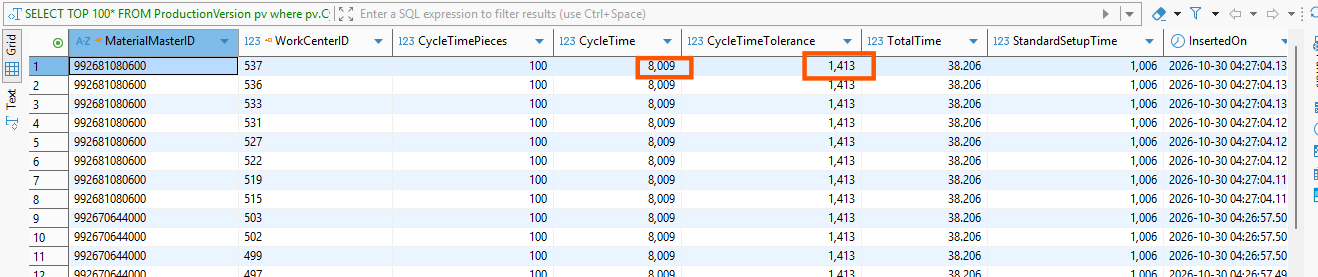
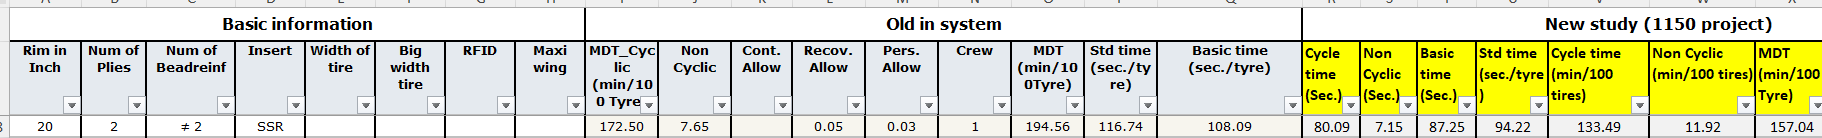
Take 992681080600 as example, "Cycle time"+"CycleTimeTolerance"=8009+1413=9422 seconds for 100 pcs tires

In [31]:
# ============================================================
# Step 20.4 - Recalculate IEStandardTotalTimePerTire
# Purpose:
# Update IE Standard Total Time in BOTH:
# 1. df_capacity_merged      -> master dataset
# 2. df_model_actualtime    -> current analysis dataset
#
# Formula:
# (CycleTimeTolerancePer100Tire
#  + IEStandardCycleTimePer100Tire) / 100
# ============================================================

# Update master dataset
df_capacity_merged["IEStandardTotalTimePerTire"] = (
    df_capacity_merged["CycleTimeTolerancePer100Tire"]
    + df_capacity_merged["IEStandardCycleTimePer100Tire"]
) / 100


# Update current analysis dataset
df_model_actualtime["IEStandardTotalTimePerTire"] = (
    df_model_actualtime["CycleTimeTolerancePer100Tire"]
    + df_model_actualtime["IEStandardCycleTimePer100Tire"]
) / 100


print("✅ IEStandardTotalTimePerTire updated in both DataFrames.")

# Quick check
display(
    df_model_actualtime[
        [
            "CycleTimeTolerancePer100Tire",
            "IEStandardCycleTimePer100Tire",
            "IEStandardTotalTimePerTire",
            "ActualTimePerTire"
        ]
    ].head(10)
)

✅ IEStandardTotalTimePerTire updated in both DataFrames.


,CycleTimeTolerancePer100Tire,IEStandardCycleTimePer100Tire,IEStandardTotalTimePerTire,ActualTimePerTire
0,628.0,4055.0,46.83,59.624000
1,1023.0,4393.0,54.16,80.058824
2,715.0,4319.0,50.34,68.936364
3,896.0,5719.0,66.15,82.558140
4,858.0,5060.0,59.18,92.019417
5,715.0,4319.0,50.34,65.426087
6,715.0,4319.0,50.34,65.426087
7,715.0,4319.0,50.34,65.426087
8,715.0,4319.0,50.34,65.426087
9,715.0,4319.0,50.34,65.426087


In [32]:
# ============================================================
# Step 21 - Recalculate Numeric Feature Correlation
# Purpose:
# 1. Use cleaned ActualTimePerTire dataset
# 2. Use the corrected IEStandardTotalTimePerTire
# 3. Calculate correlation between all numeric X and Y
# 4. Rank features by absolute correlation strength
# ============================================================

Y_COLUMN = "ActualTimePerTire"

# Select numeric columns
numeric_cols_model = df_model_actualtime.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with Y
correlation_with_y = (
    df_model_actualtime[numeric_cols_model]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_y.columns = [
    "Feature",
    "Correlation_with_ActualTimePerTire"
]

display(correlation_with_y)

,Feature,Correlation_with_ActualTimePerTire
0,IEStandardTotalTimePerTire,0.634943
1,IEStandardCycleTimePer100Tire,0.631155
2,CycleTimeTolerancePer100Tire,0.384370
3,QuantityDone,-0.328963
4,PlannedQuantity,-0.302137
5,1_belt_-_cf_epdm,-0.204323
6,RecipeID,0.088316
7,WorkCenterID,0.070503
8,postcureinflation_active,0.070381
9,OperatorUserID,0.062575


The effectiveness of IE standard time is verified with 0.639 correlation, now we change Y to be the GAP between actual time per tire with standard time per tire. 

In [33]:
# ============================================================
# Step 22 - Create New Target Variable Y: Actual vs IE Gap
# Purpose:
# 1. Keep df_capacity_merged unchanged
# 2. Create a new dataframe for GAP analysis
# 3. Define new Y as:
#    ActualTimePerTire - IEStandardTotalTimePerTire
# ============================================================

# Start from the master dataset
df_model_gap = df_capacity_merged.copy()

# Create new Y
df_model_gap["ActualVsIEGap"] = (
    df_model_gap["ActualTimePerTire"]
    - df_model_gap["IEStandardTotalTimePerTire"]
)

Y_COLUMN = "ActualVsIEGap"

print("New Y:", Y_COLUMN)
print("Dataset shape:", df_model_gap.shape)

print("\n=== GAP Statistics ===")
display(df_model_gap[Y_COLUMN].describe())

print("\nMissing values:", df_model_gap[Y_COLUMN].isna().sum())

New Y: ActualVsIEGap
Dataset shape: (61098, 159)

=== GAP Statistics ===


count    61006.000000
mean        70.161251
std       1036.734723
min        -11.367778
25%         12.741905
50%         18.569570
75%         27.359167
max      62252.810000
Name: ActualVsIEGap, dtype: float64


Missing values: 92


In [34]:
# ============================================================
# Step 23 - Clean df_model_gap Directly
# Purpose:
# 1. Remove missing ActualVsIEGap values
# 2. Remove ActualVsIEGap outliers using IQR
# 3. Update df_model_gap directly
# ============================================================

Y_COLUMN = "ActualVsIEGap"

# Original row count
original_rows = len(df_model_gap)

# 1. Remove missing Y
missing_count = df_model_gap[Y_COLUMN].isna().sum()

df_model_gap = (
    df_model_gap
    .dropna(subset=[Y_COLUMN])
    .copy()
)

# 2. Calculate IQR
Q1 = df_model_gap[Y_COLUMN].quantile(0.25)
Q3 = df_model_gap[Y_COLUMN].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Remove outliers directly from df_model_gap
df_model_gap = df_model_gap[
    df_model_gap[Y_COLUMN].between(
        lower_bound,
        upper_bound
    )
].copy()

# 4. Reset index
df_model_gap.reset_index(drop=True, inplace=True)

# 5. Check result
print("=== ActualVsIEGap Cleaning Result ===")

print(f"Lower bound       : {lower_bound:.2f}")
print(f"Upper bound       : {upper_bound:.2f}")

print("\nOriginal rows     :", original_rows)
print("Missing removed   :", missing_count)
print("Final rows        :", len(df_model_gap))
print("Total removed     :", original_rows - len(df_model_gap))

removed_pct = (
    (original_rows - len(df_model_gap))
    / original_rows
    * 100
)

print(f"Removed percentage: {removed_pct:.2f}%")

print("\n=== Clean GAP Statistics ===")
display(df_model_gap[Y_COLUMN].describe())

=== ActualVsIEGap Cleaning Result ===
Lower bound       : -9.18
Upper bound       : 49.29

Original rows     : 61098
Missing removed   : 92
Final rows        : 56186
Total removed     : 4912
Removed percentage: 8.04%

=== Clean GAP Statistics ===


count    56186.000000
mean        19.082009
std          9.933469
min         -9.098571
25%         12.284867
50%         17.598226
75%         24.590000
max         49.282424
Name: ActualVsIEGap, dtype: float64

In [35]:
# ============================================================
# Step 23 - Numeric Feature Correlation with ActualVsIEGap
# Purpose:
# 1. Use the cleaned df_model_gap
# 2. Analyze all numeric features, including joined Redshift data
# 3. Rank correlations with the new Y: ActualVsIEGap
# ============================================================

Y_COLUMN = "ActualVsIEGap"

# Select all numeric columns from the joined and cleaned dataset
numeric_cols_gap = df_model_gap.select_dtypes(
    include=["number"]
).columns

# Calculate correlation with the new Y
correlation_with_gap = (
    df_model_gap[numeric_cols_gap]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .dropna()
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

correlation_with_gap.columns = [
    "Feature",
    "Correlation_with_ActualVsIEGap"
]

print("Dataset used       : df_model_gap")
print("Rows analyzed      :", len(df_model_gap))
print("Numeric X analyzed :", len(correlation_with_gap))

display(correlation_with_gap)

Dataset used       : df_model_gap
Rows analyzed      : 56186
Numeric X analyzed : 17


,Feature,Correlation_with_ActualVsIEGap
0,ActualTimePerTire,0.752155
1,QuantityDone,-0.409159
2,PlannedQuantity,-0.388092
3,ActualProcessingTime,-0.188844
4,OperatorOverlapSeconds,-0.152855
5,1_wound_cap_ply_-_ptc_max,-0.141086
6,IEStandardCycleTimePer100Tire,0.121648
7,WorkCenterID,0.118095
8,IEStandardTotalTimePerTire,0.115730
9,1_belt_-_cf_epdm,-0.058648


In [36]:
# ============================================================
# Step 24 - Feature Classification
# Purpose:
# 1. Define target Y
# 2. Remove leakage variables from X
# 3. Only ignore TRUE identifiers / join keys
# 4. Treat Shift / WorkCenter / Recipe / Operator as categorical
# 5. Rescue Redshift tire structure/spec features
# 6. Do NOT delete any columns from df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Target Y
# ------------------------------------------------------------

target_col = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Leakage columns
# These fields directly contain or contribute to Y
# ------------------------------------------------------------

leakage_cols = [
    "ActualTimePerTire",
    "ActualProcessingTime",
    "IEStandardTotalTimePerTire"
]

leakage_cols = [
    col for col in leakage_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. TRUE identifiers / join keys
# Only fields primarily used for record identification,
# traceability or table joining
# ------------------------------------------------------------

true_identifier_cols = [
    "OrderID",
    "OrderIDLinked",
    "OrderIDCoupled",
    "PLCOrderNumber",
    "MaterialMasterID",
    "MaterialMasterIDCoupled",
    "GT_MappingKey",
    "articleid",
    "base_articleid",
    "greentire_gutsid",
    "greentire_localworkcode",
    "carcass_localworkcode",
    "OperatorEmployeeNumber",
    "OperatorWorkcenterRoleCatalogID"
]

identifier_cols = [
    col for col in true_identifier_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 4. Known categorical business features
# These may look numeric but represent categories
# ------------------------------------------------------------

known_categorical_cols = [
    "ShiftNumber",
    "WorkCenterID",
    "RecipeID",
    "OperatorUserID"
]

known_categorical_cols = [
    col for col in known_categorical_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 5. Detect all numeric columns
# ------------------------------------------------------------

all_numeric_cols = (
    df_model_gap
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 6. True numeric features
#
# Important:
# Tire structure fields such as width / weight / thickness /
# angle / diameter etc. are now kept if their dtype is numeric.
# ------------------------------------------------------------

numeric_feature_cols = [
    col for col in all_numeric_cols
    if col != target_col
    and col not in leakage_cols
    and col not in identifier_cols
    and col not in known_categorical_cols
]


# ------------------------------------------------------------
# 7. Detect non-numeric columns
# ------------------------------------------------------------

all_non_numeric_cols = (
    df_model_gap
    .select_dtypes(exclude=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 8. Categorical features
#
# Includes:
# - Shift
# - WorkCenter
# - Recipe
# - Operator
# - Tire structure/spec categorical fields
# - Redshift compound / construction / geometry etc.
# ------------------------------------------------------------

categorical_feature_cols = (
    known_categorical_cols
    +
    [
        col for col in all_non_numeric_cols
        if col not in identifier_cols
        and col not in leakage_cols
        and col != target_col
    ]
)

# Remove duplicates while preserving order
categorical_feature_cols = list(
    dict.fromkeys(categorical_feature_cols)
)


# ------------------------------------------------------------
# 9. Final safety check
# ------------------------------------------------------------

classified_cols = set(
    [target_col]
    + leakage_cols
    + identifier_cols
    + numeric_feature_cols
    + categorical_feature_cols
)

unclassified_cols = [
    col for col in df_model_gap.columns
    if col not in classified_cols
]


# ------------------------------------------------------------
# 10. Print classification summary
# ------------------------------------------------------------

print("=== Revised Feature Classification Summary ===")

print("\nTarget:")
print(target_col)


print("\nLeakage columns:", len(leakage_cols))
print(leakage_cols)


print("\nTrue Numeric Features:", len(numeric_feature_cols))
for col in numeric_feature_cols:
    print("  ", col)


print("\nCategorical Features:", len(categorical_feature_cols))
for col in categorical_feature_cols:
    print("  ", col)


print("\nTrue Identifier / Ignore Columns:", len(identifier_cols))
for col in identifier_cols:
    print("  ", col)


print("\nUnclassified Columns:", len(unclassified_cols))
print(unclassified_cols)

=== Revised Feature Classification Summary ===

Target:
ActualVsIEGap

Leakage columns: 3
['ActualTimePerTire', 'ActualProcessingTime', 'IEStandardTotalTimePerTire']

True Numeric Features: 14
   PlannedQuantity
   QuantityDone
   UserIDInsertedBy
   CycleTimePieces
   IEStandardCycleTimePer100Tire
   CycleTimeTolerancePer100Tire
   StandardSetupTimePer100Tire
   OperatorOverlapSeconds
   OperatorCoverageRatio
   from_tran
   postcureinflation_active
   1_belt_-_cf_epdm
   1_wound_cap_ply_-_ptc_min
   1_wound_cap_ply_-_ptc_max

Categorical Features: 127
   ShiftNumber
   WorkCenterID
   RecipeID
   OperatorUserID
   Comment
   ShiftDate
   ActualStartTime
   ActualEndTime
   PlannedStartTime
   PlannedEndTime
   ProdVersion
   ProdVariant
   DestinationInfo
   ETOFlag
   StatusUpdatedOn
   IsParent
   CreatedByCGMS
   InsertedOn
   UpdatedOn
   ExtTerminated
   WorkCenterNameCoupled
   PhaseInOut
   IsGAPOrder
   OrderStatus
   WorkCenterName
   OperatorStartDate
   OperatorEndDate
   

In [37]:
# ============================================================
# Step 25 - Detect Numeric-like Structure Features
# Purpose:
# 1. Check categorical tire structure/spec fields
# 2. Identify columns that are actually numeric values
# 3. Do NOT modify df_model_gap yet
# ============================================================

import pandas as pd

# Keywords that usually represent numerical physical properties
numeric_spec_keywords = [
    "width",
    "diameter",
    "thickness",
    "weight",
    "angle",
    "circumference",
    "gradient"
]

# Find candidate columns
numeric_spec_candidates = [
    col for col in categorical_feature_cols
    if any(
        keyword in col.lower()
        for keyword in numeric_spec_keywords
    )
]

conversion_check = []

for col in numeric_spec_candidates:

    original = df_model_gap[col]

    # Try numeric conversion
    converted = pd.to_numeric(
        original,
        errors="coerce"
    )

    non_null_original = original.notna().sum()
    non_null_numeric = converted.notna().sum()

    if non_null_original > 0:
        conversion_rate = (
            non_null_numeric
            / non_null_original
            * 100
        )
    else:
        conversion_rate = 0

    conversion_check.append({
        "Feature": col,
        "Current_Dtype": str(original.dtype),
        "Non_Null": non_null_original,
        "Numeric_Values": non_null_numeric,
        "Conversion_Rate_%": round(conversion_rate, 2),
        "Unique_Values": original.nunique()
    })

numeric_conversion_review = (
    pd.DataFrame(conversion_check)
    .sort_values(
        "Conversion_Rate_%",
        ascending=False
    )
)

display(numeric_conversion_review)

,Feature,Current_Dtype,Non_Null,Numeric_Values,Conversion_Rate_%,Unique_Values
0,rim_diameter,object,56186,56186,100.0,9
1,1_stage_drum_width,object,56125,56125,100.0,89
2,2_stage_drum_diameter,object,56125,56125,100.0,183
3,1_liner_-_width,object,56125,56125,100.0,24
4,1_liner_-_thickness,object,56125,56125,100.0,3
5,1_apex_-_width,object,56125,56125,100.0,12
6,1_apex_-_thickness,object,56125,56125,100.0,14
7,bead_-_bead_inner_diameter,object,56125,56125,100.0,18
8,bead_-_bead_circumference,object,56125,56125,100.0,18
9,1_ply_assembly_-_1_strip_rubber_-_width,object,672,672,100.0,2


In [38]:
# ============================================================
# Step 26 - Convert Numeric-like Specification Features
# Purpose:
# 1. Convert structure/spec fields with >=95% numeric values
# 2. Move them from categorical to numeric features
# 3. Keep low-conversion fields as categorical
# 4. Do not remove rows or columns
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Select columns with >= 95% numeric conversion rate
# ------------------------------------------------------------

spec_cols_to_numeric = (
    numeric_conversion_review.loc[
        numeric_conversion_review["Conversion_Rate_%"] >= 95,
        "Feature"
    ]
    .tolist()
)

print("Spec columns to convert:", len(spec_cols_to_numeric))


# ------------------------------------------------------------
# 2. Convert selected spec columns to numeric
# ------------------------------------------------------------

for col in spec_cols_to_numeric:
    df_model_gap[col] = pd.to_numeric(
        df_model_gap[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# 3. Update numeric feature list
# ------------------------------------------------------------

numeric_feature_cols = list(
    dict.fromkeys(
        numeric_feature_cols
        + spec_cols_to_numeric
    )
)


# ------------------------------------------------------------
# 4. Remove converted columns from categorical feature list
# ------------------------------------------------------------

categorical_feature_cols = [
    col for col in categorical_feature_cols
    if col not in spec_cols_to_numeric
]


# ------------------------------------------------------------
# 5. UserIDInsertedBy should not be a continuous numeric feature
# ------------------------------------------------------------

if "UserIDInsertedBy" in numeric_feature_cols:
    numeric_feature_cols.remove("UserIDInsertedBy")

if "UserIDInsertedBy" not in identifier_cols:
    identifier_cols.append("UserIDInsertedBy")


# ------------------------------------------------------------
# 6. Safety check
# ------------------------------------------------------------

print("\n=== Updated Feature Classification ===")

print("Numeric Features     :", len(numeric_feature_cols))
print("Categorical Features :", len(categorical_feature_cols))
print("Identifier / Ignore  :", len(identifier_cols))


print("\nConverted Spec Features:")
for col in spec_cols_to_numeric:
    print(
        f"{col:<55} -> {df_model_gap[col].dtype}"
    )


print("\nKept as Categorical:")

spec_cols_kept_categorical = [
    col for col in numeric_spec_candidates
    if col not in spec_cols_to_numeric
]

for col in spec_cols_kept_categorical:
    print(col)

Spec columns to convert: 28

=== Updated Feature Classification ===
Numeric Features     : 41
Categorical Features : 99
Identifier / Ignore  : 15

Converted Spec Features:
rim_diameter                                            -> float64
1_stage_drum_width                                      -> float64
2_stage_drum_diameter                                   -> float64
1_liner_-_width                                         -> float64
1_liner_-_thickness                                     -> float64
1_apex_-_width                                          -> float64
1_apex_-_thickness                                      -> float64
bead_-_bead_inner_diameter                              -> float64
bead_-_bead_circumference                               -> float64
1_ply_assembly_-_1_strip_rubber_-_width                 -> float64
1_ply_assembly_-_1_strip_rubber_-_thickness             -> float64
1_carcass_ply_-_width                                   -> float64
2_carcass_ply_-_width   

In [39]:
# ============================================================
# Step 27 - Feature Quality Screening
# Purpose:
# 1. Review all candidate X features
# 2. Calculate missing rate
# 3. Calculate unique value count
# 4. Check numeric and categorical feature quality
# 5. Print full result as plain text for review
# 6. Do NOT remove any features yet
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Combine all candidate X features
# ------------------------------------------------------------

candidate_features = (
    numeric_feature_cols
    + categorical_feature_cols
)


# ------------------------------------------------------------
# 2. Calculate feature quality information
# ------------------------------------------------------------

feature_quality = []

for col in candidate_features:

    total_rows = len(df_model_gap)

    non_null_count = df_model_gap[col].notna().sum()
    missing_count = df_model_gap[col].isna().sum()

    missing_pct = (
        missing_count / total_rows * 100
    )

    unique_count = df_model_gap[col].nunique(
        dropna=True
    )

    # Determine feature type
    if col in numeric_feature_cols:
        feature_type = "Numeric"
    else:
        feature_type = "Categorical"

    feature_quality.append({
        "Feature": col,
        "Type": feature_type,
        "Non_Null_Count": non_null_count,
        "Missing_%": round(missing_pct, 2),
        "Unique_Count": unique_count
    })


# ------------------------------------------------------------
# 3. Create Feature Quality dataframe
# ------------------------------------------------------------

feature_quality_df = pd.DataFrame(
    feature_quality
)


# ------------------------------------------------------------
# 4. Sort by missing rate
# ------------------------------------------------------------

feature_quality_df = (
    feature_quality_df
    .sort_values(
        by=["Missing_%", "Unique_Count"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Display summary
# ------------------------------------------------------------

print(
    "Total candidate X features:",
    len(candidate_features)
)

display(feature_quality_df)


# ------------------------------------------------------------
# 6. Print COMPLETE result as plain text
# Purpose:
# Easy to copy and paste for detailed review
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("FULL FEATURE QUALITY RESULT")
print("=" * 100)

print(
    feature_quality_df.to_string(
        index=False
    )
)

Total candidate X features: 140


,Feature,Type,Non_Null_Count,Missing_%,Unique_Count
0,CreatedByCGMS,Categorical,0,100.00,0
1,stamping_code,Categorical,0,100.00,0
2,2_belt_ply_assembly_-_1_strip_rubber_-_thickness,Numeric,17,99.97,1
3,2_belt_ply_assembly_-_1_strip_rubber_-_width,Numeric,17,99.97,1
4,2_belt_ply_assembly_-_1_strip_rubber_-_bom_com...,Categorical,17,99.97,1
...,...,...,...,...,...
135,InsertedOn,Categorical,56186,0.00,21708
136,ActualStartTime,Categorical,56186,0.00,21742
137,ActualEndTime,Categorical,56186,0.00,21742
138,StatusUpdatedOn,Categorical,56186,0.00,21742




FULL FEATURE QUALITY RESULT
                                                     Feature        Type  Non_Null_Count  Missing_%  Unique_Count
                                               CreatedByCGMS Categorical               0     100.00             0
                                               stamping_code Categorical               0     100.00             0
            2_belt_ply_assembly_-_1_strip_rubber_-_thickness     Numeric              17      99.97             1
                2_belt_ply_assembly_-_1_strip_rubber_-_width     Numeric              17      99.97             1
2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting Categorical              17      99.97             1
                 1_ply_assembly_-_1_strip_rubber_-_thickness     Numeric             672      98.80             1
                     1_ply_assembly_-_1_strip_rubber_-_width     Numeric             672      98.80             2
                  1_ply_assembly_-_1_strip_rubber_-_compou

In [40]:
# ============================================================
# Step 28 - Feature Engineering & Initial Cleanup
# Purpose:
# 1. Remove confirmed unusable / constant / system fields
# 2. Remove raw timestamp fields with leakage or low business value
# 3. Extract useful time features
# 4. Create structure-presence features from optional structures
# 5. Update df_model_gap directly
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Create useful time features BEFORE dropping raw timestamps
# ------------------------------------------------------------

# Convert to datetime safely
df_model_gap["ActualStartTime"] = pd.to_datetime(
    df_model_gap["ActualStartTime"],
    errors="coerce"
)

df_model_gap["PlannedStartTime"] = pd.to_datetime(
    df_model_gap["PlannedStartTime"],
    errors="coerce"
)

# Actual production timing features
df_model_gap["ActualStartHour"] = (
    df_model_gap["ActualStartTime"].dt.hour
)

df_model_gap["ActualStartDayOfWeek"] = (
    df_model_gap["ActualStartTime"].dt.dayofweek
)

df_model_gap["ActualStartMonth"] = (
    df_model_gap["ActualStartTime"].dt.month
)

# Planned production timing features
df_model_gap["PlannedStartHour"] = (
    df_model_gap["PlannedStartTime"].dt.hour
)

df_model_gap["PlannedStartDayOfWeek"] = (
    df_model_gap["PlannedStartTime"].dt.dayofweek
)

df_model_gap["PlannedStartMonth"] = (
    df_model_gap["PlannedStartTime"].dt.month
)


# ------------------------------------------------------------
# 2. Create optional tire-structure presence features
# Missing means that the structure is not present
# ------------------------------------------------------------

# 1st Ply Assembly - Strip Rubber
df_model_gap["Has_1st_Ply_Strip_Rubber"] = (
    df_model_gap[
        "1_ply_assembly_-_1_strip_rubber_-_compound"
    ]
    .notna()
    .astype(int)
)


# 2nd Belt - Strip Rubber
df_model_gap["Has_2nd_Belt_Strip_Rubber"] = (
    df_model_gap[
        "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting"
    ]
    .notna()
    .astype(int)
)


# 2nd Carcass Ply
df_model_gap["Has_2nd_Carcass_Ply"] = (
    df_model_gap[
        "2_carcass_ply_-_cf_code"
    ]
    .notna()
    .astype(int)
)


# Bead Reinforcement
df_model_gap["Has_Bead_Reinforcement"] = (
    df_model_gap[
        "1_bead_reinforcement_-_cf_code"
    ]
    .notna()
    .astype(int)
)


# ------------------------------------------------------------
# 3. Fields confirmed for removal
# ------------------------------------------------------------

cols_to_drop = [

    # Completely empty
    "CreatedByCGMS",
    "stamping_code",

    # Random Redshift spec - confirmed unreliable
    "enrichment_type",

    # Constant / no variation
    "CycleTimePieces",
    "StandardSetupTimePer100Tire",
    "from_tran",
    "ssr_flag",
    "OperatorIsTeamLeader",
    "IsParent",
    "drum_profile-no",
    "1_belt_-_cf_compound_top",
    "1_belt_ply_assembly_-_1_strip_rubber_-_compound",
    "1_bead_reinforcement_-_cf_code",
    "ProdVariant",
    "ETOFlag",
    "IsGAPOrder",
    "OrderStatus",
    "plant_dot_code",
    "base_plant_dot_code",
    "product_line_id",
    "tire_group_description",

    # Raw production timestamps
    "ActualStartTime",
    "ActualEndTime",
    "PlannedStartTime",
    "PlannedEndTime",

    # Operator raw timestamps
    # Keep OperatorOverlapSeconds + OperatorCoverageRatio instead
    "OperatorStartDate",
    "OperatorEndDate",
    "OperatorOverlapStart",
    "OperatorOverlapEnd",

    # System / master-data timestamps
    "InsertedOn",
    "UpdatedOn",
    "StatusUpdatedOn",
    "src_created_timestamp",
    "src_last_modified_timestamp",
    "base_src_created_timestamp",
    "base_src_last_modified_timestamp",
    "created_utc_timestamp",
    "last_modified_utc_timestamp",

    # Extremely sparse original fields replaced by Has_xxx
    "1_ply_assembly_-_1_strip_rubber_-_width",
    "1_ply_assembly_-_1_strip_rubber_-_thickness",

    "2_belt_ply_assembly_-_1_strip_rubber_-_thickness",
    "2_belt_ply_assembly_-_1_strip_rubber_-_width",
    "2_belt_ply_assembly_-_1_strip_rubber_-_bom_component_setting"
]


# Only drop fields that actually exist
cols_to_drop = [
    col for col in cols_to_drop
    if col in df_model_gap.columns
]

df_model_gap.drop(
    columns=cols_to_drop,
    inplace=True
)


# ------------------------------------------------------------
# 4. Check result
# ------------------------------------------------------------

print("=== Step 28 Result ===")

print("Rows remaining    :", len(df_model_gap))
print("Columns remaining :", len(df_model_gap.columns))
print("Columns removed   :", len(cols_to_drop))


print("\n=== New Time Features ===")

time_features = [
    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth",
    "PlannedStartHour",
    "PlannedStartDayOfWeek",
    "PlannedStartMonth"
]

display(
    df_model_gap[time_features]
    .describe()
    .T
)


print("\n=== New Structure Presence Features ===")

structure_presence_features = [
    "Has_1st_Ply_Strip_Rubber",
    "Has_2nd_Belt_Strip_Rubber",
    "Has_2nd_Carcass_Ply",
    "Has_Bead_Reinforcement"
]

for col in structure_presence_features:
    print(f"\n{col}")
    print(df_model_gap[col].value_counts(dropna=False))

=== Step 28 Result ===
Rows remaining    : 56186
Columns remaining : 126
Columns removed   : 43

=== New Time Features ===


,count,mean,std,min,25%,50%,75%,max
ActualStartHour,56186.0,12.074307,6.906297,0.0,6.0,12.0,18.0,23.0
ActualStartDayOfWeek,56186.0,3.046310,2.020671,0.0,1.0,3.0,5.0,6.0
ActualStartMonth,56186.0,9.690190,0.736132,8.0,9.0,10.0,10.0,11.0
PlannedStartHour,56186.0,11.643488,6.910230,0.0,6.0,12.0,18.0,23.0
PlannedStartDayOfWeek,56186.0,3.050244,2.019136,0.0,1.0,3.0,5.0,6.0
PlannedStartMonth,56186.0,9.690439,0.735874,8.0,9.0,10.0,10.0,11.0



=== New Structure Presence Features ===

Has_1st_Ply_Strip_Rubber
Has_1st_Ply_Strip_Rubber
0    55514
1      672
Name: count, dtype: int64

Has_2nd_Belt_Strip_Rubber
Has_2nd_Belt_Strip_Rubber
0    56169
1       17
Name: count, dtype: int64

Has_2nd_Carcass_Ply
Has_2nd_Carcass_Ply
0    49860
1     6326
Name: count, dtype: int64

Has_Bead_Reinforcement
Has_Bead_Reinforcement
0    50655
1     5531
Name: count, dtype: int64


In [41]:
# ============================================================
# Step 29 - Build Final Feature List
# Purpose:
# 1. Rebuild feature lists after Step 28 cleanup
# 2. Separate Numeric / Categorical / Identifier / Leakage
# 3. Include newly engineered time and structure features
# 4. Do NOT modify df_model_gap
# ============================================================

# ------------------------------------------------------------
# 1. Target
# ------------------------------------------------------------

target_col = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Leakage features
# Directly involved in the target calculation
# ------------------------------------------------------------

leakage_cols = [
    "ActualTimePerTire",
    "ActualProcessingTime",
    "IEStandardTotalTimePerTire"
]

leakage_cols = [
    col for col in leakage_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. True identifiers / join keys
# Keep in dataset for traceability, but do NOT use as model X
# ------------------------------------------------------------

identifier_cols = [
    "OrderID",
    "OrderIDLinked",
    "OrderIDCoupled",
    "PLCOrderNumber",
    "MaterialMasterID",
    "MaterialMasterIDCoupled",
    "GT_MappingKey",
    "articleid",
    "base_articleid",
    "greentire_gutsid",
    "greentire_localworkcode",
    "carcass_localworkcode",
    "OperatorEmployeeNumber",
    "OperatorWorkcenterRoleCatalogID",
    "UserIDInsertedBy"
]

identifier_cols = [
    col for col in identifier_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 4. Business categorical features
# These may be stored as numbers but represent categories
# ------------------------------------------------------------

business_categorical_cols = [
    "ShiftNumber",
    "WorkCenterID",
    "RecipeID",
    "OperatorUserID",

    # Engineered time features
    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth",
    "PlannedStartHour",
    "PlannedStartDayOfWeek",
    "PlannedStartMonth"
]

business_categorical_cols = [
    col for col in business_categorical_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 5. Automatically identify current numeric columns
# ------------------------------------------------------------

all_numeric_cols = (
    df_model_gap
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 6. Final Numeric Features
# ------------------------------------------------------------

numeric_feature_cols = [
    col for col in all_numeric_cols
    if col != target_col
    and col not in leakage_cols
    and col not in identifier_cols
    and col not in business_categorical_cols
]


# ------------------------------------------------------------
# 7. Automatically identify current non-numeric columns
# ------------------------------------------------------------

all_non_numeric_cols = (
    df_model_gap
    .select_dtypes(exclude=["number"])
    .columns
    .tolist()
)


# ------------------------------------------------------------
# 8. Final Categorical Features
# ------------------------------------------------------------

categorical_feature_cols = (
    business_categorical_cols
    + [
        col for col in all_non_numeric_cols
        if col != target_col
        and col not in leakage_cols
        and col not in identifier_cols
    ]
)

# Remove duplicates
categorical_feature_cols = list(
    dict.fromkeys(categorical_feature_cols)
)


# ------------------------------------------------------------
# 9. Final model feature list
# ------------------------------------------------------------

final_feature_cols = (
    numeric_feature_cols
    + categorical_feature_cols
)


# ------------------------------------------------------------
# 10. Safety checks
# ------------------------------------------------------------

classified_cols = set(
    [target_col]
    + leakage_cols
    + identifier_cols
    + final_feature_cols
)

unclassified_cols = [
    col for col in df_model_gap.columns
    if col not in classified_cols
]

duplicate_features = (
    pd.Series(final_feature_cols)
    .value_counts()
)

duplicate_features = duplicate_features[
    duplicate_features > 1
]


# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------

print("=== Step 29 - Final Feature List ===")

print("\nDataset:")
print("Rows    :", len(df_model_gap))
print("Columns :", len(df_model_gap.columns))

print("\nTarget:")
print(target_col)

print("\nNumeric X       :", len(numeric_feature_cols))
print("Categorical X   :", len(categorical_feature_cols))
print("Total Model X   :", len(final_feature_cols))

print("\nLeakage / Excluded:", len(leakage_cols))
print(leakage_cols)

print("\nIdentifier / Traceability:", len(identifier_cols))
print(identifier_cols)

print("\nUnclassified Columns:", len(unclassified_cols))
print(unclassified_cols)

print("\nDuplicate Features:", len(duplicate_features))
print(duplicate_features.index.tolist())


# ------------------------------------------------------------
# 12. Display final Numeric X
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL NUMERIC FEATURES")
print("=" * 80)

for i, col in enumerate(numeric_feature_cols, 1):
    print(f"{i:2}. {col}")


# ------------------------------------------------------------
# 13. Display final Categorical X
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL CATEGORICAL FEATURES")
print("=" * 80)

for i, col in enumerate(categorical_feature_cols, 1):
    print(f"{i:3}. {col}")

=== Step 29 - Final Feature List ===

Dataset:
Rows    : 56186
Columns : 126

Target:
ActualVsIEGap

Numeric X       : 38
Categorical X   : 69
Total Model X   : 107

Leakage / Excluded: 3
['ActualTimePerTire', 'ActualProcessingTime', 'IEStandardTotalTimePerTire']

Identifier / Traceability: 15
['OrderID', 'OrderIDLinked', 'OrderIDCoupled', 'PLCOrderNumber', 'MaterialMasterID', 'MaterialMasterIDCoupled', 'GT_MappingKey', 'articleid', 'base_articleid', 'greentire_gutsid', 'greentire_localworkcode', 'carcass_localworkcode', 'OperatorEmployeeNumber', 'OperatorWorkcenterRoleCatalogID', 'UserIDInsertedBy']

Unclassified Columns: 0
[]

Duplicate Features: 0
[]

FINAL NUMERIC FEATURES
 1. PlannedQuantity
 2. QuantityDone
 3. IEStandardCycleTimePer100Tire
 4. CycleTimeTolerancePer100Tire
 5. OperatorOverlapSeconds
 6. OperatorCoverageRatio
 7. rim_diameter
 8. postcureinflation_active
 9. 1_stage_drum_width
10. 2_stage_drum_diameter
11. 1_liner_-_width
12. 1_liner_-_thickness
13. 1_apex_-_width

In [42]:
# ============================================================
# Step 30 - Numeric Feature Analysis with ActualVsIEGap
# Purpose:
# 1. Analyze the final 38 numeric features
# 2. Calculate Pearson correlation with ActualVsIEGap
# 3. Rank features by absolute correlation strength
# 4. Keep correlation direction for business interpretation
# 5. Do NOT modify df_model_gap
# ============================================================

import pandas as pd

Y_COLUMN = "ActualVsIEGap"


# ------------------------------------------------------------
# 1. Calculate correlation for final numeric features only
# ------------------------------------------------------------

numeric_correlation = (
    df_model_gap[
        numeric_feature_cols + [Y_COLUMN]
    ]
    .corr()[Y_COLUMN]
    .drop(Y_COLUMN)
    .reset_index()
)

numeric_correlation.columns = [
    "Feature",
    "Correlation"
]


# ------------------------------------------------------------
# 2. Add absolute correlation for ranking
# ------------------------------------------------------------

numeric_correlation["Abs_Correlation"] = (
    numeric_correlation["Correlation"].abs()
)


# ------------------------------------------------------------
# 3. Add data coverage information
# ------------------------------------------------------------

numeric_correlation["Non_Null_Count"] = (
    numeric_correlation["Feature"]
    .map(
        df_model_gap[numeric_feature_cols]
        .notna()
        .sum()
    )
)

numeric_correlation["Missing_%"] = (
    100
    - numeric_correlation["Non_Null_Count"]
    / len(df_model_gap)
    * 100
).round(2)


# ------------------------------------------------------------
# 4. Sort by correlation strength
# ------------------------------------------------------------

numeric_correlation = (
    numeric_correlation
    .sort_values(
        "Abs_Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Display result
# ------------------------------------------------------------

print("=== Step 30 - Numeric Feature Analysis ===")

print("Target                 :", Y_COLUMN)
print("Numeric features tested:", len(numeric_feature_cols))
print("Rows                   :", len(df_model_gap))

display(numeric_correlation)


# ------------------------------------------------------------
# 6. Print complete result for easy review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL NUMERIC CORRELATION RESULT")
print("=" * 100)

print(
    numeric_correlation.to_string(
        index=False
    )
)

=== Step 30 - Numeric Feature Analysis ===
Target                 : ActualVsIEGap
Numeric features tested: 38
Rows                   : 56186


,Feature,Correlation,Abs_Correlation,Non_Null_Count,Missing_%
0,QuantityDone,-0.409159,0.409159,56186,0.00
1,PlannedQuantity,-0.388092,0.388092,56186,0.00
2,2_carcass_ply_-_thickness,-0.251021,0.251021,6326,88.74
3,1_tread_base_-_width,0.186329,0.186329,56125,0.11
4,OperatorOverlapSeconds,-0.152855,0.152855,53855,4.15
5,1_wound_cap_ply_-_ptc_max,-0.141086,0.141086,56084,0.18
6,IEStandardCycleTimePer100Tire,0.121648,0.121648,56186,0.00
7,2_carcass_ply_-_width,-0.111060,0.111060,6326,88.74
8,1_bead_reinforcement_-_width,-0.106708,0.106708,5531,90.16
9,Has_2nd_Carcass_Ply,0.098695,0.098695,56186,0.00



FULL NUMERIC CORRELATION RESULT
                                     Feature  Correlation  Abs_Correlation  Non_Null_Count  Missing_%
                                QuantityDone    -0.409159         0.409159           56186       0.00
                             PlannedQuantity    -0.388092         0.388092           56186       0.00
                   2_carcass_ply_-_thickness    -0.251021         0.251021            6326      88.74
                        1_tread_base_-_width     0.186329         0.186329           56125       0.11
                      OperatorOverlapSeconds    -0.152855         0.152855           53855       4.15
                   1_wound_cap_ply_-_ptc_max    -0.141086         0.141086           56084       0.18
               IEStandardCycleTimePer100Tire     0.121648         0.121648           56186       0.00
                       2_carcass_ply_-_width    -0.111060         0.111060            6326      88.74
                1_bead_reinforcement_-_width    -

In [43]:
# ============================================================
# Step 31 - Categorical Feature Analysis with ActualVsIEGap
# Purpose:
# 1. Analyze final categorical features
# 2. Measure how much Y varies across categories
# 3. Calculate Eta Squared (η²) as effect size
# 4. Track category count and data coverage
# 5. Do NOT modify df_model_gap
# ============================================================

import pandas as pd
import numpy as np

Y_COLUMN = "ActualVsIEGap"

categorical_analysis = []


# ------------------------------------------------------------
# 1. Calculate Eta Squared for each categorical feature
# ------------------------------------------------------------

for col in categorical_feature_cols:

    temp = df_model_gap[[col, Y_COLUMN]].dropna()

    if len(temp) == 0:
        continue

    n_unique = temp[col].nunique()

    # Need at least 2 categories
    if n_unique <= 1:
        continue

    # Overall Y mean
    overall_mean = temp[Y_COLUMN].mean()

    # Total sum of squares
    ss_total = (
        (temp[Y_COLUMN] - overall_mean) ** 2
    ).sum()

    # Between-group sum of squares
    group_stats = (
        temp
        .groupby(col, observed=True)[Y_COLUMN]
        .agg(["count", "mean"])
    )

    ss_between = (
        group_stats["count"]
        * (group_stats["mean"] - overall_mean) ** 2
    ).sum()

    # Eta squared
    eta_squared = (
        ss_between / ss_total
        if ss_total > 0
        else np.nan
    )

    non_null_count = df_model_gap[col].notna().sum()

    missing_pct = (
        1 - non_null_count / len(df_model_gap)
    ) * 100

    categorical_analysis.append({
        "Feature": col,
        "Eta_Squared": eta_squared,
        "Unique_Categories": n_unique,
        "Non_Null_Count": non_null_count,
        "Missing_%": round(missing_pct, 2)
    })


# ------------------------------------------------------------
# 2. Create result dataframe
# ------------------------------------------------------------

categorical_analysis_df = pd.DataFrame(
    categorical_analysis
)


# ------------------------------------------------------------
# 3. Rank by Eta Squared
# ------------------------------------------------------------

categorical_analysis_df = (
    categorical_analysis_df
    .sort_values(
        "Eta_Squared",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Display result
# ------------------------------------------------------------

print("=== Step 31 - Categorical Feature Analysis ===")

print("Target                      :", Y_COLUMN)
print("Categorical features tested :", len(categorical_analysis_df))
print("Rows                        :", len(df_model_gap))

display(categorical_analysis_df)


# ------------------------------------------------------------
# 5. Print complete result for review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL CATEGORICAL FEATURE ANALYSIS")
print("=" * 100)

print(
    categorical_analysis_df.to_string(
        index=False
    )
)

=== Step 31 - Categorical Feature Analysis ===
Target                      : ActualVsIEGap
Categorical features tested : 69
Rows                        : 56186


,Feature,Eta_Squared,Unique_Categories,Non_Null_Count,Missing_%
0,RecipeID,0.350717,736,56186,0.00
1,greentire_code,0.327904,639,56186,0.00
2,article_pk,0.327904,639,56186,0.00
3,article7,0.327639,632,56186,0.00
4,base_article7,0.327618,631,56186,0.00
...,...,...,...,...,...
64,ActualStartMonth,0.000617,4,56186,0.00
65,ExtTerminated,0.000119,2,56186,0.00
66,1_sidewall_profile_-_compound,0.000116,3,56125,0.11
67,2_belt_-_gradient,0.000001,2,56125,0.11



FULL CATEGORICAL FEATURE ANALYSIS
                                              Feature  Eta_Squared  Unique_Categories  Non_Null_Count  Missing_%
                                             RecipeID     0.350717                736           56186       0.00
                                       greentire_code     0.327904                639           56186       0.00
                                           article_pk     0.327904                639           56186       0.00
                                             article7     0.327639                632           56186       0.00
                                        base_article7     0.327618                631           56186       0.00
                                           color_code     0.326673                623           56186       0.00
                                           local_code     0.326673                623           56186       0.00
                                          description     0.3

In [44]:
# ============================================================
# Step 32 - Categorical Feature Redundancy & Frequency Check
# Purpose:
# 1. Check redundant categorical features
# 2. Check high-cardinality categorical features
# 3. Identify rare categories
# 4. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Check WorkCenter-related redundancy
# ------------------------------------------------------------

workcenter_cols = [
    "WorkCenterID",
    "WorkCenterName",
    "WorkCenterNameCoupled",
    "ProdVersion"
]

workcenter_cols = [
    col for col in workcenter_cols
    if col in df_model_gap.columns
]

print("=" * 80)
print("WORKCENTER RELATIONSHIP CHECK")
print("=" * 80)

display(
    df_model_gap[workcenter_cols]
    .drop_duplicates()
    .sort_values("WorkCenterID")
)


# ------------------------------------------------------------
# 2. Check selected high-cardinality categorical features
# ------------------------------------------------------------

high_cardinality_cols = [
    "RecipeID",
    "OperatorUserID",
    "greentire_code",
    "article_pk",
    "article7",
    "base_article7",
    "color_code",
    "local_code",
    "description",
    "tire_release_note",
    "tire_size"
]

high_cardinality_cols = [
    col for col in high_cardinality_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 3. Calculate frequency statistics
# ------------------------------------------------------------

frequency_summary = []

for col in high_cardinality_cols:

    counts = df_model_gap[col].value_counts(
        dropna=True
    )

    total_categories = len(counts)

    categories_lt_5 = (counts < 5).sum()
    categories_lt_10 = (counts < 10).sum()
    categories_lt_30 = (counts < 30).sum()

    rows_in_lt_10 = counts[
        counts < 10
    ].sum()

    frequency_summary.append({
        "Feature": col,
        "Unique_Categories": total_categories,
        "Min_Category_Count": counts.min(),
        "Median_Category_Count": counts.median(),
        "Max_Category_Count": counts.max(),
        "Categories_<5": categories_lt_5,
        "Categories_<10": categories_lt_10,
        "Categories_<30": categories_lt_30,
        "Rows_in_Categories_<10": rows_in_lt_10
    })


frequency_summary_df = pd.DataFrame(
    frequency_summary
)


# ------------------------------------------------------------
# 4. Add Eta Squared from Step 31
# ------------------------------------------------------------

frequency_summary_df = frequency_summary_df.merge(
    categorical_analysis_df[
        [
            "Feature",
            "Eta_Squared"
        ]
    ],
    on="Feature",
    how="left"
)


# ------------------------------------------------------------
# 5. Sort by Eta Squared
# ------------------------------------------------------------

frequency_summary_df = (
    frequency_summary_df
    .sort_values(
        "Eta_Squared",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Display result
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("HIGH-CARDINALITY FEATURE SUMMARY")
print("=" * 80)

display(frequency_summary_df)


# ------------------------------------------------------------
# 7. Print full result for easy review
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("FULL HIGH-CARDINALITY FEATURE SUMMARY")
print("=" * 100)

print(
    frequency_summary_df.to_string(
        index=False
    )
)

WORKCENTER RELATIONSHIP CHECK


,WorkCenterID,WorkCenterName,WorkCenterNameCoupled,ProdVersion
47,11,TB284,TB184,2841
36780,11,TB284,None,2841
39540,11,TB284,TB173,2841
270,463,TB221,TB121,2211
39873,463,TB221,None,2211
...,...,...,...,...
876,692,TB2B3,TB1B3,2B31
893,694,TB2B2,TB1B2,2B21
425,718,TB2C3,TB1C3,2C31
428,722,TB2C1,TB1C1,2C11




HIGH-CARDINALITY FEATURE SUMMARY


,Feature,Unique_Categories,Min_Category_Count,Median_Category_Count,Max_Category_Count,Categories_<5,Categories_<10,Categories_<30,Rows_in_Categories_<10,Eta_Squared
0,RecipeID,736,1,36.0,716,50,118,320,593,0.350717
1,greentire_code,639,1,42.0,991,29,72,249,369,0.327904
2,article_pk,639,1,42.0,991,29,72,249,369,0.327904
3,article7,632,1,42.5,991,28,69,246,351,0.327639
4,base_article7,631,1,43.0,991,28,69,244,351,0.327618
5,local_code,623,1,43.0,991,26,66,236,337,0.326673
6,color_code,623,1,43.0,991,26,66,236,337,0.326673
7,description,602,1,43.0,1291,27,66,232,332,0.321059
8,tire_release_note,578,1,46.5,991,23,56,215,274,0.320918
9,tire_size,147,1,194.0,3015,1,6,22,35,0.173819




FULL HIGH-CARDINALITY FEATURE SUMMARY
          Feature  Unique_Categories  Min_Category_Count  Median_Category_Count  Max_Category_Count  Categories_<5  Categories_<10  Categories_<30  Rows_in_Categories_<10  Eta_Squared
         RecipeID                736                   1                   36.0                 716             50             118             320                     593     0.350717
   greentire_code                639                   1                   42.0                 991             29              72             249                     369     0.327904
       article_pk                639                   1                   42.0                 991             29              72             249                     369     0.327904
         article7                632                   1                   42.5                 991             28              69             246                     351     0.327639
    base_article7                631    

In [45]:
# ============================================================
# Step 33 - Build Model-ready Feature List
# Purpose:
# 1. Start from the final feature lists created in Step 29
# 2. Remove redundant WorkCenter representations
# 3. Remove Product / Article proxy identifiers
# 4. Keep Recipe, WorkCenter, Operator and Tire Structure
# 5. Keep df_model_gap unchanged
# 6. Prepare final X / y feature lists for modeling
# ============================================================


# ------------------------------------------------------------
# 1. Target
# ------------------------------------------------------------

Y_COLUMN = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Exclude redundant WorkCenter-related features
#
# WorkCenterID is kept as the main machine feature.
# WorkCenterNameCoupled is kept because it contains
# additional coupled-machine information.
# ------------------------------------------------------------

redundant_workcenter_cols = [
    "WorkCenterName",
    "ProdVersion"
]


# ------------------------------------------------------------
# 3. Exclude Product / Article proxy features
#
# These features mainly identify a specific GT / Article.
# We prefer physical structure/spec features so that
# the model has better potential to generalize to new GTs.
# ------------------------------------------------------------

product_proxy_cols = [
    "greentire_code",
    "article_pk",
    "article7",
    "base_article7",
    "color_code",
    "local_code",
    "description",
    "tire_release_note",
    "release_note_number"
]


# ------------------------------------------------------------
# 4. Other fields not recommended for first model
#
# ShiftDate is effectively a calendar identifier with
# many categories.
#
# release_date and spec_issue fields are master-data/version
# information rather than direct physical structure.
# Keep the columns in df_model_gap, but exclude from Model V1.
# ------------------------------------------------------------

model_v1_exclude_cols = [
    "ShiftDate",
    "release_date",
    "spec_issue",
    "base_spec_issue"
]


# ------------------------------------------------------------
# 5. Combine Model V1 exclusions
# ------------------------------------------------------------

model_exclude_cols = list(
    dict.fromkeys(
        redundant_workcenter_cols
        + product_proxy_cols
        + model_v1_exclude_cols
    )
)

# Only keep exclusions that actually exist
model_exclude_cols = [
    col for col in model_exclude_cols
    if col in df_model_gap.columns
]


# ------------------------------------------------------------
# 6. Model-ready Numeric Features
#
# Keep all final numeric features from Step 29.
# QuantityDone is intentionally retained for Model V1.
# We will later compare a model without QuantityDone because
# it participates in the ActualTimePerTire calculation.
# ------------------------------------------------------------

model_numeric_features = [
    col for col in numeric_feature_cols
    if col not in model_exclude_cols
]


# ------------------------------------------------------------
# 7. Model-ready Categorical Features
# ------------------------------------------------------------

model_categorical_features = [
    col for col in categorical_feature_cols
    if col not in model_exclude_cols
]


# ------------------------------------------------------------
# 8. Final Model X
# ------------------------------------------------------------

model_feature_cols = (
    model_numeric_features
    + model_categorical_features
)


# ------------------------------------------------------------
# 9. Create X and y
#
# This does NOT change df_model_gap.
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    Y_COLUMN
].copy()


# ------------------------------------------------------------
# 10. Safety checks
# ------------------------------------------------------------

leakage_in_X = [
    col for col in leakage_cols
    if col in X.columns
]

identifier_in_X = [
    col for col in identifier_cols
    if col in X.columns
]

duplicate_X = (
    pd.Series(model_feature_cols)
    .value_counts()
)

duplicate_X = duplicate_X[
    duplicate_X > 1
]


# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------

print("=== Step 33 - Model-ready Feature List ===")

print("\nDataset:")
print("Rows:", len(df_model_gap))

print("\nTarget:")
print(Y_COLUMN)

print("\nModel Numeric X     :", len(model_numeric_features))
print("Model Categorical X :", len(model_categorical_features))
print("Total Model X       :", len(model_feature_cols))

print("\nExcluded from Model V1:")
for col in model_exclude_cols:
    print("  ", col)

print("\nSafety Check")
print("Leakage in X    :", leakage_in_X)
print("Identifiers in X:", identifier_in_X)
print("Duplicate X     :", duplicate_X.index.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

=== Step 33 - Model-ready Feature List ===

Dataset:
Rows: 56186

Target:
ActualVsIEGap

Model Numeric X     : 38
Model Categorical X : 54
Total Model X       : 92

Excluded from Model V1:
   WorkCenterName
   ProdVersion
   greentire_code
   article_pk
   article7
   base_article7
   color_code
   local_code
   description
   tire_release_note
   release_note_number
   ShiftDate
   release_date
   spec_issue
   base_spec_issue

Safety Check
Leakage in X    : []
Identifiers in X: []
Duplicate X     : []

X shape: (56186, 92)
y shape: (56186,)


In [46]:
# ============================================================
# Step 34 - Check Missing Values in Model-ready Features
# Purpose:
# 1. Check missing values across all 92 model features
# 2. Separate Numeric and Categorical missing-value summaries
# 3. Review coverage before deciding imputation strategy
# 4. Do NOT modify X or df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Build missing-value summary for all Model X
# ------------------------------------------------------------

missing_summary = pd.DataFrame({
    "Feature": model_feature_cols,
    "Type": [
        "Numeric" if col in model_numeric_features else "Categorical"
        for col in model_feature_cols
    ],
    "Missing_Count": [
        X[col].isna().sum()
        for col in model_feature_cols
    ],
    "Missing_%": [
        X[col].isna().mean() * 100
        for col in model_feature_cols
    ],
    "Non_Null_Count": [
        X[col].notna().sum()
        for col in model_feature_cols
    ],
    "Unique_Count": [
        X[col].nunique(dropna=True)
        for col in model_feature_cols
    ]
})


# ------------------------------------------------------------
# 2. Round and sort by missing rate
# ------------------------------------------------------------

missing_summary["Missing_%"] = (
    missing_summary["Missing_%"]
    .round(2)
)

missing_summary = (
    missing_summary
    .sort_values(
        ["Missing_%", "Type"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Overall summary
# ------------------------------------------------------------

features_with_missing = (
    missing_summary["Missing_Count"] > 0
).sum()

features_without_missing = (
    missing_summary["Missing_Count"] == 0
).sum()

print("=== Step 34 - Missing Value Check ===")

print("Total Model X          :", len(model_feature_cols))
print("Features with missing  :", features_with_missing)
print("Features without missing:", features_without_missing)


# ------------------------------------------------------------
# 4. Numeric Feature Missing Summary
# ------------------------------------------------------------

numeric_missing_summary = missing_summary[
    (missing_summary["Type"] == "Numeric")
    & (missing_summary["Missing_Count"] > 0)
].copy()

print("\n" + "=" * 80)
print("NUMERIC FEATURES WITH MISSING VALUES")
print("=" * 80)

display(numeric_missing_summary)


# ------------------------------------------------------------
# 5. Categorical Feature Missing Summary
# ------------------------------------------------------------

categorical_missing_summary = missing_summary[
    (missing_summary["Type"] == "Categorical")
    & (missing_summary["Missing_Count"] > 0)
].copy()

print("\n" + "=" * 80)
print("CATEGORICAL FEATURES WITH MISSING VALUES")
print("=" * 80)

display(categorical_missing_summary)


# ------------------------------------------------------------
# 6. Print complete missing-value result
# Purpose: Easy to copy for detailed review
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL MODEL FEATURE MISSING VALUE RESULT")
print("=" * 100)

print(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].to_string(index=False)
)

=== Step 34 - Missing Value Check ===
Total Model X          : 92
Features with missing  : 60
Features without missing: 32

NUMERIC FEATURES WITH MISSING VALUES


,Feature,Type,Missing_Count,Missing_%,Non_Null_Count,Unique_Count
1,1_bead_reinforcement_-_angle,Numeric,50655,90.16,5531,1
2,1_bead_reinforcement_-_width,Numeric,50655,90.16,5531,3
4,2_carcass_ply_-_width,Numeric,49860,88.74,6326,29
5,2_carcass_ply_-_thickness,Numeric,49860,88.74,6326,5
6,1_wound_cap_ply_-_ptc_min,Numeric,5253,9.35,50933,3
8,OperatorOverlapSeconds,Numeric,2331,4.15,53855,16345
9,OperatorCoverageRatio,Numeric,2331,4.15,53855,28615
17,1_wound_cap_ply_-_ptc_max,Numeric,102,0.18,56084,3
40,1_stage_drum_width,Numeric,61,0.11,56125,89
41,2_stage_drum_diameter,Numeric,61,0.11,56125,183



CATEGORICAL FEATURES WITH MISSING VALUES


,Feature,Type,Missing_Count,Missing_%,Non_Null_Count,Unique_Count
0,1_ply_assembly_-_1_strip_rubber_-_compound,Categorical,55514,98.80,672,2
3,2_carcass_ply_-_cf_code,Categorical,49860,88.74,6326,8
7,OperatorUserID,Categorical,2331,4.15,53855,259
10,bladder_code,Categorical,949,1.69,55237,31
11,marketing_line,Categorical,476,0.85,55710,48
12,WorkCenterNameCoupled,Categorical,181,0.32,56005,45
13,article_development_cluster_name,Categorical,161,0.29,56025,12
14,article_cluster_link_status,Categorical,161,0.29,56025,4
15,base_article_development_cluster_name,Categorical,161,0.29,56025,12
16,base_article_cluster_link_status,Categorical,161,0.29,56025,4



FULL MODEL FEATURE MISSING VALUE RESULT
                                              Feature        Type  Missing_Count  Missing_%  Non_Null_Count  Unique_Count
           1_ply_assembly_-_1_strip_rubber_-_compound Categorical          55514      98.80             672             2
                         1_bead_reinforcement_-_angle     Numeric          50655      90.16            5531             1
                         1_bead_reinforcement_-_width     Numeric          50655      90.16            5531             3
                              2_carcass_ply_-_cf_code Categorical          49860      88.74            6326             8
                                2_carcass_ply_-_width     Numeric          49860      88.74            6326            29
                            2_carcass_ply_-_thickness     Numeric          49860      88.74            6326             5
                            1_wound_cap_ply_-_ptc_min     Numeric           5253       9.35           509

In [47]:
# ============================================================
# Step 34 - Remove Missing Rows in Main Redshift Structure Data
# Purpose:
# 1. Identify main Redshift structure features with very low missing rate
# 2. Remove rows with missing values in these features
# 3. Keep optional-structure missing values unchanged
# 4. Update df_model_gap directly
# ============================================================

# Main structure features with small missing rate
# Keep only features with Missing > 0% and <= 0.2%
main_structure_missing_cols = (
    missing_summary.loc[
        (missing_summary["Missing_%"] > 0)
        & (missing_summary["Missing_%"] <= 0.2),
        "Feature"
    ]
    .tolist()
)

print("Main structure columns with <= 0.2% missing:")
for col in main_structure_missing_cols:
    print("  ", col)

# Record row count before cleaning
rows_before = len(df_model_gap)

# Remove rows missing any of these main structure features
df_model_gap = (
    df_model_gap
    .dropna(subset=main_structure_missing_cols)
    .reset_index(drop=True)
)

# Result
rows_after = len(df_model_gap)

print("\n=== Cleaning Result ===")
print("Rows before :", rows_before)
print("Rows after  :", rows_after)
print("Rows removed:", rows_before - rows_after)

print(
    f"Removed     : "
    f"{(rows_before - rows_after) / rows_before * 100:.2f}%"
)

Main structure columns with <= 0.2% missing:
   1_wound_cap_ply_-_ptc_max
   ply_lock
   1_liner_-_profile_geometry_code
   1_liner_-_compound
   1_apex_-_compound
   1_apex_-_profile_geometry_code
   bead_-_bead_construction
   1_flange_cushion_-_compound
   1_sidewall_-_bom_component_setting
   1_sidewall_profile_-_compound
   1_sidewall_-_combined_profile_-_profile_geometry_code
   1_belt_-_cf_code
   1_belt_-_gradient
   1_belt_-_cf_construction
   1_belt_ply_assembly_-_local_plant_workcode
   2_belt_-_cf_code
   2_belt_-_gradient
   1_wound_cap_ply_-_cf_code
   1_wound_cap_ply_-_cf_construction
   1_wound_cap_ply_-_spooling_construction
   1_tread_base_-_compound
   1_tread_cap_-_compound
   1_tread_wing_-_profile_geometry_code
   1_stage_drum_width
   2_stage_drum_diameter
   1_liner_-_width
   1_liner_-_thickness
   1_apex_-_width
   1_apex_-_thickness
   bead_-_bead_inner_diameter
   bead_-_bead_circumference
   1_carcass_ply_-_width
   1_sidewall_profile_-_weight
   1_sidewall

In [48]:
# ============================================================
# Step 35 - Investigate Wound Cap Ply Missing Logic
# Purpose:
# 1. Check missing pattern of Wound Cap Ply fields
# 2. Compare PTC Min missing vs CF Code missing
# 3. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Relevant Wound Cap Ply fields
# ------------------------------------------------------------

wound_cap_cols = [
    "1_wound_cap_ply_-_ptc_min",
    "1_wound_cap_ply_-_ptc_max",
    "1_wound_cap_ply_-_cf_code",
    "1_wound_cap_ply_-_cf_construction",
    "1_wound_cap_ply_-_spooling_construction"
]


# ------------------------------------------------------------
# 2. Missing value summary
# ------------------------------------------------------------

wound_cap_summary = []

for col in wound_cap_cols:

    if col in df_model_gap.columns:

        wound_cap_summary.append({
            "Feature": col,
            "Non_Null_Count": df_model_gap[col].notna().sum(),
            "Missing_Count": df_model_gap[col].isna().sum(),
            "Missing_%": round(
                df_model_gap[col].isna().mean() * 100,
                2
            ),
            "Unique_Count": df_model_gap[col].nunique(dropna=True)
        })


wound_cap_summary_df = pd.DataFrame(wound_cap_summary)

print("=== Wound Cap Ply Feature Summary ===")

display(wound_cap_summary_df)


# ------------------------------------------------------------
# 3. Compare PTC Min missing vs CF Code missing
# ------------------------------------------------------------

comparison = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_ptc_min"].isna(),
    df_model_gap["1_wound_cap_ply_-_cf_code"].isna(),
    rownames=["PTC_Min_Is_Missing"],
    colnames=["CF_Code_Is_Missing"],
    dropna=False
)

print("\n=== PTC Min vs CF Code Missing Pattern ===")

display(comparison)


# ------------------------------------------------------------
# 4. Show sample records where PTC Min is missing
# ------------------------------------------------------------

print("\n=== Examples Where PTC Min Is Missing ===")

display(
    df_model_gap.loc[
        df_model_gap["1_wound_cap_ply_-_ptc_min"].isna(),
        wound_cap_cols
    ].head(20)
)

=== Wound Cap Ply Feature Summary ===


,Feature,Non_Null_Count,Missing_Count,Missing_%,Unique_Count
0,1_wound_cap_ply_-_ptc_min,50933,5151,9.18,3
1,1_wound_cap_ply_-_ptc_max,56084,0,0.00,3
2,1_wound_cap_ply_-_cf_code,56084,0,0.00,6
3,1_wound_cap_ply_-_cf_construction,56084,0,0.00,5
4,1_wound_cap_ply_-_spooling_construction,56084,0,0.00,14



=== PTC Min vs CF Code Missing Pattern ===


CF_Code_Is_Missing,False
PTC_Min_Is_Missing,
False,50933
True,5151



=== Examples Where PTC Min Is Missing ===


,1_wound_cap_ply_-_ptc_min,1_wound_cap_ply_-_ptc_max,1_wound_cap_ply_-_cf_code,1_wound_cap_ply_-_cf_construction,1_wound_cap_ply_-_spooling_construction
52,NaN,15.0,N0430,940 dtex x 2,D222
57,NaN,15.0,N03303,1400 dtex x 2,D111
58,NaN,15.0,N03303,1400 dtex x 2,D111
93,NaN,15.0,N0430,940 dtex x 2,D222
94,NaN,15.0,N2001,470 dtex x 2,D212
95,NaN,15.0,N2001,470 dtex x 2,D212
104,NaN,50.0,N03201,1400 dtex x 2,D111T
105,NaN,50.0,N03201,1400 dtex x 2,D111T
159,NaN,15.0,N03303,1400 dtex x 2,D222
160,NaN,15.0,N03303,1400 dtex x 2,D222


In [49]:
# ============================================================
# Step 36 - Analyze PTC Min Mapping Logic
# Purpose:
# 1. Check relationship between PTC Min and PTC Max
# 2. Check whether CF Code / Spooling Construction can explain PTC Min
# 3. Decide whether missing PTC Min can be safely imputed
# 4. Do NOT modify df_model_gap
# ============================================================


# ------------------------------------------------------------
# 1. PTC Min vs PTC Max
# ------------------------------------------------------------

print("=== PTC Min vs PTC Max ===")

ptc_min_max = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_ptc_max"],
    df_model_gap["1_wound_cap_ply_-_ptc_min"],
    dropna=False
)

display(ptc_min_max)


# ------------------------------------------------------------
# 2. CF Code vs PTC Min
# ------------------------------------------------------------

print("\n=== CF Code vs PTC Min ===")

cf_ptc = pd.crosstab(
    df_model_gap["1_wound_cap_ply_-_cf_code"],
    df_model_gap["1_wound_cap_ply_-_ptc_min"],
    dropna=False
)

display(cf_ptc)


# ------------------------------------------------------------
# 3. Spooling Construction vs PTC Min
# ------------------------------------------------------------

print("\n=== Spooling Construction vs PTC Min ===")

spooling_ptc = pd.crosstab(
    df_model_gap[
        "1_wound_cap_ply_-_spooling_construction"
    ],
    df_model_gap[
        "1_wound_cap_ply_-_ptc_min"
    ],
    dropna=False
)

display(spooling_ptc)

=== PTC Min vs PTC Max ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_ptc_max,,,,
15.0,8361,0,0,3590
50.0,7520,2226,0,1091
75.0,29678,28,3120,470



=== CF Code vs PTC Min ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_cf_code,,,,
H2100,1454,102,0,479
N03201,7776,850,421,195
N03300,457,0,0,87
N03303,20912,96,893,2548
N0430,13089,614,1273,1561
N2001,1871,592,533,281



=== Spooling Construction vs PTC Min ===


1_wound_cap_ply_-_ptc_min,15.0,50.0,75.0,NaN
1_wound_cap_ply_-_spooling_construction,,,,
D111,165,0,0,346
D111T,0,918,841,1479
D111V,20262,0,0,0
D212,0,0,0,50
D212T,0,87,0,43
D212V,685,0,0,0
D222,4795,0,0,1201
D222T,0,1119,2255,39
D222V,15450,28,0,0


Conclusion: No relationship found between the variables for missing value of 1_wound_cap_ply_-_ptc_min

In [50]:
# ============================================================
# Step 37 - Remove Rows with Missing OperatorUserID
# Purpose:
# 1. Remove rows without OperatorUserID
# 2. Update df_model_gap directly
# 3. Check Operator-related missing values after cleanup
# ============================================================

# ------------------------------------------------------------
# 1. Record row count before cleaning
# ------------------------------------------------------------

rows_before = len(df_model_gap)

operator_missing_before = (
    df_model_gap["OperatorUserID"]
    .isna()
    .sum()
)

print("=== Before Cleaning ===")
print("Rows                :", rows_before)
print("Missing OperatorUserID:", operator_missing_before)


# ------------------------------------------------------------
# 2. Remove rows with missing OperatorUserID
# ------------------------------------------------------------

df_model_gap = (
    df_model_gap
    .dropna(subset=["OperatorUserID"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Check result
# ------------------------------------------------------------

rows_after = len(df_model_gap)
rows_removed = rows_before - rows_after

print("\n=== Step 37 Cleaning Result ===")

print("Rows before :", rows_before)
print("Rows after  :", rows_after)
print("Rows removed:", rows_removed)



=== Before Cleaning ===
Rows                : 56084
Missing OperatorUserID: 2327

=== Step 37 Cleaning Result ===
Rows before : 56084
Rows after  : 53757
Rows removed: 2327


In [51]:
# ============================================================
# Step 38.1 - Check Current PTC Min Status
# Purpose:
# Verify whether Step 38 was actually executed
# ============================================================

PTC_MIN_COL = "1_wound_cap_ply_-_ptc_min"

print("Current rows:", len(df_model_gap))

print(
    "Current PTC Min missing:",
    df_model_gap[PTC_MIN_COL].isna().sum()
)

print(
    "PTC_Min_Was_Missing exists:",
    "PTC_Min_Was_Missing" in df_model_gap.columns
)

if "PTC_Min_Was_Missing" in df_model_gap.columns:
    print("\nPTC_Min_Was_Missing distribution:")
    print(
        df_model_gap["PTC_Min_Was_Missing"]
        .value_counts()
        .sort_index()
    )

Current rows: 53757
Current PTC Min missing: 4906
PTC_Min_Was_Missing exists: False


In [52]:
# ============================================================
# Step 38 - Handle Missing PTC Min Values
# Purpose:
# 1. Mark rows where PTC Min was originally missing
# 2. Fill missing values using median
# 3. Update df_model_gap directly
# ============================================================

PTC_MIN_COL = "1_wound_cap_ply_-_ptc_min"

# Check original missing count
missing_before = df_model_gap[PTC_MIN_COL].isna().sum()

# Create missing indicator
df_model_gap["PTC_Min_Was_Missing"] = (
    df_model_gap[PTC_MIN_COL]
    .isna()
    .astype(int)
)

# Calculate median using available values
ptc_min_median = df_model_gap[PTC_MIN_COL].median()

# Fill missing values
df_model_gap[PTC_MIN_COL] = (
    df_model_gap[PTC_MIN_COL]
    .fillna(ptc_min_median)
)

# Check result
print("=== Step 38 Result ===")

print("Rows:", len(df_model_gap))
print("Missing before:", missing_before)
print("Median used:", ptc_min_median)

print(
    "Missing after:",
    df_model_gap[PTC_MIN_COL].isna().sum()
)

print("\nMissing indicator distribution:")
print(
    df_model_gap["PTC_Min_Was_Missing"]
    .value_counts()
    .sort_index()
)

=== Step 38 Result ===
Rows: 53757
Missing before: 4906
Median used: 15.0
Missing after: 0

Missing indicator distribution:
PTC_Min_Was_Missing
0    48851
1     4906
Name: count, dtype: int64


In [53]:
# ============================================================
# Step 39 - Final Missing Value Check
# Purpose:
# 1. Rebuild X from the latest df_model_gap
# 2. Include PTC_Min_Was_Missing as a new numeric feature
# 3. Check remaining missing values in Model V1 features
# 4. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Add the new PTC missing indicator to model features
# ------------------------------------------------------------

if "PTC_Min_Was_Missing" not in model_numeric_features:
    model_numeric_features.append(
        "PTC_Min_Was_Missing"
    )


# ------------------------------------------------------------
# 2. Rebuild final model feature list
# ------------------------------------------------------------

model_feature_cols = (
    model_numeric_features
    + model_categorical_features
)


# ------------------------------------------------------------
# 3. Rebuild X and y using the CURRENT df_model_gap
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 4. Missing value summary
# ------------------------------------------------------------

missing_check = []

for col in model_feature_cols:

    missing_count = X[col].isna().sum()

    if missing_count > 0:

        missing_check.append({
            "Feature": col,
            "Type": (
                "Numeric"
                if col in model_numeric_features
                else "Categorical"
            ),
            "Missing_Count": missing_count,
            "Missing_%": round(
                missing_count / len(X) * 100,
                2
            ),
            "Unique_Count": X[col].nunique(
                dropna=True
            )
        })


remaining_missing_df = (
    pd.DataFrame(missing_check)
)

if len(remaining_missing_df) > 0:
    remaining_missing_df = (
        remaining_missing_df
        .sort_values(
            "Missing_%",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 5. Result
# ------------------------------------------------------------

print("=== Step 39 - Final Missing Value Check ===")

print("Rows:", len(X))
print("Model features:", len(model_feature_cols))

print(
    "Features still containing Missing:",
    len(remaining_missing_df)
)

print(
    "Total Missing cells:",
    X.isna().sum().sum()
)

print("\n=== Remaining Missing Features ===")

display(remaining_missing_df)


print("\nX shape:", X.shape)
print("y shape:", y.shape)


=== Step 39 - Final Missing Value Check ===
Rows: 53757
Model features: 93
Features still containing Missing: 13
Total Missing cells: 294815

=== Remaining Missing Features ===


,Feature,Type,Missing_Count,Missing_%,Unique_Count
0,1_ply_assembly_-_1_strip_rubber_-_compound,Categorical,53118,98.81,2
1,1_bead_reinforcement_-_width,Numeric,48376,89.99,3
2,1_bead_reinforcement_-_angle,Numeric,48376,89.99,1
3,2_carcass_ply_-_thickness,Numeric,47717,88.76,5
4,2_carcass_ply_-_width,Numeric,47717,88.76,29
5,2_carcass_ply_-_cf_code,Categorical,47717,88.76,8
6,bladder_code,Categorical,815,1.52,30
7,marketing_line,Categorical,470,0.87,47
8,WorkCenterNameCoupled,Categorical,169,0.31,45
9,base_article_development_cluster_name,Categorical,85,0.16,12



X shape: (53757, 93)
y shape: (53757,)


In [54]:
# ============================================================
# Step 40 - Handle Optional Structure Missing Values
# Purpose:
# 1. Convert structural absence into explicit information
# 2. Fill categorical absence with "Not_Present"
# 3. Fill numeric absence with 0
# 4. Remove constant Bead Reinforcement Angle from Model X
# 5. Update df_model_gap directly
# ============================================================


# ------------------------------------------------------------
# 1. 1st Ply Strip Rubber
# ------------------------------------------------------------

df_model_gap[
    "1_ply_assembly_-_1_strip_rubber_-_compound"
] = (
    df_model_gap[
        "1_ply_assembly_-_1_strip_rubber_-_compound"
    ]
    .fillna("Not_Present")
)


# ------------------------------------------------------------
# 2. 2nd Carcass Ply
#
# Has_2nd_Carcass_Ply already indicates whether the
# structure exists.
# Therefore:
# categorical missing -> Not_Present
# numeric missing     -> 0
# ------------------------------------------------------------

df_model_gap[
    "2_carcass_ply_-_cf_code"
] = (
    df_model_gap[
        "2_carcass_ply_-_cf_code"
    ]
    .fillna("Not_Present")
)

df_model_gap[
    "2_carcass_ply_-_width"
] = (
    df_model_gap[
        "2_carcass_ply_-_width"
    ]
    .fillna(0)
)

df_model_gap[
    "2_carcass_ply_-_thickness"
] = (
    df_model_gap[
        "2_carcass_ply_-_thickness"
    ]
    .fillna(0)
)


# ------------------------------------------------------------
# 3. Bead Reinforcement
#
# Has_Bead_Reinforcement already indicates presence.
# Missing width means structure is not present.
# ------------------------------------------------------------

df_model_gap[
    "1_bead_reinforcement_-_width"
] = (
    df_model_gap[
        "1_bead_reinforcement_-_width"
    ]
    .fillna(0)
)


# ------------------------------------------------------------
# 4. Remove Bead Reinforcement Angle from model features
#
# It has only one non-missing unique value,
# so it provides no additional variation.
# ------------------------------------------------------------

ANGLE_COL = "1_bead_reinforcement_-_angle"

if ANGLE_COL in model_numeric_features:
    model_numeric_features.remove(ANGLE_COL)

if ANGLE_COL in model_feature_cols:
    model_feature_cols.remove(ANGLE_COL)


# ------------------------------------------------------------
# 5. Check result
# ------------------------------------------------------------

optional_structure_cols = [
    "1_ply_assembly_-_1_strip_rubber_-_compound",
    "2_carcass_ply_-_cf_code",
    "2_carcass_ply_-_width",
    "2_carcass_ply_-_thickness",
    "1_bead_reinforcement_-_width"
]

print("=== Step 40 Result ===")

print("\nRemaining Optional Structure Missing Values:")

print(
    df_model_gap[
        optional_structure_cols
    ]
    .isna()
    .sum()
)

print(
    "\n1_bead_reinforcement_-_angle still in Model X:",
    ANGLE_COL in model_feature_cols
)

print("\nRows:", len(df_model_gap))

print(
    "Current Model Features:",
    len(model_feature_cols)
)

=== Step 40 Result ===

Remaining Optional Structure Missing Values:
1_ply_assembly_-_1_strip_rubber_-_compound    0
2_carcass_ply_-_cf_code                       0
2_carcass_ply_-_width                         0
2_carcass_ply_-_thickness                     0
1_bead_reinforcement_-_width                  0
dtype: int64

1_bead_reinforcement_-_angle still in Model X: False

Rows: 53757
Current Model Features: 92


In [55]:
# ============================================================
# Step 41 - Recheck Remaining Missing Values
# Purpose:
# 1. Rebuild X using current model features
# 2. Check remaining missing values after Step 40
# 3. Do NOT modify df_model_gap
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Rebuild current X
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()


# ------------------------------------------------------------
# 2. Find remaining missing values
# ------------------------------------------------------------

remaining_missing = []

for col in model_feature_cols:

    missing_count = X[col].isna().sum()

    if missing_count > 0:

        remaining_missing.append({
            "Feature": col,
            "Type": (
                "Numeric"
                if col in model_numeric_features
                else "Categorical"
            ),
            "Missing_Count": missing_count,
            "Missing_%": round(
                missing_count / len(X) * 100,
                2
            ),
            "Unique_Count": X[col].nunique(dropna=True)
        })


remaining_missing_df = pd.DataFrame(
    remaining_missing
)

if not remaining_missing_df.empty:

    remaining_missing_df = (
        remaining_missing_df
        .sort_values(
            "Missing_%",
            ascending=False
        )
        .reset_index(drop=True)
    )


# ------------------------------------------------------------
# 3. Display result
# ------------------------------------------------------------

print("=== Step 41 - Remaining Missing Value Check ===")

print("Rows:", len(X))
print("Model Features:", len(model_feature_cols))

print(
    "Features with Missing:",
    len(remaining_missing_df)
)

print(
    "Total Missing Cells:",
    X.isna().sum().sum()
)

display(remaining_missing_df)

=== Step 41 - Remaining Missing Value Check ===
Rows: 53757
Model Features: 92
Features with Missing: 7
Total Missing Cells: 1794


,Feature,Type,Missing_Count,Missing_%,Unique_Count
0,bladder_code,Categorical,815,1.52,30
1,marketing_line,Categorical,470,0.87,47
2,WorkCenterNameCoupled,Categorical,169,0.31,45
3,article_development_cluster_name,Categorical,85,0.16,12
4,article_cluster_link_status,Categorical,85,0.16,4
5,base_article_development_cluster_name,Categorical,85,0.16,12
6,base_article_cluster_link_status,Categorical,85,0.16,4


In [56]:
# ============================================================
# Step 42 - Handle Final Missing Values
# Purpose:
# 1. Fill remaining categorical missing values with "Unknown"
# 2. Fill remaining numeric PTC Max missing values with median
# 3. Keep all rows
# 4. Verify that Model X contains no missing values
# ============================================================


# ------------------------------------------------------------
# 1. Remaining categorical features
# ------------------------------------------------------------

categorical_missing_cols = [
    "bladder_code",
    "marketing_line",
    "WorkCenterNameCoupled",
    "article_development_cluster_name",
    "base_article_development_cluster_name",
    "article_cluster_link_status",
    "base_article_cluster_link_status"
]


# ------------------------------------------------------------
# 2. Fill categorical missing values with "Unknown"
# ------------------------------------------------------------

for col in categorical_missing_cols:

    df_model_gap[col] = (
        df_model_gap[col]
        .fillna("Unknown")
    )


# ------------------------------------------------------------
# 3. Fill PTC Max missing values with median
# ------------------------------------------------------------

PTC_MAX_COL = "1_wound_cap_ply_-_ptc_max"

ptc_max_missing_before = (
    df_model_gap[PTC_MAX_COL]
    .isna()
    .sum()
)

ptc_max_median = (
    df_model_gap[PTC_MAX_COL]
    .median()
)

df_model_gap[PTC_MAX_COL] = (
    df_model_gap[PTC_MAX_COL]
    .fillna(ptc_max_median)
)


# ------------------------------------------------------------
# 4. Rebuild X using current Model Feature List
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

remaining_missing = X.isna().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]


print("=== Step 42 - Final Missing Value Treatment ===")

print("\nRows:", len(df_model_gap))

print("\nPTC Max:")
print("Missing before :", ptc_max_missing_before)
print("Median used    :", ptc_max_median)
print(
    "Missing after  :",
    df_model_gap[PTC_MAX_COL].isna().sum()
)

print("\n=== Final Model X Missing Check ===")

print(
    "Features with Missing:",
    len(remaining_missing)
)

print(
    "Total Missing Cells:",
    X.isna().sum().sum()
)

if len(remaining_missing) == 0:
    print("\n✅ Model X contains no missing values.")
else:
    print("\n⚠️ Remaining missing features:")
    print(remaining_missing)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

=== Step 42 - Final Missing Value Treatment ===

Rows: 53757

PTC Max:
Missing before : 0
Median used    : 75.0
Missing after  : 0

=== Final Model X Missing Check ===
Features with Missing: 0
Total Missing Cells: 0

✅ Model X contains no missing values.

X shape: (53757, 92)
y shape: (53757,)


In [57]:
# ============================================================
# Step 43 - Build Encoding Preprocessor
# Purpose:
# 1. Keep numeric features unchanged
# 2. One-Hot Encode categorical features
# 3. Ignore unseen categories in future data
# 4. Keep One-Hot output sparse for memory efficiency
# 5. Define preprocessing only - DO NOT fit yet
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


# ------------------------------------------------------------
# 1. Confirm current feature groups
# ------------------------------------------------------------

print("Numeric features     :", len(model_numeric_features))
print("Categorical features :", len(model_categorical_features))
print(
    "Total features       :",
    len(model_numeric_features)
    + len(model_categorical_features)
)


# ------------------------------------------------------------
# 2. Create One-Hot Encoder
# ------------------------------------------------------------

categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)


# ------------------------------------------------------------
# 3. Build preprocessing pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        
        # Numeric features stay unchanged
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),

        # Categorical features -> One-Hot Encoding
        (
            "categorical",
            categorical_encoder,
            model_categorical_features
        )
    ],
    
    # Do not keep unspecified columns
    remainder="drop"
)


# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print("\n=== Step 43 - Encoding Design ===")

print("Numeric treatment:")
print("  Passthrough")

print("\nCategorical treatment:")
print("  OneHotEncoder")

print("\nUnknown categories:")
print("  Ignore")

print("\nOutput:")
print("  Sparse matrix")

print("\n✅ Preprocessor created successfully.")
print("⚠️ Preprocessor has NOT been fitted yet.")

Numeric features     : 38
Categorical features : 54
Total features       : 92

=== Step 43 - Encoding Design ===
Numeric treatment:
  Passthrough

Categorical treatment:
  OneHotEncoder

Unknown categories:
  Ignore

Output:
  Sparse matrix

✅ Preprocessor created successfully.
⚠️ Preprocessor has NOT been fitted yet.


In [58]:
# ============================================================
# Step 44 - Train / Test Split
# Purpose:
# 1. Split data into 80% training and 20% testing
# 2. Keep test data completely unseen
# 3. Prepare for preprocessing and model training
# 4. Do NOT fit the preprocessor yet
# ============================================================

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 1. Rebuild X and y from the latest cleaned dataset
# ------------------------------------------------------------

X = df_model_gap[
    model_feature_cols
].copy()

y = df_model_gap[
    "ActualVsIEGap"
].copy()


# ------------------------------------------------------------
# 2. Train / Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 3. Check result
# ------------------------------------------------------------

print("=== Step 44 - Train / Test Split ===")

print("\nFull dataset:")
print("X:", X.shape)
print("y:", y.shape)

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTest set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTrain %:", round(len(X_train) / len(X) * 100, 2))
print("Test % :", round(len(X_test) / len(X) * 100, 2))

print("\nTarget mean:")
print("Train:", round(y_train.mean(), 3))
print("Test :", round(y_test.mean(), 3))

print("\nTarget std:")
print("Train:", round(y_train.std(), 3))
print("Test :", round(y_test.std(), 3))

=== Step 44 - Train / Test Split ===

Full dataset:
X: (53757, 92)
y: (53757,)

Training set:
X_train: (43005, 92)
y_train: (43005,)

Test set:
X_test: (10752, 92)
y_test: (10752,)

Train %: 80.0
Test % : 20.0

Target mean:
Train: 19.043
Test : 19.124

Target std:
Train: 9.916
Test : 9.916


In [59]:
# ============================================================
# Step 45 - Train Fast Baseline Random Forest Model
# Purpose:
# 1. Validate the full ML pipeline
# 2. Train a faster Random Forest baseline
# 3. Evaluate MAE, RMSE and R²
# 4. Establish baseline metrics for later comparison
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import time


# ------------------------------------------------------------
# 45.1 - Define Faster Random Forest Baseline
# ------------------------------------------------------------

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 45.2 - Combine Preprocessing + Model
# ------------------------------------------------------------

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model)
    ]
)


# ------------------------------------------------------------
# 45.3 - Train Model
# ------------------------------------------------------------

print("Training Random Forest...")

start_time = time.time()

rf_pipeline.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(
    f"Training finished in {training_time:.1f} seconds."
)


# ------------------------------------------------------------
# 45.4 - Predict Test Data
# ------------------------------------------------------------

y_pred = rf_pipeline.predict(
    X_test
)


# ------------------------------------------------------------
# 45.5 - Calculate Model Metrics
# ------------------------------------------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)


# ------------------------------------------------------------
# 45.6 - Display Baseline Performance
# ------------------------------------------------------------

print("\n=== Step 45 - Random Forest Baseline Result ===")

print(f"MAE  : {mae:.3f} sec/tire")
print(f"RMSE : {rmse:.3f} sec/tire")
print(f"R²   : {r2:.3f}")

print("\nTarget reference:")
print(f"Test Y mean : {y_test.mean():.3f} sec/tire")
print(f"Test Y std  : {y_test.std():.3f} sec/tire")

Training Random Forest...
Training finished in 246.2 seconds.

=== Step 45 - Random Forest Baseline Result ===
MAE  : 2.524 sec/tire
RMSE : 4.033 sec/tire
R²   : 0.835

Target reference:
Test Y mean : 19.124 sec/tire
Test Y std  : 9.916 sec/tire


In [60]:
# ============================================================
# Step 46 - Compare Model With vs Without QuantityDone
# Purpose:
# 1. Keep existing Model A result as baseline
# 2. Train Model B without QuantityDone
# 3. Use exactly the same train/test rows and RF parameters
# 4. Compare MAE, RMSE and R²
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 46.1 - Save Model A results from Step 45
# ------------------------------------------------------------

model_a_result = {
    "Model": "A - With QuantityDone",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}


# ------------------------------------------------------------
# 46.2 - Build Model B feature lists
# Remove ONLY QuantityDone
# ------------------------------------------------------------

model_b_numeric_features = [
    col for col in model_numeric_features
    if col != "QuantityDone"
]

model_b_categorical_features = (
    model_categorical_features.copy()
)

model_b_features = (
    model_b_numeric_features
    + model_b_categorical_features
)

print("Model A features:", len(model_feature_cols))
print("Model B features:", len(model_b_features))
print(
    "QuantityDone in Model B:",
    "QuantityDone" in model_b_features
)


# ------------------------------------------------------------
# 46.3 - Use EXACTLY the same train/test rows
# ------------------------------------------------------------

X_train_b = X_train[
    model_b_features
].copy()

X_test_b = X_test[
    model_b_features
].copy()


# ------------------------------------------------------------
# 46.4 - Build a new preprocessor for Model B
# ------------------------------------------------------------

preprocessor_b = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_b_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_b_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 46.5 - Same Random Forest parameters as Model A
# ------------------------------------------------------------

rf_model_b = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


rf_pipeline_b = Pipeline(
    steps=[
        ("preprocessor", preprocessor_b),
        ("model", rf_model_b)
    ]
)


# ------------------------------------------------------------
# 46.6 - Train Model B
# ------------------------------------------------------------

print("\nTraining Model B without QuantityDone...")

start_time = time.time()

rf_pipeline_b.fit(
    X_train_b,
    y_train
)

training_time_b = time.time() - start_time

print(
    f"Training finished in "
    f"{training_time_b:.1f} seconds."
)


# ------------------------------------------------------------
# 46.7 - Predict Test Set
# ------------------------------------------------------------

y_pred_b = rf_pipeline_b.predict(
    X_test_b
)


# ------------------------------------------------------------
# 46.8 - Calculate Model B metrics
# ------------------------------------------------------------

mae_b = mean_absolute_error(
    y_test,
    y_pred_b
)

rmse_b = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_b
    )
)

r2_b = r2_score(
    y_test,
    y_pred_b
)


# ------------------------------------------------------------
# 46.9 - Build Comparison Table
# ------------------------------------------------------------

model_b_result = {
    "Model": "B - Without QuantityDone",
    "MAE": mae_b,
    "RMSE": rmse_b,
    "R2": r2_b
}

model_comparison = pd.DataFrame([
    model_a_result,
    model_b_result
])


# Add performance change
model_comparison["MAE_vs_A"] = (
    model_comparison["MAE"]
    - model_comparison.loc[0, "MAE"]
)

model_comparison["RMSE_vs_A"] = (
    model_comparison["RMSE"]
    - model_comparison.loc[0, "RMSE"]
)

model_comparison["R2_vs_A"] = (
    model_comparison["R2"]
    - model_comparison.loc[0, "R2"]
)


# ------------------------------------------------------------
# 46.10 - Display Results
# ------------------------------------------------------------

print("\n=== Step 46 - QuantityDone Comparison ===")

display(
    model_comparison.round(3)
)

print("\nModel A:")
print("With QuantityDone")

print("\nModel B:")
print("Without QuantityDone")

print(
    f"\nR² change after removing QuantityDone: "
    f"{r2_b - r2:.3f}"
)

Model A features: 92
Model B features: 91
QuantityDone in Model B: False

Training Model B without QuantityDone...
Training finished in 194.6 seconds.

=== Step 46 - QuantityDone Comparison ===


,Model,MAE,RMSE,R2,MAE_vs_A,RMSE_vs_A,R2_vs_A
0,A - With QuantityDone,2.524,4.033,0.835,0.000,0.000,0.000
1,B - Without QuantityDone,4.059,5.527,0.689,1.535,1.494,-0.145



Model A:
With QuantityDone

Model B:
Without QuantityDone

R² change after removing QuantityDone: -0.145


Due to the Quantity done proved to impact the model, so now we import the setup time as 13min based on check with TB IE Hong Zuli

In [61]:
# ============================================================
# Step 47 - Recover Clean Modeling Dataset
# Purpose:
# 1. Check whether the cleaned X from Step 42 still exists
# 2. Recover exactly the same 53,950 modeling records
# 3. Preserve all previous X cleaning / feature engineering
# 4. Prepare for recalculating the new setup-adjusted Y
# ============================================================

print("Current X shape:", X.shape)

print(
    "Current X missing cells:",
    X.isna().sum().sum()
)

print(
    "Expected shape:",
    (53950, 92)
)

Current X shape: (53757, 92)
Current X missing cells: 0
Expected shape: (53950, 92)


In [62]:
# ============================================================
# Step 48 - Adjust Target Y by Removing Setup Time
# Purpose:
# 1. KEEP the cleaned X exactly as it is: 53,950 x 92
# 2. Remove average setup impact from the existing target Y
# 3. Average actual setup time = 13 min = 780 sec/order
# 4. Create the new setup-adjusted ActualVsIEGap
# 5. DO NOT modify any X feature
#
# Logic:
#
# Old ActualTimePerTire
# = (ActualEnd - ActualStart) / QuantityDone
#
# New ActualTimePerTire
# = (ActualEnd - ActualStart - 780) / QuantityDone
#
# Therefore:
#
# New ActualVsIEGap
# = Old ActualVsIEGap - (780 / QuantityDone)
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 48.1 - Lock current clean X
# ------------------------------------------------------------

print("=== Before Setup Adjustment ===")

print("X shape:", X.shape)
print("X missing cells:", X.isna().sum().sum())
print("Old y shape:", y.shape)


# ------------------------------------------------------------
# 48.2 - Define average actual Setup Time
# ------------------------------------------------------------

AVERAGE_SETUP_SECONDS = 13 * 60   # 780 seconds


# ------------------------------------------------------------
# 48.3 - Calculate Setup impact per tire
#
# SetupImpactPerTire = 780 / QuantityDone
# ------------------------------------------------------------

setup_impact_per_tire = (
    AVERAGE_SETUP_SECONDS
    / X["QuantityDone"]
)


# ------------------------------------------------------------
# 48.4 - Create NEW setup-adjusted Y
#
# New GAP = Old GAP - Setup Impact Per Tire
# ------------------------------------------------------------

y_setup_adjusted = (
    y
    - setup_impact_per_tire
)


# ------------------------------------------------------------
# 48.5 - Quality checks
# ------------------------------------------------------------

print("\n=== Setup Impact Per Tire ===")

display(
    setup_impact_per_tire.describe()
)


print("\n=== Old Target Y ===")

display(
    y.describe()
)


print("\n=== New Setup-adjusted Target Y ===")

display(
    y_setup_adjusted.describe()
)


# ------------------------------------------------------------
# 48.6 - Verify X has NOT changed
# ------------------------------------------------------------

print("\n=== Final Safety Check ===")

print("X shape:", X.shape)
print("New y shape:", y_setup_adjusted.shape)

print(
    "X missing cells:",
    X.isna().sum().sum()
)

assert X.shape == (53950, 92)
assert len(y_setup_adjusted) == 53950

print("\n✅ Clean X remains unchanged.")
print("✅ Only target Y has been setup-adjusted.")

=== Before Setup Adjustment ===
X shape: (53757, 92)
X missing cells: 0
Old y shape: (53757,)

=== Setup Impact Per Tire ===


count    53757.000000
mean         6.318771
std          3.333547
min          1.048387
25%          4.431818
50%          6.290323
75%          7.722772
max         97.500000
Name: QuantityDone, dtype: float64


=== Old Target Y ===


count    53757.000000
mean        19.059637
std          9.916167
min         -9.098571
25%         12.280155
50%         17.598919
75%         24.565000
max         49.282424
Name: ActualVsIEGap, dtype: float64


=== New Setup-adjusted Target Y ===


count    53757.000000
mean        12.740866
std          9.223791
min        -88.520000
25%          6.782449
50%         11.360404
75%         17.749796
max         46.466104
dtype: float64


=== Final Safety Check ===
X shape: (53757, 92)
New y shape: (53757,)
X missing cells: 0


AssertionError: 

In [ ]:
# ============================================================
# Step 49 - Clean Setup-adjusted Target Outliers
# Purpose:
# 1. Detect outliers based on the NEW setup-adjusted Y
# 2. Keep X and y perfectly aligned
# 3. Do NOT change any X feature
# 4. Prepare the final dataset for retraining
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 49.1 - Calculate IQR of new Y
# ------------------------------------------------------------

Q1 = y_setup_adjusted.quantile(0.25)
Q3 = y_setup_adjusted.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


print("=== Setup-adjusted Y Outlier Boundaries ===")

print(f"Q1          : {Q1:.3f}")
print(f"Q3          : {Q3:.3f}")
print(f"IQR         : {IQR:.3f}")
print(f"Lower bound : {lower_bound:.3f}")
print(f"Upper bound : {upper_bound:.3f}")


# ------------------------------------------------------------
# 49.2 - Create valid-row mask
# ------------------------------------------------------------

valid_mask = y_setup_adjusted.between(
    lower_bound,
    upper_bound
)


# ------------------------------------------------------------
# 49.3 - Apply SAME mask to X and y
#
# X features themselves are NOT changed.
# We only remove rows where the new Y is an outlier.
# ------------------------------------------------------------

X_setup = X.loc[valid_mask].copy()

y_setup = y_setup_adjusted.loc[
    valid_mask
].copy()


# ------------------------------------------------------------
# 49.4 - Reset indexes together
# ------------------------------------------------------------

X_setup.reset_index(
    drop=True,
    inplace=True
)

y_setup.reset_index(
    drop=True,
    inplace=True
)


# ------------------------------------------------------------
# 49.5 - Check result
# ------------------------------------------------------------

rows_removed = (
    len(X) - len(X_setup)
)

print("\n=== Step 49 Result ===")

print("Original rows :", len(X))
print("Clean rows    :", len(X_setup))
print("Removed rows  :", rows_removed)

print(
    f"Removed       : "
    f"{rows_removed / len(X) * 100:.2f}%"
)

print("\nX shape:", X_setup.shape)
print("y shape:", y_setup.shape)

print(
    "X missing cells:",
    X_setup.isna().sum().sum()
)

print("\n=== Clean Setup-adjusted Y ===")

display(
    y_setup.describe()
)

=== Setup-adjusted Y Outlier Boundaries ===
Q1          : 6.759
Q3          : 17.875
IQR         : 11.116
Lower bound : -9.915
Upper bound : 34.548

=== Step 49 Result ===
Original rows : 53950
Clean rows    : 52309
Removed rows  : 1641
Removed       : 3.04%

X shape: (52309, 92)
y shape: (52309,)
X missing cells: 0

=== Clean Setup-adjusted Y ===


count    52309.000000
mean        12.246498
std          8.166737
min         -9.893333
25%          6.685833
50%         11.163007
75%         17.227500
max         34.544719
dtype: float64

In [ ]:
# ============================================================
# Step 50 - Train / Test Split for Setup-adjusted Model
# Purpose:
# 1. Use final cleaned X_setup and y_setup
# 2. Split 80% Train / 20% Test
# 3. Keep test data unseen
# 4. Do NOT modify or re-clean X
# ============================================================

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 50.1 - Train / Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_setup,
    y_setup,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 50.2 - Check split result
# ------------------------------------------------------------

print("=== Step 50 - Train / Test Split ===")

print("\nFull dataset:")
print("X:", X_setup.shape)
print("y:", y_setup.shape)

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTest set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


# ------------------------------------------------------------
# 50.3 - Check Y distribution
# ------------------------------------------------------------

print("\n=== Target Distribution ===")

print(
    f"Train mean : {y_train.mean():.3f} sec/tire"
)

print(
    f"Test mean  : {y_test.mean():.3f} sec/tire"
)

print(
    f"Train std  : {y_train.std():.3f} sec/tire"
)

print(
    f"Test std   : {y_test.std():.3f} sec/tire"
)


# ------------------------------------------------------------
# 50.4 - Safety checks
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "Train X missing:",
    X_train.isna().sum().sum()
)

print(
    "Test X missing :",
    X_test.isna().sum().sum()
)

print(
    "Total rows:",
    len(X_train) + len(X_test)
)

=== Step 50 - Train / Test Split ===

Full dataset:
X: (52309, 92)
y: (52309,)

Training set:
X_train: (41847, 92)
y_train: (41847,)

Test set:
X_test: (10462, 92)
y_test: (10462,)

=== Target Distribution ===
Train mean : 12.262 sec/tire
Test mean  : 12.185 sec/tire
Train std  : 8.164 sec/tire
Test std   : 8.178 sec/tire

=== Safety Check ===
Train X missing: 0
Test X missing : 0
Total rows: 52309


In [ ]:
# ============================================================
# Step 51 - Train Setup-adjusted Random Forest Model
# Purpose:
# 1. Train Random Forest using the final cleaned X
# 2. Use setup-adjusted ActualVsIEGap as Y
# 3. Apply One-Hot Encoding to categorical features
# 4. Evaluate MAE, RMSE and R² on the test set
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np
import time


# ------------------------------------------------------------
# 51.1 - Rebuild preprocessing pipeline
#
# Numeric X      -> passthrough
# Categorical X  -> One-Hot Encoding
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 51.2 - Define Random Forest
#
# Keep the same baseline parameters used previously
# so results remain comparable.
# ------------------------------------------------------------

rf_model_setup = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 51.3 - Combine preprocessing + model
# ------------------------------------------------------------

rf_pipeline_setup = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_model_setup)
    ]
)


# ------------------------------------------------------------
# 51.4 - Train model
# ------------------------------------------------------------

print("Training Setup-adjusted Random Forest...")

start_time = time.time()

rf_pipeline_setup.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(
    f"Training finished in "
    f"{training_time:.1f} seconds."
)


# ------------------------------------------------------------
# 51.5 - Predict test data
# ------------------------------------------------------------

y_pred_setup = rf_pipeline_setup.predict(
    X_test
)


# ------------------------------------------------------------
# 51.6 - Calculate evaluation metrics
# ------------------------------------------------------------

mae_setup = mean_absolute_error(
    y_test,
    y_pred_setup
)

rmse_setup = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_setup
    )
)

r2_setup = r2_score(
    y_test,
    y_pred_setup
)


# ------------------------------------------------------------
# 51.7 - Display model result
# ------------------------------------------------------------

print(
    "\n=== Step 51 - Setup-adjusted Random Forest Result ==="
)

print(
    f"MAE  : {mae_setup:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_setup:.3f} sec/tire"
)

print(
    f"R²   : {r2_setup:.3f}"
)


# ------------------------------------------------------------
# 51.8 - Target reference
# ------------------------------------------------------------

print("\n=== Target Reference ===")

print(
    f"Test Y mean : "
    f"{y_test.mean():.3f} sec/tire"
)

print(
    f"Test Y std  : "
    f"{y_test.std():.3f} sec/tire"
)


# ------------------------------------------------------------
# 51.9 - Basic model sanity check
# ------------------------------------------------------------

print("\n=== Prediction Reference ===")

print(
    f"Predicted Y mean : "
    f"{y_pred_setup.mean():.3f} sec/tire"
)

print(
    f"Predicted Y std  : "
    f"{y_pred_setup.std():.3f} sec/tire"
)

print(
    f"Mean prediction error : "
    f"{(y_pred_setup - y_test.values).mean():.3f} sec/tire"
)

Training Setup-adjusted Random Forest...
Training finished in 172.9 seconds.

=== Step 51 - Setup-adjusted Random Forest Result ===
MAE  : 2.720 sec/tire
RMSE : 4.048 sec/tire
R²   : 0.755

=== Target Reference ===
Test Y mean : 12.185 sec/tire
Test Y std  : 8.178 sec/tire

=== Prediction Reference ===
Predicted Y mean : 12.188 sec/tire
Predicted Y std  : 6.079 sec/tire
Mean prediction error : 0.003 sec/tire


In [ ]:
# ============================================================
# Step 52 - Aggregated Feature Importance Analysis
# Purpose:
# 1. Reuse the trained Random Forest from Step 51
# 2. Extract feature importance after One-Hot Encoding
# 3. Aggregate One-Hot features back to original business features
# 4. Rank the original 92 X features by importance
# 5. DO NOT retrain the model
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 52.1 - Get fitted preprocessor and Random Forest
# ------------------------------------------------------------

fitted_preprocessor = rf_pipeline_setup.named_steps[
    "preprocessor"
]

fitted_rf = rf_pipeline_setup.named_steps[
    "model"
]


# ------------------------------------------------------------
# 52.2 - Get One-Hot encoded categorical feature names
# ------------------------------------------------------------

fitted_ohe = (
    fitted_preprocessor
    .named_transformers_["categorical"]
)

encoded_categorical_names = (
    fitted_ohe
    .get_feature_names_out(
        model_categorical_features
    )
)


# ------------------------------------------------------------
# 52.3 - Build complete transformed feature list
#
# Numeric:
# stays as original feature name
#
# Categorical:
# becomes feature_category after One-Hot Encoding
# ------------------------------------------------------------

transformed_feature_names = (
    list(model_numeric_features)
    + list(encoded_categorical_names)
)


# ------------------------------------------------------------
# 52.4 - Extract Random Forest importance
# ------------------------------------------------------------

feature_importance_encoded = pd.DataFrame({
    "Encoded_Feature": transformed_feature_names,
    "Importance": fitted_rf.feature_importances_
})


# ------------------------------------------------------------
# 52.5 - Map encoded features back to original features
# ------------------------------------------------------------

def get_original_feature(encoded_name):

    # Numeric features remain unchanged
    if encoded_name in model_numeric_features:
        return encoded_name

    # Categorical features:
    # Match the original categorical feature prefix
    for original_col in model_categorical_features:

        prefix = original_col + "_"

        if encoded_name.startswith(prefix):
            return original_col

    return encoded_name


feature_importance_encoded["Original_Feature"] = (
    feature_importance_encoded[
        "Encoded_Feature"
    ].apply(get_original_feature)
)


# ------------------------------------------------------------
# 52.6 - Aggregate importance back to original business feature
# ------------------------------------------------------------

feature_importance_aggregated = (
    feature_importance_encoded
    .groupby(
        "Original_Feature",
        as_index=False
    )["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 52.7 - Add cumulative importance
# ------------------------------------------------------------

feature_importance_aggregated[
    "Cumulative_Importance"
] = (
    feature_importance_aggregated[
        "Importance"
    ].cumsum()
)


# ------------------------------------------------------------
# 52.8 - Display Top 30
# ------------------------------------------------------------

print(
    "=== Step 52 - Aggregated Feature Importance ==="
)

print(
    "Original Model Features:",
    len(model_feature_cols)
)

print(
    "Features after One-Hot Encoding:",
    len(transformed_feature_names)
)

print(
    "Aggregated Business Features:",
    len(feature_importance_aggregated)
)

print("\n=== Top 30 Features ===")

display(
    feature_importance_aggregated.head(30)
)


# ------------------------------------------------------------
# 52.9 - Print full result
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("FULL AGGREGATED FEATURE IMPORTANCE")
print("=" * 100)

print(
    feature_importance_aggregated.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 52.10 - Safety check
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "Total importance:",
    round(
        feature_importance_aggregated[
            "Importance"
        ].sum(),
        6
    )
)

=== Step 52 - Aggregated Feature Importance ===
Original Model Features: 92
Features after One-Hot Encoding: 2756
Aggregated Business Features: 91

=== Top 30 Features ===


,Original_Feature,Importance,Cumulative_Importance
0,QuantityDone,0.205731,0.205731
1,OperatorOverlapSeconds,0.171681,0.377412
2,1_apex_-_width,0.057189,0.434601
3,IEStandardCycleTimePer100Tire,0.050145,0.484746
4,OperatorCoverageRatio,0.044542,0.529288
5,ActualStartHour,0.040799,0.570086
6,PlannedStartHour,0.039717,0.609803
7,RecipeID,0.027491,0.637294
8,WorkCenterID,0.023853,0.661147
9,PlannedQuantity,0.022610,0.683757



FULL AGGREGATED FEATURE IMPORTANCE
                                     Original_Feature   Importance  Cumulative_Importance
                                         QuantityDone 2.057310e-01               0.205731
                               OperatorOverlapSeconds 1.716815e-01               0.377412
                                       1_apex_-_width 5.718868e-02               0.434601
                        IEStandardCycleTimePer100Tire 5.014453e-02               0.484746
                                OperatorCoverageRatio 4.454213e-02               0.529288
                                      ActualStartHour 4.079872e-02               0.570086
                                     PlannedStartHour 3.971652e-02               0.609803
                                             RecipeID 2.749124e-02               0.637294
                                         WorkCenterID 2.385268e-02               0.661147
                                      PlannedQuantity 2.260990e-

In [ ]:
# ============================================================
# Step 53 - Check Potential Coupling of Top Features
# Purpose:
# 1. Investigate OperatorOverlapSeconds
# 2. Check relationship with QuantityDone
# 3. Check relationship with OperatorCoverageRatio
# 4. Check whether OperatorOverlapSeconds mainly reflects
#    order size / duration instead of independent operator effect
# 5. Do NOT modify X or retrain the model
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 53.1 - Select key variables
# ------------------------------------------------------------

coupling_cols = [
    "QuantityDone",
    "PlannedQuantity",
    "OperatorOverlapSeconds",
    "OperatorCoverageRatio"
]


# ------------------------------------------------------------
# 53.2 - Calculate Pearson correlation
# ------------------------------------------------------------

coupling_correlation = (
    X_setup[coupling_cols]
    .corr()
)

print("=== Step 53 - Top Feature Coupling Check ===")

display(coupling_correlation)


# ------------------------------------------------------------
# 53.3 - Review descriptive statistics
# ------------------------------------------------------------

print("\n=== Feature Statistics ===")

display(
    X_setup[coupling_cols]
    .describe()
    .T
)


# ------------------------------------------------------------
# 53.4 - Calculate overlap seconds per completed tire
# Analysis only - NOT added to the model yet
# ------------------------------------------------------------

operator_overlap_per_tire = (
    X_setup["OperatorOverlapSeconds"]
    / X_setup["QuantityDone"]
)


print("\n=== Operator Overlap Seconds Per Tire ===")

display(
    operator_overlap_per_tire.describe()
)


# ------------------------------------------------------------
# 53.5 - Check relationship of normalized overlap
# with setup-adjusted Y
# ------------------------------------------------------------

normalized_overlap_correlation = (
    pd.DataFrame({
        "OperatorOverlapPerTire":
            operator_overlap_per_tire,
        "ActualVsIEGap":
            y_setup
    })
    .corr()
)

print(
    "\n=== Operator Overlap Per Tire vs ActualVsIEGap ==="
)

display(normalized_overlap_correlation)

=== Step 53 - Top Feature Coupling Check ===


,QuantityDone,PlannedQuantity,OperatorOverlapSeconds,OperatorCoverageRatio
QuantityDone,1.000000,0.985289,0.456438,-0.114810
PlannedQuantity,0.985289,1.000000,0.452474,-0.109135
OperatorOverlapSeconds,0.456438,0.452474,1.000000,0.724726
OperatorCoverageRatio,-0.114810,-0.109135,0.724726,1.000000



=== Feature Statistics ===


,count,mean,std,min,25%,50%,75%,max
QuantityDone,52309.0,154.209907,85.256177,17.000000,101.000000,125.000000,176.0,744.0
PlannedQuantity,52309.0,154.419278,80.374295,19.000000,110.000000,130.000000,170.0,700.0
OperatorOverlapSeconds,52309.0,7435.870252,5647.733976,-217.000000,2960.000000,7350.000000,10240.0,51341.0
OperatorCoverageRatio,52309.0,0.667324,0.395599,-0.036691,0.266553,0.959806,1.0,1.0



=== Operator Overlap Seconds Per Tire ===


count    52309.000000
mean        51.957020
std         32.563197
min         -3.166667
25%         20.291391
50%         62.762500
75%         75.942029
max        138.793651
dtype: float64


=== Operator Overlap Per Tire vs ActualVsIEGap ===


,OperatorOverlapPerTire,ActualVsIEGap
OperatorOverlapPerTire,1.000000,0.111978
ActualVsIEGap,0.111978,1.000000


In [ ]:
# ============================================================
# Step 54 - Check Invalid Operator Values
# Purpose:
# 1. Check negative OperatorOverlapSeconds
# 2. Check OperatorCoverageRatio outside the valid range 0-1
# 3. Review affected records
# 4. Do NOT modify X_setup or y_setup yet
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 54.1 - Count invalid Operator values
# ------------------------------------------------------------

negative_overlap_count = (
    X_setup["OperatorOverlapSeconds"] < 0
).sum()

negative_coverage_count = (
    X_setup["OperatorCoverageRatio"] < 0
).sum()

coverage_above_one_count = (
    X_setup["OperatorCoverageRatio"] > 1
).sum()


print("=== Step 54 - Operator Data Quality Check ===")

print(
    "OperatorOverlapSeconds < 0 :",
    negative_overlap_count
)

print(
    "OperatorCoverageRatio < 0  :",
    negative_coverage_count
)

print(
    "OperatorCoverageRatio > 1  :",
    coverage_above_one_count
)


# ------------------------------------------------------------
# 54.2 - Identify all affected rows
# ------------------------------------------------------------

invalid_operator_mask = (
    (X_setup["OperatorOverlapSeconds"] < 0)
    |
    (X_setup["OperatorCoverageRatio"] < 0)
    |
    (X_setup["OperatorCoverageRatio"] > 1)
)

invalid_operator_rows = X_setup.loc[
    invalid_operator_mask,
    [
        "OperatorUserID",
        "OperatorOverlapSeconds",
        "OperatorCoverageRatio",
        "QuantityDone",
        "PlannedQuantity",
        "WorkCenterID",
        "RecipeID"
    ]
].copy()


# ------------------------------------------------------------
# 54.3 - Display invalid records
# ------------------------------------------------------------

print(
    "\nTotal rows with invalid Operator values:",
    len(invalid_operator_rows)
)

print(
    "Percentage of current dataset:",
    f"{len(invalid_operator_rows) / len(X_setup) * 100:.4f}%"
)

display(invalid_operator_rows)

=== Step 54 - Operator Data Quality Check ===
OperatorOverlapSeconds < 0 : 169
OperatorCoverageRatio < 0  : 169
OperatorCoverageRatio > 1  : 0

Total rows with invalid Operator values: 169
Percentage of current dataset: 0.3231%


,OperatorUserID,OperatorOverlapSeconds,OperatorCoverageRatio,QuantityDone,PlannedQuantity,WorkCenterID,RecipeID
314,1382.0,-24.0,-0.002934,100.0,110.0,508,148770
424,1397.0,-20.0,-0.002019,165.0,160.0,508,166304
671,1382.0,-29.0,-0.002641,153.0,160.0,508,128608
1214,1397.0,-21.0,-0.002318,149.0,140.0,508,128608
1876,1382.0,-16.0,-0.001872,133.0,140.0,508,128608
...,...,...,...,...,...,...,...
46828,1389.0,-89.0,-0.010312,122.0,130.0,510,64800
46832,712.0,-50.0,-0.005793,122.0,130.0,510,64800
47158,1397.0,-29.0,-0.002146,210.0,220.0,508,128608
48940,1382.0,-19.0,-0.001972,135.0,140.0,508,93987


In [ ]:
# ============================================================
# Step 55 - Remove Invalid Operator Records
# Purpose:
# 1. Remove rows with invalid negative Operator overlap values
# 2. Apply exactly the same filter to X_setup and y_setup
# 3. Keep X and Y perfectly aligned
# 4. Prepare clean data for the next model comparison
# ============================================================


# ------------------------------------------------------------
# 55.1 - Record current dataset size
# ------------------------------------------------------------

rows_before = len(X_setup)


# ------------------------------------------------------------
# 55.2 - Define valid Operator records
#
# Valid conditions:
# OperatorOverlapSeconds >= 0
# OperatorCoverageRatio  >= 0
# OperatorCoverageRatio  <= 1
# ------------------------------------------------------------

valid_operator_mask = (
    (X_setup["OperatorOverlapSeconds"] >= 0)
    &
    (X_setup["OperatorCoverageRatio"] >= 0)
    &
    (X_setup["OperatorCoverageRatio"] <= 1)
)


# ------------------------------------------------------------
# 55.3 - Apply SAME mask to X and Y
# ------------------------------------------------------------

X_setup = (
    X_setup.loc[valid_operator_mask]
    .reset_index(drop=True)
)

y_setup = (
    y_setup.loc[valid_operator_mask]
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 55.4 - Check result
# ------------------------------------------------------------

rows_after = len(X_setup)
rows_removed = rows_before - rows_after


print("=== Step 55 - Invalid Operator Records Removed ===")

print("Rows before :", rows_before)
print("Rows after  :", rows_after)
print("Rows removed:", rows_removed)

print(
    f"Removed     : "
    f"{rows_removed / rows_before * 100:.4f}%"
)


# ------------------------------------------------------------
# 55.5 - Final Operator validation
# ------------------------------------------------------------

print("\n=== Operator Validation ===")

print(
    "Negative OperatorOverlapSeconds:",
    (X_setup["OperatorOverlapSeconds"] < 0).sum()
)

print(
    "OperatorCoverageRatio < 0:",
    (X_setup["OperatorCoverageRatio"] < 0).sum()
)

print(
    "OperatorCoverageRatio > 1:",
    (X_setup["OperatorCoverageRatio"] > 1).sum()
)


# ------------------------------------------------------------
# 55.6 - Final X / Y safety check
# ------------------------------------------------------------

print("\n=== X / Y Safety Check ===")

print("X shape:", X_setup.shape)
print("y shape:", y_setup.shape)

print(
    "X missing cells:",
    X_setup.isna().sum().sum()
)

assert len(X_setup) == len(y_setup)

print("\n✅ X and Y remain aligned.")

=== Step 55 - Invalid Operator Records Removed ===
Rows before : 52140
Rows after  : 52140
Rows removed: 0
Removed     : 0.0000%

=== Operator Validation ===
Negative OperatorOverlapSeconds: 0
OperatorCoverageRatio < 0: 0
OperatorCoverageRatio > 1: 0

=== X / Y Safety Check ===
X shape: (52140, 92)
y shape: (52140,)
X missing cells: 0

✅ X and Y remain aligned.


In [ ]:
# ============================================================
# Step 56 - Train Cleaner Comparison Model
# Purpose:
# 1. Remove QuantityDone because it is directly coupled with Y
# 2. Remove OperatorOverlapSeconds because it is partly coupled
#    with order size / duration
# 3. Keep PlannedQuantity and OperatorCoverageRatio
# 4. Keep all Machine / Recipe / Operator / Tire Structure X
# 5. Compare performance with the Step 51 full model
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 56.1 - Define features to remove
# ------------------------------------------------------------

features_to_remove = [
    "QuantityDone",
    "OperatorOverlapSeconds"
]


# ------------------------------------------------------------
# 56.2 - Build cleaner feature lists
# ------------------------------------------------------------

clean_numeric_features = [
    col for col in model_numeric_features
    if col not in features_to_remove
]

clean_categorical_features = (
    model_categorical_features.copy()
)

clean_model_features = (
    clean_numeric_features
    + clean_categorical_features
)


print("Original Model Features :", X_setup.shape[1])
print("Cleaner Model Features  :", len(clean_model_features))

print("\nRemoved:")
for col in features_to_remove:
    print("  ", col)


# ------------------------------------------------------------
# 56.3 - Build cleaner X
#
# Use the EXISTING cleaned X_setup.
# Do NOT rebuild or re-clean the data.
# ------------------------------------------------------------

X_clean = X_setup[
    clean_model_features
].copy()

y_clean = y_setup.copy()


# ------------------------------------------------------------
# 56.4 - Train / Test Split
#
# Same random_state = 42 for fair comparison
# ------------------------------------------------------------

X_train_clean, X_test_clean, y_train_clean, y_test_clean = (
    train_test_split(
        X_clean,
        y_clean,
        test_size=0.20,
        random_state=42
    )
)


# ------------------------------------------------------------
# 56.5 - Build preprocessing pipeline
# ------------------------------------------------------------

preprocessor_clean = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            clean_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            clean_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 56.6 - Define same Random Forest parameters as Step 51
# ------------------------------------------------------------

rf_model_clean = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 56.7 - Build pipeline
# ------------------------------------------------------------

rf_pipeline_clean = Pipeline(
    steps=[
        ("preprocessor", preprocessor_clean),
        ("model", rf_model_clean)
    ]
)


# ------------------------------------------------------------
# 56.8 - Train cleaner model
# ------------------------------------------------------------

print("\nTraining cleaner Random Forest...")

start_time = time.time()

rf_pipeline_clean.fit(
    X_train_clean,
    y_train_clean
)

training_time_clean = (
    time.time() - start_time
)

print(
    f"Training finished in "
    f"{training_time_clean:.1f} seconds."
)


# ------------------------------------------------------------
# 56.9 - Predict
# ------------------------------------------------------------

y_pred_clean = rf_pipeline_clean.predict(
    X_test_clean
)


# ------------------------------------------------------------
# 56.10 - Calculate cleaner-model metrics
# ------------------------------------------------------------

mae_clean = mean_absolute_error(
    y_test_clean,
    y_pred_clean
)

rmse_clean = np.sqrt(
    mean_squared_error(
        y_test_clean,
        y_pred_clean
    )
)

r2_clean = r2_score(
    y_test_clean,
    y_pred_clean
)


# ------------------------------------------------------------
# 56.11 - Display cleaner-model result
# ------------------------------------------------------------

print(
    "\n=== Step 56 - Cleaner Model Result ==="
)

print(
    f"MAE  : {mae_clean:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_clean:.3f} sec/tire"
)

print(
    f"R²   : {r2_clean:.3f}"
)


# ------------------------------------------------------------
# 56.12 - Compare against Step 51
#
# Step 51:
# MAE  = 2.720
# RMSE = 4.048
# R²   = 0.755
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Model": [
        "Step 51 - Full Model",
        "Step 56 - Cleaner Model"
    ],
    "Features": [
        92,
        len(clean_model_features)
    ],
    "MAE": [
        2.720,
        mae_clean
    ],
    "RMSE": [
        4.048,
        rmse_clean
    ],
    "R2": [
        0.755,
        r2_clean
    ]
})


print(
    "\n=== Full Model vs Cleaner Model ==="
)

display(
    comparison_df.round(3)
)


# ------------------------------------------------------------
# 56.13 - Performance change
# ------------------------------------------------------------

print("\n=== Performance Change ===")

print(
    f"MAE change  : "
    f"{mae_clean - 2.720:+.3f} sec/tire"
)

print(
    f"RMSE change : "
    f"{rmse_clean - 4.048:+.3f} sec/tire"
)

print(
    f"R² change   : "
    f"{r2_clean - 0.755:+.3f}"
)


# ------------------------------------------------------------
# 56.14 - Safety check
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print("X_clean shape:", X_clean.shape)
print("y_clean shape:", y_clean.shape)

print(
    "X_clean missing cells:",
    X_clean.isna().sum().sum()
)

print(
    "QuantityDone in model:",
    "QuantityDone" in clean_model_features
)

print(
    "OperatorOverlapSeconds in model:",
    "OperatorOverlapSeconds" in clean_model_features
)

Original Model Features : 92
Cleaner Model Features  : 90

Removed:
   QuantityDone
   OperatorOverlapSeconds

Training cleaner Random Forest...
Training finished in 118.7 seconds.

=== Step 56 - Cleaner Model Result ===
MAE  : 4.276 sec/tire
RMSE : 5.661 sec/tire
R²   : 0.526

=== Full Model vs Cleaner Model ===


,Model,Features,MAE,RMSE,R2
0,Step 51 - Full Model,92,2.720,4.048,0.755
1,Step 56 - Cleaner Model,90,4.276,5.661,0.526



=== Performance Change ===
MAE change  : +1.556 sec/tire
RMSE change : +1.613 sec/tire
R² change   : -0.229

=== Safety Check ===
X_clean shape: (52140, 90)
y_clean shape: (52140,)
X_clean missing cells: 0
QuantityDone in model: False
OperatorOverlapSeconds in model: False


In [ ]:
# ============================================================
# Step 57 - Model A: Remove QuantityDone Only
# Purpose:
# 1. Remove QuantityDone only
# 2. Keep OperatorOverlapSeconds
# 3. Keep all other Machine / Recipe / Operator / Tire Structure X
# 4. Use the same Random Forest settings for fair comparison
# 5. Compare against the Step 51 Full Model
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 57.1 - Build Model A feature lists
# Remove ONLY QuantityDone
# ------------------------------------------------------------

model_a_numeric_features = [
    col for col in model_numeric_features
    if col != "QuantityDone"
]

model_a_categorical_features = (
    model_categorical_features.copy()
)

model_a_features = (
    model_a_numeric_features
    + model_a_categorical_features
)


print("Original Model Features :", X_setup.shape[1])
print("Model A Features        :", len(model_a_features))

print("\nRemoved:")
print("   QuantityDone")

print(
    "\nOperatorOverlapSeconds retained:",
    "OperatorOverlapSeconds" in model_a_features
)


# ------------------------------------------------------------
# 57.2 - Build Model A X
# Use current cleaned X_setup and y_setup
# ------------------------------------------------------------

X_model_a = X_setup[
    model_a_features
].copy()

y_model_a = y_setup.copy()


# ------------------------------------------------------------
# 57.3 - Train / Test Split
# Same random_state for comparable results
# ------------------------------------------------------------

(
    X_train_a,
    X_test_a,
    y_train_a,
    y_test_a
) = train_test_split(
    X_model_a,
    y_model_a,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 57.4 - Build preprocessing pipeline
# ------------------------------------------------------------

preprocessor_a = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_a_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_a_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 57.5 - Define Random Forest
# Same settings as Step 51
# ------------------------------------------------------------

rf_model_a = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 57.6 - Build pipeline
# ------------------------------------------------------------

rf_pipeline_a = Pipeline(
    steps=[
        ("preprocessor", preprocessor_a),
        ("model", rf_model_a)
    ]
)


# ------------------------------------------------------------
# 57.7 - Train Model A
# ------------------------------------------------------------

print("\nTraining Model A without QuantityDone...")

start_time = time.time()

rf_pipeline_a.fit(
    X_train_a,
    y_train_a
)

training_time_a = (
    time.time() - start_time
)

print(
    f"Training finished in "
    f"{training_time_a:.1f} seconds."
)


# ------------------------------------------------------------
# 57.8 - Predict
# ------------------------------------------------------------

y_pred_a = rf_pipeline_a.predict(
    X_test_a
)


# ------------------------------------------------------------
# 57.9 - Calculate performance
# ------------------------------------------------------------

mae_a = mean_absolute_error(
    y_test_a,
    y_pred_a
)

rmse_a = np.sqrt(
    mean_squared_error(
        y_test_a,
        y_pred_a
    )
)

r2_a = r2_score(
    y_test_a,
    y_pred_a
)


# ------------------------------------------------------------
# 57.10 - Display Model A result
# ------------------------------------------------------------

print(
    "\n=== Step 57 - Model A Result ==="
)

print(
    f"MAE  : {mae_a:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_a:.3f} sec/tire"
)

print(
    f"R²   : {r2_a:.3f}"
)


# ------------------------------------------------------------
# 57.11 - Compare with existing models
# ------------------------------------------------------------

comparison_a = pd.DataFrame({
    "Model": [
        "Full Model",
        "Remove QuantityDone Only",
        "Remove QuantityDone + OperatorOverlapSeconds"
    ],
    "Features": [
        92,
        len(model_a_features),
        90
    ],
    "MAE": [
        2.720,
        mae_a,
        4.276
    ],
    "RMSE": [
        4.048,
        rmse_a,
        5.661
    ],
    "R2": [
        0.755,
        r2_a,
        0.526
    ]
})


print(
    "\n=== Model Comparison ==="
)

display(
    comparison_a.round(3)
)


# ------------------------------------------------------------
# 57.12 - Performance impact vs Full Model
# ------------------------------------------------------------

print(
    "\n=== Impact of Removing QuantityDone ==="
)

print(
    f"MAE change  : "
    f"{mae_a - 2.720:+.3f} sec/tire"
)

print(
    f"RMSE change : "
    f"{rmse_a - 4.048:+.3f} sec/tire"
)

print(
    f"R² change   : "
    f"{r2_a - 0.755:+.3f}"
)


# ------------------------------------------------------------
# 57.13 - Safety Check
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "QuantityDone in Model A:",
    "QuantityDone" in model_a_features
)

print(
    "OperatorOverlapSeconds in Model A:",
    "OperatorOverlapSeconds" in model_a_features
)

print(
    "X_model_a missing cells:",
    X_model_a.isna().sum().sum()
)

print(
    "X_model_a shape:",
    X_model_a.shape
)

Original Model Features : 92
Model A Features        : 91

Removed:
   QuantityDone

OperatorOverlapSeconds retained: True

Training Model A without QuantityDone...
Training finished in 157.1 seconds.

=== Step 57 - Model A Result ===
MAE  : 3.695 sec/tire
RMSE : 4.940 sec/tire
R²   : 0.639

=== Model Comparison ===


,Model,Features,MAE,RMSE,R2
0,Full Model,92,2.720,4.048,0.755
1,Remove QuantityDone Only,91,3.695,4.940,0.639
2,Remove QuantityDone + OperatorOverlapSeconds,90,4.276,5.661,0.526



=== Impact of Removing QuantityDone ===
MAE change  : +0.975 sec/tire
RMSE change : +0.892 sec/tire
R² change   : -0.116

=== Safety Check ===
QuantityDone in Model A: False
OperatorOverlapSeconds in Model A: True
X_model_a missing cells: 0
X_model_a shape: (52140, 91)


In [ ]:
# ============================================================
# Step 58 - Model B: Remove OperatorOverlapSeconds Only
# Purpose:
# 1. Remove OperatorOverlapSeconds only
# 2. Keep QuantityDone
# 3. Keep all other Machine / Recipe / Operator / Tire Structure X
# 4. Use the same Random Forest settings for fair comparison
# 5. Compare against Full Model, Model A and Cleaner Model
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 58.1 - Build Model B feature lists
# Remove ONLY OperatorOverlapSeconds
# ------------------------------------------------------------

model_b_numeric_features = [
    col for col in model_numeric_features
    if col != "OperatorOverlapSeconds"
]

model_b_categorical_features = (
    model_categorical_features.copy()
)

model_b_features = (
    model_b_numeric_features
    + model_b_categorical_features
)


print("Original Model Features :", X_setup.shape[1])
print("Model B Features        :", len(model_b_features))

print("\nRemoved:")
print("   OperatorOverlapSeconds")

print(
    "\nQuantityDone retained:",
    "QuantityDone" in model_b_features
)


# ------------------------------------------------------------
# 58.2 - Build Model B X
# Use current cleaned X_setup and y_setup
# ------------------------------------------------------------

X_model_b = X_setup[
    model_b_features
].copy()

y_model_b = y_setup.copy()


# ------------------------------------------------------------
# 58.3 - Train / Test Split
# Same random_state for fair comparison
# ------------------------------------------------------------

(
    X_train_b,
    X_test_b,
    y_train_b,
    y_test_b
) = train_test_split(
    X_model_b,
    y_model_b,
    test_size=0.20,
    random_state=42
)


# ------------------------------------------------------------
# 58.4 - Build preprocessing pipeline
# ------------------------------------------------------------

preprocessor_b = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_b_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_b_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 58.5 - Define Random Forest
# Same settings as previous models
# ------------------------------------------------------------

rf_model_b = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 58.6 - Build pipeline
# ------------------------------------------------------------

rf_pipeline_b = Pipeline(
    steps=[
        ("preprocessor", preprocessor_b),
        ("model", rf_model_b)
    ]
)


# ------------------------------------------------------------
# 58.7 - Train Model B
# ------------------------------------------------------------

print("\nTraining Model B without OperatorOverlapSeconds...")

start_time = time.time()

rf_pipeline_b.fit(
    X_train_b,
    y_train_b
)

training_time_b = (
    time.time() - start_time
)

print(
    f"Training finished in "
    f"{training_time_b:.1f} seconds."
)


# ------------------------------------------------------------
# 58.8 - Predict
# ------------------------------------------------------------

y_pred_b = rf_pipeline_b.predict(
    X_test_b
)


# ------------------------------------------------------------
# 58.9 - Calculate performance
# ------------------------------------------------------------

mae_b = mean_absolute_error(
    y_test_b,
    y_pred_b
)

rmse_b = np.sqrt(
    mean_squared_error(
        y_test_b,
        y_pred_b
    )
)

r2_b = r2_score(
    y_test_b,
    y_pred_b
)


# ------------------------------------------------------------
# 58.10 - Display Model B result
# ------------------------------------------------------------

print("\n=== Step 58 - Model B Result ===")

print(
    f"MAE  : {mae_b:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_b:.3f} sec/tire"
)

print(
    f"R²   : {r2_b:.3f}"
)


# ------------------------------------------------------------
# 58.11 - Compare all four models
# ------------------------------------------------------------

comparison_b = pd.DataFrame({
    "Model": [
        "Full Model",
        "Remove QuantityDone Only",
        "Remove OperatorOverlapSeconds Only",
        "Remove Both"
    ],
    "Features": [
        92,
        91,
        len(model_b_features),
        90
    ],
    "MAE": [
        2.720,
        3.695,
        mae_b,
        4.276
    ],
    "RMSE": [
        4.048,
        4.940,
        rmse_b,
        5.661
    ],
    "R2": [
        0.755,
        0.639,
        r2_b,
        0.526
    ]
})

print("\n=== Four-model Comparison ===")

display(
    comparison_b.round(3)
)


# ------------------------------------------------------------
# 58.12 - Performance impact vs Full Model
# ------------------------------------------------------------

print(
    "\n=== Impact of Removing OperatorOverlapSeconds ==="
)

print(
    f"MAE change  : "
    f"{mae_b - 2.720:+.3f} sec/tire"
)

print(
    f"RMSE change : "
    f"{rmse_b - 4.048:+.3f} sec/tire"
)

print(
    f"R² change   : "
    f"{r2_b - 0.755:+.3f}"
)


# ------------------------------------------------------------
# 58.13 - Safety Check
# ------------------------------------------------------------

print("\n=== Safety Check ===")

print(
    "QuantityDone in Model B:",
    "QuantityDone" in model_b_features
)

print(
    "OperatorOverlapSeconds in Model B:",
    "OperatorOverlapSeconds" in model_b_features
)

print(
    "X_model_b missing cells:",
    X_model_b.isna().sum().sum()
)

print(
    "X_model_b shape:",
    X_model_b.shape
)

Original Model Features : 92
Model B Features        : 91

Removed:
   OperatorOverlapSeconds

QuantityDone retained: True

Training Model B without OperatorOverlapSeconds...
Training finished in 132.5 seconds.

=== Step 58 - Model B Result ===
MAE  : 4.065 sec/tire
RMSE : 5.415 sec/tire
R²   : 0.566

=== Four-model Comparison ===


,Model,Features,MAE,RMSE,R2
0,Full Model,92,2.720,4.048,0.755
1,Remove QuantityDone Only,91,3.695,4.940,0.639
2,Remove OperatorOverlapSeconds Only,91,4.065,5.415,0.566
3,Remove Both,90,4.276,5.661,0.526



=== Impact of Removing OperatorOverlapSeconds ===
MAE change  : +1.345 sec/tire
RMSE change : +1.367 sec/tire
R² change   : -0.189

=== Safety Check ===
QuantityDone in Model B: True
OperatorOverlapSeconds in Model B: False
X_model_b missing cells: 0
X_model_b shape: (52140, 91)


In [ ]:
# ============================================================
# Step 59.0 - Install XGBoost
# Purpose:
# Install XGBoost into the current Jupyter environment
# ============================================================

%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 5.6 MB/s eta 0:00:09
   -- ------------------------------------- 2.6/48.9 MB 5.3 MB/s eta 0:00:09
   ---- ----------------------------------- 5.2/48.9 MB 7.7 MB/s eta 0:00:06
   ------- -------------------------------- 8.9/48.9 MB 9.9 MB/s eta 0:00:05
   ---------- ----------------------------- 12.6/48.9 MB 11.3 MB/s eta 0:00:04
   ------------- -------------------------- 16.0/48.9 MB 12.2 MB/s eta 0:00:03
   --------------- ------------------------ 19.1/48.9 MB 12.8 MB/s eta 0:00:03
   ----------------- ---------------------- 21.2/48.9 MB 12.4 MB/s eta 0:00:03
   -------------------- ------------------- 25.2/48.9 MB 13.0 MB/s eta 0:00:02
   ----------------------- ---------------- 28.6/48.9 MB 13.3 MB/s eta 0:00:02
   ------------------------- -------------- 31.5/48.9 MB 13.4 MB/s eta 0:00:02


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# ============================================================
# Step 59 - Train XGBoost Baseline Model
# Purpose:
# 1. Use the same Full Model X and Y as the RF benchmark
# 2. Keep QuantityDone
# 3. Keep OperatorOverlapSeconds
# 4. Use the same 80/20 train-test split
# 5. Apply the same One-Hot Encoding strategy
# 6. Compare XGBoost directly with Random Forest
# ============================================================

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 59.1 - Confirm Benchmark Dataset
# ------------------------------------------------------------

print("=== Step 59 - Benchmark Dataset ===")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print(
    "QuantityDone included:",
    "QuantityDone" in X_train.columns
)

print(
    "OperatorOverlapSeconds included:",
    "OperatorOverlapSeconds" in X_train.columns
)


# ------------------------------------------------------------
# 59.2 - Build Preprocessor
#
# Numeric     -> passthrough
# Categorical -> One-Hot Encoding
# ------------------------------------------------------------

preprocessor_xgb = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 59.3 - Define XGBoost Baseline
#
# Start with reasonable baseline parameters.
# Parameter optimization comes later.
# ------------------------------------------------------------

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    
    reg_alpha=0.0,
    reg_lambda=1.0,
    
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)


# ------------------------------------------------------------
# 59.4 - Build XGBoost Pipeline
# ------------------------------------------------------------

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_xgb),
        ("model", xgb_model)
    ]
)


# ------------------------------------------------------------
# 59.5 - Train XGBoost
# ------------------------------------------------------------

print("\nTraining XGBoost baseline...")

start_time = time.time()

xgb_pipeline.fit(
    X_train,
    y_train
)

training_time_xgb = (
    time.time() - start_time
)

print(
    f"Training finished in "
    f"{training_time_xgb:.1f} seconds."
)


# ------------------------------------------------------------
# 59.6 - Predict Test Data
# ------------------------------------------------------------

y_pred_xgb = xgb_pipeline.predict(
    X_test
)


# ------------------------------------------------------------
# 59.7 - Calculate Metrics
# ------------------------------------------------------------

mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

r2_xgb = r2_score(
    y_test,
    y_pred_xgb
)


# ------------------------------------------------------------
# 59.8 - Display XGBoost Result
# ------------------------------------------------------------

print(
    "\n=== Step 59 - XGBoost Baseline Result ==="
)

print(
    f"MAE  : {mae_xgb:.3f} sec/tire"
)

print(
    f"RMSE : {rmse_xgb:.3f} sec/tire"
)

print(
    f"R²   : {r2_xgb:.3f}"
)


# ------------------------------------------------------------
# 59.9 - Compare with Random Forest Benchmark
# ------------------------------------------------------------

model_selection_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        2.720,
        mae_xgb
    ],
    "RMSE": [
        4.048,
        rmse_xgb
    ],
    "R2": [
        0.755,
        r2_xgb
    ],
    "Training_Time_sec": [
        np.nan,
        training_time_xgb
    ]
})


print(
    "\n=== Random Forest vs XGBoost ==="
)

display(
    model_selection_comparison.round(3)
)


# ------------------------------------------------------------
# 59.10 - Performance Change vs Random Forest
# ------------------------------------------------------------

print(
    "\n=== XGBoost Change vs Random Forest ==="
)

print(
    f"MAE change  : "
    f"{mae_xgb - 2.720:+.3f} sec/tire"
)

print(
    f"RMSE change : "
    f"{rmse_xgb - 4.048:+.3f} sec/tire"
)

print(
    f"R² change   : "
    f"{r2_xgb - 0.755:+.3f}"
)


# ------------------------------------------------------------
# 59.11 - Prediction Sanity Check
# ------------------------------------------------------------

print(
    "\n=== Prediction Reference ==="
)

print(
    f"Test Y mean      : "
    f"{y_test.mean():.3f}"
)

print(
    f"Predicted Y mean : "
    f"{y_pred_xgb.mean():.3f}"
)

print(
    f"Mean error       : "
    f"{(y_pred_xgb - y_test.values).mean():.3f}"
)

=== Step 59 - Benchmark Dataset ===
X_train: (41847, 92)
X_test : (10462, 92)
QuantityDone included: True
OperatorOverlapSeconds included: True

Training XGBoost baseline...
Training finished in 4.5 seconds.

=== Step 59 - XGBoost Baseline Result ===
MAE  : 2.536 sec/tire
RMSE : 3.704 sec/tire
R²   : 0.795

=== Random Forest vs XGBoost ===


,Model,MAE,RMSE,R2,Training_Time_sec
0,Random Forest,2.720,4.048,0.755,NaN
1,XGBoost,2.536,3.704,0.795,4.485



=== XGBoost Change vs Random Forest ===
MAE change  : -0.184 sec/tire
RMSE change : -0.344 sec/tire
R² change   : +0.040

=== Prediction Reference ===
Test Y mean      : 12.185
Predicted Y mean : 12.240
Mean error       : 0.055


In [ ]:
# ============================================================
# Step 60 - XGBoost Hyperparameter Optimization
# Purpose:
# 1. Tune the existing XGBoost baseline model
# 2. Keep the same 92-feature Full Model dataset
# 3. Keep QuantityDone and OperatorOverlapSeconds
# 4. Keep One-Hot Encoding inside the Pipeline
# 5. Use RandomizedSearchCV with 3-fold cross-validation
# 6. Evaluate the optimized model on the unchanged test set
# ============================================================

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 60.1 - Confirm Benchmark Dataset
# Same Full Model used in Step 59
# ------------------------------------------------------------

print("=== Step 60 - Benchmark Dataset ===")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print(
    "QuantityDone included:",
    "QuantityDone" in X_train.columns
)

print(
    "OperatorOverlapSeconds included:",
    "OperatorOverlapSeconds" in X_train.columns
)


# ------------------------------------------------------------
# 60.2 - Build Preprocessor
#
# Numeric     -> passthrough
# Categorical -> One-Hot Encoding
#
# The preprocessor stays INSIDE the Pipeline so each
# cross-validation fold is processed independently.
# ------------------------------------------------------------

preprocessor_xgb_tuning = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 60.3 - Define Base XGBoost Model
#
# n_jobs=1 here prevents nested parallel processing because
# RandomizedSearchCV itself will run parameter sets in parallel.
# ------------------------------------------------------------

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)


# ------------------------------------------------------------
# 60.4 - Build Pipeline
# ------------------------------------------------------------

xgb_tuning_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_xgb_tuning
        ),
        (
            "model",
            xgb_base
        )
    ]
)


# ------------------------------------------------------------
# 60.5 - Define Hyperparameter Search Space
#
# IMPORTANT:
# Because XGBoost is inside the Pipeline under the name "model",
# all XGBoost parameters must start with "model__"
# ------------------------------------------------------------

xgb_param_grid = {

    "model__n_estimators": [
        300,
        500,
        700,
        900
    ],

    "model__max_depth": [
        3,
        4,
        5,
        6,
        8
    ],

    "model__learning_rate": [
        0.02,
        0.03,
        0.05,
        0.08,
        0.10
    ],

    "model__min_child_weight": [
        1,
        3,
        5,
        10
    ],

    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        0.5
    ],

    "model__reg_lambda": [
        1,
        2,
        5,
        10
    ]
}


# ------------------------------------------------------------
# 60.6 - Define RandomizedSearchCV
#
# 20 parameter combinations
# x 3-fold CV
# = 60 model fits
#
# Scoring:
# Negative RMSE is used internally because sklearn maximizes
# scoring metrics. We convert it back to positive RMSE later.
# ------------------------------------------------------------

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)


# ------------------------------------------------------------
# 60.7 - Run Hyperparameter Optimization
#
# IMPORTANT:
# Use the ORIGINAL X_train.
# Do NOT use X_train_processed.
#
# The Pipeline automatically performs One-Hot Encoding.
# ------------------------------------------------------------

print(
    "\nStarting XGBoost hyperparameter optimization..."
)

print("Parameter combinations : 20")
print("Cross-validation folds : 3")
print("Total model fits       : 60")

start_time = time.time()

xgb_random_search.fit(
    X_train,
    y_train
)

search_time = (
    time.time()
    - start_time
)


# ------------------------------------------------------------
# 60.8 - Display Best Parameters
# ------------------------------------------------------------

print(
    "\n=== Best XGBoost Parameters ==="
)

for parameter, value in (
    xgb_random_search
    .best_params_
    .items()
):

    # Remove "model__" from display only
    clean_parameter = (
        parameter
        .replace(
            "model__",
            ""
        )
    )

    print(
        f"{clean_parameter:<20}: {value}"
    )


print(
    f"\nBest CV RMSE : "
    f"{-xgb_random_search.best_score_:.3f} sec/tire"
)

print(
    f"Search Time  : "
    f"{search_time:.1f} seconds"
)


# ------------------------------------------------------------
# 60.9 - Get Best Complete Pipeline
#
# This contains:
# Preprocessor + Best XGBoost Model
# ------------------------------------------------------------

xgb_best_pipeline = (
    xgb_random_search
    .best_estimator_
)


# ------------------------------------------------------------
# 60.10 - Predict UNCHANGED Test Set
#
# Again use original X_test because preprocessing is already
# inside the optimized Pipeline.
# ------------------------------------------------------------

y_pred_xgb_optimized = (
    xgb_best_pipeline.predict(
        X_test
    )
)


# ------------------------------------------------------------
# 60.11 - Evaluate Optimized XGBoost
# ------------------------------------------------------------

xgb_opt_mae = mean_absolute_error(
    y_test,
    y_pred_xgb_optimized
)

xgb_opt_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb_optimized
    )
)

xgb_opt_r2 = r2_score(
    y_test,
    y_pred_xgb_optimized
)


# ------------------------------------------------------------
# 60.12 - Display Optimized Performance
# ------------------------------------------------------------

print(
    "\n=== Step 60 - Optimized XGBoost Result ==="
)

print(
    f"MAE  : {xgb_opt_mae:.3f} sec/tire"
)

print(
    f"RMSE : {xgb_opt_rmse:.3f} sec/tire"
)

print(
    f"R²   : {xgb_opt_r2:.3f}"
)


# ------------------------------------------------------------
# 60.13 - Compare All Main Models
#
# RF Baseline:
# MAE  = 2.720
# RMSE = 4.048
# R²   = 0.755
#
# XGBoost Baseline:
# MAE  = 2.536
# RMSE = 3.704
# R²   = 0.795
# ------------------------------------------------------------

model_optimization_comparison = pd.DataFrame({

    "Model": [
        "Random Forest",
        "XGBoost Baseline",
        "XGBoost Optimized"
    ],

    "MAE": [
        2.720,
        2.536,
        xgb_opt_mae
    ],

    "RMSE": [
        4.048,
        3.704,
        xgb_opt_rmse
    ],

    "R2": [
        0.755,
        0.795,
        xgb_opt_r2
    ]
})


print(
    "\n=== Final Model Comparison ==="
)

display(
    model_optimization_comparison
    .round(3)
)


# ------------------------------------------------------------
# 60.14 - Improvement vs XGBoost Baseline
# ------------------------------------------------------------

print(
    "\n=== Optimization Gain vs XGBoost Baseline ==="
)

print(
    f"MAE change  : "
    f"{xgb_opt_mae - 2.536:+.3f} sec/tire"
)

print(
    f"RMSE change : "
    f"{xgb_opt_rmse - 3.704:+.3f} sec/tire"
)

print(
    f"R² change   : "
    f"{xgb_opt_r2 - 0.795:+.3f}"
)


# ------------------------------------------------------------
# 60.15 - Prediction Sanity Check
# ------------------------------------------------------------

print(
    "\n=== Prediction Reference ==="
)

print(
    f"Test Y mean      : "
    f"{y_test.mean():.3f}"
)

print(
    f"Predicted Y mean : "
    f"{y_pred_xgb_optimized.mean():.3f}"
)

print(
    f"Mean error       : "
    f"{(y_pred_xgb_optimized - y_test.values).mean():.3f}"
)

=== Step 60 - Benchmark Dataset ===
X_train: (41847, 92)
X_test : (10462, 92)
QuantityDone included: True
OperatorOverlapSeconds included: True

Starting XGBoost hyperparameter optimization...
Parameter combinations : 20
Cross-validation folds : 3
Total model fits       : 60
Fitting 3 folds for each of 20 candidates, totalling 60 fits

=== Best XGBoost Parameters ===
subsample           : 0.9
reg_lambda          : 2
reg_alpha           : 0.1
n_estimators        : 500
min_child_weight    : 1
max_depth           : 8
learning_rate       : 0.08
colsample_bytree    : 1.0

Best CV RMSE : 3.032 sec/tire
Search Time  : 133.6 seconds

=== Step 60 - Optimized XGBoost Result ===
MAE  : 1.755 sec/tire
RMSE : 2.764 sec/tire
R²   : 0.886

=== Final Model Comparison ===


,Model,MAE,RMSE,R2
0,Random Forest,2.720,4.048,0.755
1,XGBoost Baseline,2.536,3.704,0.795
2,XGBoost Optimized,1.755,2.764,0.886



=== Optimization Gain vs XGBoost Baseline ===
MAE change  : -0.781 sec/tire
RMSE change : -0.940 sec/tire
R² change   : +0.091

=== Prediction Reference ===
Test Y mean      : 12.185
Predicted Y mean : 12.212
Mean error       : 0.027


In [ ]:
# ============================================================
# Step 61 - Validate Optimized XGBoost: Train vs Test
# Purpose:
# 1. Check whether the optimized XGBoost is overfitting
# 2. Compare Train vs Test MAE, RMSE and R²
# 3. Reuse the optimized model from Step 60
# 4. Do NOT retrain the model
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 61.1 - Predict Training Set
# ------------------------------------------------------------

y_pred_train_opt = (
    xgb_best_pipeline.predict(
        X_train
    )
)


# ------------------------------------------------------------
# 61.2 - Predict Test Set
#
# This should match the optimized prediction from Step 60
# ------------------------------------------------------------

y_pred_test_opt = (
    xgb_best_pipeline.predict(
        X_test
    )
)


# ------------------------------------------------------------
# 61.3 - Calculate Training Metrics
# ------------------------------------------------------------

train_mae = mean_absolute_error(
    y_train,
    y_pred_train_opt
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        y_pred_train_opt
    )
)

train_r2 = r2_score(
    y_train,
    y_pred_train_opt
)


# ------------------------------------------------------------
# 61.4 - Calculate Test Metrics
# ------------------------------------------------------------

test_mae = mean_absolute_error(
    y_test,
    y_pred_test_opt
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_test_opt
    )
)

test_r2 = r2_score(
    y_test,
    y_pred_test_opt
)


# ------------------------------------------------------------
# 61.5 - Build Train vs Test Comparison
# ------------------------------------------------------------

train_test_validation = pd.DataFrame({
    "Dataset": [
        "Training",
        "Test"
    ],
    "Rows": [
        len(y_train),
        len(y_test)
    ],
    "MAE_sec_per_tire": [
        train_mae,
        test_mae
    ],
    "RMSE_sec_per_tire": [
        train_rmse,
        test_rmse
    ],
    "R2": [
        train_r2,
        test_r2
    ]
})


print(
    "=== Step 61 - Optimized XGBoost Train vs Test ==="
)

display(
    train_test_validation.round(3)
)


# ------------------------------------------------------------
# 61.6 - Calculate Generalization Gap
# ------------------------------------------------------------

r2_gap = train_r2 - test_r2

mae_gap = test_mae - train_mae

rmse_gap = test_rmse - train_rmse


print("\n=== Generalization Gap ===")

print(
    f"Train R² : {train_r2:.3f}"
)

print(
    f"Test R²  : {test_r2:.3f}"
)

print(
    f"R² gap   : {r2_gap:.3f}"
)

print(
    f"\nTrain MAE: {train_mae:.3f} sec/tire"
)

print(
    f"Test MAE : {test_mae:.3f} sec/tire"
)

print(
    f"MAE gap  : {mae_gap:+.3f} sec/tire"
)

print(
    f"\nTrain RMSE: {train_rmse:.3f} sec/tire"
)

print(
    f"Test RMSE : {test_rmse:.3f} sec/tire"
)

print(
    f"RMSE gap  : {rmse_gap:+.3f} sec/tire"
)


# ------------------------------------------------------------
# 61.7 - Prediction Bias Check
# ------------------------------------------------------------

train_mean_error = (
    y_pred_train_opt
    - y_train.values
).mean()

test_mean_error = (
    y_pred_test_opt
    - y_test.values
).mean()


print("\n=== Prediction Bias ===")

print(
    f"Training mean error : "
    f"{train_mean_error:+.3f} sec/tire"
)

print(
    f"Test mean error     : "
    f"{test_mean_error:+.3f} sec/tire"
)


# ------------------------------------------------------------
# 61.8 - Final Reference
# ------------------------------------------------------------

print("\n=== Current Best Model ===")

print("Model : Optimized XGBoost")

print(
    f"Test MAE  : {test_mae:.3f} sec/tire"
)

print(
    f"Test RMSE : {test_rmse:.3f} sec/tire"
)

print(
    f"Test R²   : {test_r2:.3f}"
)

=== Step 61 - Optimized XGBoost Train vs Test ===


,Dataset,Rows,MAE_sec_per_tire,RMSE_sec_per_tire,R2
0,Training,41847,0.824,1.180,0.979
1,Test,10462,1.755,2.764,0.886



=== Generalization Gap ===
Train R² : 0.979
Test R²  : 0.886
R² gap   : 0.093

Train MAE: 0.824 sec/tire
Test MAE : 1.755 sec/tire
MAE gap  : +0.931 sec/tire

Train RMSE: 1.180 sec/tire
Test RMSE : 2.764 sec/tire
RMSE gap  : +1.584 sec/tire

=== Prediction Bias ===
Training mean error : -0.000 sec/tire
Test mean error     : +0.027 sec/tire

=== Current Best Model ===
Model : Optimized XGBoost
Test MAE  : 1.755 sec/tire
Test RMSE : 2.764 sec/tire
Test R²   : 0.886


In [ ]:
# ============================================================
# Step 62 - XGBoost Overfitting Control Optimization
# Purpose:
# 1. Reduce the Train-Test performance gap
# 2. Test shallower trees and stronger regularization
# 3. Keep the same Full Model X and Y
# 4. Keep QuantityDone and OperatorOverlapSeconds
# 5. Compare the balanced model with Step 60
# ============================================================

from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np
import time


# ------------------------------------------------------------
# 62.1 - Confirm the same benchmark dataset
# ------------------------------------------------------------

print("=== Step 62 - Benchmark Dataset ===")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print(
    "QuantityDone included:",
    "QuantityDone" in X_train.columns
)

print(
    "OperatorOverlapSeconds included:",
    "OperatorOverlapSeconds" in X_train.columns
)


# ------------------------------------------------------------
# 62.2 - Rebuild preprocessing pipeline
#
# Numeric     -> passthrough
# Categorical -> One-Hot Encoding
# ------------------------------------------------------------

preprocessor_balanced = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            model_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            model_categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 62.3 - Define base XGBoost model
#
# n_jobs=1 prevents nested parallel processing because
# RandomizedSearchCV itself uses all available CPU cores.
# ------------------------------------------------------------

xgb_balanced_base = XGBRegressor(
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)


# ------------------------------------------------------------
# 62.4 - Build preprocessing + model pipeline
# ------------------------------------------------------------

xgb_balanced_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_balanced
        ),
        (
            "model",
            xgb_balanced_base
        )
    ]
)


# ------------------------------------------------------------
# 62.5 - Define overfitting-control parameter space
#
# Compared with the Step 60 best model:
#
# max_depth        : 8      -> test 4-7
# min_child_weight : 1      -> test 3-10
# subsample        : 0.9    -> test 0.7-0.9
# colsample        : 1.0    -> test 0.7-0.9
# reg_alpha        : 0.1    -> test stronger regularization
# reg_lambda       : 2      -> test stronger regularization
# ------------------------------------------------------------

balanced_param_grid = {

    "model__n_estimators": [
        400,
        500,
        700,
        900
    ],

    "model__learning_rate": [
        0.03,
        0.05,
        0.08
    ],

    "model__max_depth": [
        4,
        5,
        6,
        7
    ],

    "model__min_child_weight": [
        3,
        5,
        7,
        10
    ],

    "model__subsample": [
        0.7,
        0.8,
        0.9
    ],

    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9
    ],

    "model__reg_alpha": [
        0.1,
        0.5,
        1.0,
        2.0
    ],

    "model__reg_lambda": [
        2,
        5,
        10,
        20
    ],

    "model__gamma": [
        0,
        0.05,
        0.1,
        0.2
    ]
}


# ------------------------------------------------------------
# 62.6 - Define RandomizedSearchCV
#
# 20 parameter combinations x 3 folds = 60 fits
# ------------------------------------------------------------

xgb_balanced_search = RandomizedSearchCV(
    estimator=xgb_balanced_pipeline,
    param_distributions=balanced_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)


# ------------------------------------------------------------
# 62.7 - Run parameter search
# ------------------------------------------------------------

print(
    "\nStarting XGBoost overfitting-control optimization..."
)

print("Parameter combinations : 20")
print("Cross-validation folds : 3")
print("Total model fits       : 60")

start_time = time.time()

xgb_balanced_search.fit(
    X_train,
    y_train
)

balanced_search_time = (
    time.time() - start_time
)

print(
    f"\nSearch finished in "
    f"{balanced_search_time:.1f} seconds."
)


# ------------------------------------------------------------
# 62.8 - Display best parameters
# ------------------------------------------------------------

print(
    "\n=== Best Balanced XGBoost Parameters ==="
)

for parameter, value in (
    xgb_balanced_search
    .best_params_
    .items()
):

    clean_parameter = parameter.replace(
        "model__",
        ""
    )

    print(
        f"{clean_parameter:<20}: {value}"
    )


print(
    f"\nBest CV RMSE : "
    f"{-xgb_balanced_search.best_score_:.3f} sec/tire"
)


# ------------------------------------------------------------
# 62.9 - Get best complete pipeline
# ------------------------------------------------------------

xgb_balanced_best_pipeline = (
    xgb_balanced_search
    .best_estimator_
)


# ------------------------------------------------------------
# 62.10 - Predict Train and Test
# ------------------------------------------------------------

y_pred_train_balanced = (
    xgb_balanced_best_pipeline.predict(
        X_train
    )
)

y_pred_test_balanced = (
    xgb_balanced_best_pipeline.predict(
        X_test
    )
)


# ------------------------------------------------------------
# 62.11 - Calculate Training Metrics
# ------------------------------------------------------------

balanced_train_mae = mean_absolute_error(
    y_train,
    y_pred_train_balanced
)

balanced_train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        y_pred_train_balanced
    )
)

balanced_train_r2 = r2_score(
    y_train,
    y_pred_train_balanced
)


# ------------------------------------------------------------
# 62.12 - Calculate Test Metrics
# ------------------------------------------------------------

balanced_test_mae = mean_absolute_error(
    y_test,
    y_pred_test_balanced
)

balanced_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_test_balanced
    )
)

balanced_test_r2 = r2_score(
    y_test,
    y_pred_test_balanced
)


# ------------------------------------------------------------
# 62.13 - Build Train vs Test Validation
# ------------------------------------------------------------

balanced_validation = pd.DataFrame({
    "Dataset": [
        "Training",
        "Test"
    ],
    "MAE": [
        balanced_train_mae,
        balanced_test_mae
    ],
    "RMSE": [
        balanced_train_rmse,
        balanced_test_rmse
    ],
    "R2": [
        balanced_train_r2,
        balanced_test_r2
    ]
})


print(
    "\n=== Step 62 - Balanced XGBoost Train vs Test ==="
)

display(
    balanced_validation.round(3)
)


# ------------------------------------------------------------
# 62.14 - Calculate Generalization Gap
# ------------------------------------------------------------

balanced_r2_gap = (
    balanced_train_r2
    - balanced_test_r2
)

balanced_mae_gap = (
    balanced_test_mae
    - balanced_train_mae
)

balanced_rmse_gap = (
    balanced_test_rmse
    - balanced_train_rmse
)


print("\n=== Balanced Model Generalization Gap ===")

print(
    f"Train R² : {balanced_train_r2:.3f}"
)

print(
    f"Test R²  : {balanced_test_r2:.3f}"
)

print(
    f"R² gap   : {balanced_r2_gap:.3f}"
)

print(
    f"\nMAE gap  : "
    f"{balanced_mae_gap:+.3f} sec/tire"
)

print(
    f"RMSE gap : "
    f"{balanced_rmse_gap:+.3f} sec/tire"
)


# ------------------------------------------------------------
# 62.15 - Compare Step 60 vs Step 62
#
# Step 60:
# Train R² = 0.979
# Test R²  = 0.886
# R² gap   = 0.093
# Test MAE = 1.755
# Test RMSE = 2.764
# ------------------------------------------------------------

overfitting_comparison = pd.DataFrame({

    "Model": [
        "Step 60 - Best Test Performance",
        "Step 62 - Balanced Model"
    ],

    "Train_R2": [
        0.979,
        balanced_train_r2
    ],

    "Test_R2": [
        0.886,
        balanced_test_r2
    ],

    "R2_Gap": [
        0.093,
        balanced_r2_gap
    ],

    "Test_MAE": [
        1.755,
        balanced_test_mae
    ],

    "Test_RMSE": [
        2.764,
        balanced_test_rmse
    ]
})


print(
    "\n=== Step 60 vs Step 62 ==="
)

display(
    overfitting_comparison.round(3)
)


# ------------------------------------------------------------
# 62.16 - Prediction Bias Check
# ------------------------------------------------------------

balanced_test_bias = (
    y_pred_test_balanced
    - y_test.values
).mean()


print("\n=== Prediction Bias ===")

print(
    f"Test Y mean      : "
    f"{y_test.mean():.3f} sec/tire"
)

print(
    f"Predicted Y mean : "
    f"{y_pred_test_balanced.mean():.3f} sec/tire"
)

print(
    f"Mean error       : "
    f"{balanced_test_bias:+.3f} sec/tire"
)

=== Step 62 - Benchmark Dataset ===
X_train: (41847, 92)
X_test : (10462, 92)
QuantityDone included: True
OperatorOverlapSeconds included: True

Starting XGBoost overfitting-control optimization...
Parameter combinations : 20
Cross-validation folds : 3
Total model fits       : 60
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Search finished in 139.8 seconds.

=== Best Balanced XGBoost Parameters ===
subsample           : 0.8
reg_lambda          : 20
reg_alpha           : 0.5
n_estimators        : 900
min_child_weight    : 5
max_depth           : 7
learning_rate       : 0.08
gamma               : 0.05
colsample_bytree    : 0.8

Best CV RMSE : 2.857 sec/tire

=== Step 62 - Balanced XGBoost Train vs Test ===


,Dataset,MAE,RMSE,R2
0,Training,0.900,1.305,0.974
1,Test,1.657,2.584,0.900



=== Balanced Model Generalization Gap ===
Train R² : 0.974
Test R²  : 0.900
R² gap   : 0.074

MAE gap  : +0.757 sec/tire
RMSE gap : +1.279 sec/tire

=== Step 60 vs Step 62 ===


,Model,Train_R2,Test_R2,R2_Gap,Test_MAE,Test_RMSE
0,Step 60 - Best Test Performance,0.979,0.886,0.093,1.755,2.764
1,Step 62 - Balanced Model,0.974,0.900,0.074,1.657,2.584



=== Prediction Bias ===
Test Y mean      : 12.185 sec/tire
Predicted Y mean : 12.229 sec/tire
Mean error       : +0.044 sec/tire


In [ ]:
# ============================================================
# Step 63 - Final XGBoost Feature Importance Analysis
# Purpose:
# 1. Use the final Balanced XGBoost model from Step 62
# 2. Extract feature importance after One-Hot Encoding
# 3. Aggregate encoded features back to original business X
# 4. Rank original features by predictive importance
# 5. Do NOT retrain the model
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 63.1 - Get fitted preprocessor and XGBoost model
# ------------------------------------------------------------

final_preprocessor = (
    xgb_balanced_best_pipeline
    .named_steps["preprocessor"]
)

final_xgb_model = (
    xgb_balanced_best_pipeline
    .named_steps["model"]
)


# ------------------------------------------------------------
# 63.2 - Get One-Hot Encoder
# ------------------------------------------------------------

final_ohe = (
    final_preprocessor
    .named_transformers_["categorical"]
)


# ------------------------------------------------------------
# 63.3 - Get One-Hot encoded categorical feature names
# ------------------------------------------------------------

encoded_categorical_names = (
    final_ohe
    .get_feature_names_out(
        model_categorical_features
    )
)


# ------------------------------------------------------------
# 63.4 - Build complete transformed feature list
#
# Numeric features remain unchanged.
# Categorical features become One-Hot encoded columns.
# ------------------------------------------------------------

transformed_feature_names = (
    list(model_numeric_features)
    + list(encoded_categorical_names)
)


# ------------------------------------------------------------
# 63.5 - Extract XGBoost feature importance
#
# XGBRegressor.feature_importances_ uses normalized importance.
# ------------------------------------------------------------

encoded_importance = pd.DataFrame({

    "Encoded_Feature":
        transformed_feature_names,

    "Importance":
        final_xgb_model.feature_importances_

})


# ------------------------------------------------------------
# 63.6 - Map One-Hot features back to original business feature
# ------------------------------------------------------------

def map_to_original_feature(encoded_name):

    # Numeric feature
    if encoded_name in model_numeric_features:
        return encoded_name

    # One-Hot encoded categorical feature
    for original_feature in model_categorical_features:

        prefix = original_feature + "_"

        if encoded_name.startswith(prefix):
            return original_feature

    return encoded_name


encoded_importance["Original_Feature"] = (
    encoded_importance[
        "Encoded_Feature"
    ]
    .apply(
        map_to_original_feature
    )
)


# ------------------------------------------------------------
# 63.7 - Aggregate One-Hot importance
# back to original business features
# ------------------------------------------------------------

xgb_feature_importance = (
    encoded_importance
    .groupby(
        "Original_Feature",
        as_index=False
    )["Importance"]
    .sum()
)


# ------------------------------------------------------------
# 63.8 - Sort by importance
# ------------------------------------------------------------

xgb_feature_importance = (
    xgb_feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 63.9 - Add percentage importance
# ------------------------------------------------------------

xgb_feature_importance[
    "Importance_%"
] = (
    xgb_feature_importance[
        "Importance"
    ]
    * 100
)


# ------------------------------------------------------------
# 63.10 - Add cumulative importance
# ------------------------------------------------------------

xgb_feature_importance[
    "Cumulative_Importance_%"
] = (
    xgb_feature_importance[
        "Importance_%"
    ]
    .cumsum()
)


# ------------------------------------------------------------
# 63.11 - Display Top 30 Features
# ------------------------------------------------------------

print(
    "=== Step 63 - Final XGBoost Feature Importance ==="
)

print(
    "Original Model Features:",
    len(model_feature_cols)
)

print(
    "Features after One-Hot Encoding:",
    len(transformed_feature_names)
)

print(
    "Aggregated Business Features:",
    len(xgb_feature_importance)
)


print("\n=== Top 30 Features ===")

display(
    xgb_feature_importance
    .head(30)
    .round(4)
)


# ------------------------------------------------------------
# 63.12 - Print complete result
# ------------------------------------------------------------

print("\n" + "=" * 100)

print(
    "FULL FINAL XGBOOST FEATURE IMPORTANCE"
)

print("=" * 100)

print(
    xgb_feature_importance
    .to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 63.13 - Safety Check
# ------------------------------------------------------------

total_importance = (
    xgb_feature_importance[
        "Importance"
    ]
    .sum()
)


print("\n=== Safety Check ===")

print(
    "Total importance:",
    round(
        total_importance,
        6
    )
)


# ------------------------------------------------------------
# 63.14 - Importance concentration summary
# ------------------------------------------------------------

top_5_importance = (
    xgb_feature_importance
    .head(5)["Importance_%"]
    .sum()
)

top_10_importance = (
    xgb_feature_importance
    .head(10)["Importance_%"]
    .sum()
)

top_20_importance = (
    xgb_feature_importance
    .head(20)["Importance_%"]
    .sum()
)


print("\n=== Importance Concentration ===")

print(
    f"Top 5 features  : "
    f"{top_5_importance:.2f}%"
)

print(
    f"Top 10 features : "
    f"{top_10_importance:.2f}%"
)

print(
    f"Top 20 features : "
    f"{top_20_importance:.2f}%"
)

=== Step 63 - Final XGBoost Feature Importance ===
Original Model Features: 92
Features after One-Hot Encoding: 2756
Aggregated Business Features: 91

=== Top 30 Features ===


,Original_Feature,Importance,Importance_%,Cumulative_Importance_%
0,RecipeID,0.2074,20.741199,20.741199
1,OperatorUserID,0.0776,7.760700,28.501900
2,tire_size,0.0730,7.295100,35.797001
3,1_sidewall_-_combined_profile_-_profile_geomet...,0.0607,6.070000,41.867001
4,WorkCenterNameCoupled,0.0601,6.005100,47.872101
5,WorkCenterID,0.0586,5.858100,53.730202
6,1_tread_wing_-_profile_geometry_code,0.0474,4.741600,58.471802
7,1_belt_ply_assembly_-_local_plant_workcode,0.0395,3.953200,62.424999
8,marketing_line,0.0287,2.871100,65.296097
9,Comment,0.0281,2.814200,68.110298



FULL FINAL XGBOOST FEATURE IMPORTANCE
                                     Original_Feature  Importance  Importance_%  Cumulative_Importance_%
                                             RecipeID    0.207412     20.741171                20.741171
                                       OperatorUserID    0.077607      7.760723                28.501894
                                            tire_size    0.072951      7.295103                35.796997
1_sidewall_-_combined_profile_-_profile_geometry_code    0.060700      6.069981                41.866978
                                WorkCenterNameCoupled    0.060051      6.005112                47.872089
                                         WorkCenterID    0.058581      5.858090                53.730179
                 1_tread_wing_-_profile_geometry_code    0.047416      4.741605                58.471783
           1_belt_ply_assembly_-_local_plant_workcode    0.039532      3.953243                62.425026
                

In [ ]:
# ============================================================
# Step 64 - IE Standard Group Review
# Purpose:
# 1. Group by RecipeID + IE Standard Time + Buffer Time
# 2. Show how many MaterialMasterIDs belong to each group
# 3. Show sample MaterialMasterIDs for IE reference
# 4. Compare actual GAP against current IE definition
# 5. Rank groups by Median GAP
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 64.1 - Build analysis dataset
# ------------------------------------------------------------

ie_review_data = pd.DataFrame({

    "RecipeID":
        X_setup["RecipeID"].values,

    "IEStandardCycleTimePer100Tire":
        X_setup[
            "IEStandardCycleTimePer100Tire"
        ].values,

    "CycleTimeTolerancePer100Tire":
        X_setup[
            "CycleTimeTolerancePer100Tire"
        ].values,

    "WorkCenterID":
        X_setup["WorkCenterID"].values,

    "ActualVsIEGap":
        y_setup.values
})


# ------------------------------------------------------------
# 64.2 - Add MaterialMasterID for reference only
# IMPORTANT:
# MaterialMasterID is NOT part of the grouping logic
# ------------------------------------------------------------

ie_review_data["MaterialMasterID"] = (
    df_model_gap.loc[
        X_setup.index,
        "MaterialMasterID"
    ].values
)


# ------------------------------------------------------------
# 64.3 - Define IE grouping level
# ------------------------------------------------------------

ie_group_cols = [
    "RecipeID",
    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire"
]


# ------------------------------------------------------------
# 64.4 - Main IE group summary
# ------------------------------------------------------------

ie_group_summary = (
    ie_review_data
    .groupby(
        ie_group_cols,
        dropna=False
    )
    .agg(

        Order_Count=(
            "ActualVsIEGap",
            "size"
        ),

        Material_Count=(
            "MaterialMasterID",
            "nunique"
        ),

        WorkCenter_Count=(
            "WorkCenterID",
            "nunique"
        ),

        Mean_Gap_sec_per_tire=(
            "ActualVsIEGap",
            "mean"
        ),

        Median_Gap_sec_per_tire=(
            "ActualVsIEGap",
            "median"
        ),

        Std_Gap=(
            "ActualVsIEGap",
            "std"
        ),

        Min_Gap=(
            "ActualVsIEGap",
            "min"
        ),

        Max_Gap=(
            "ActualVsIEGap",
            "max"
        )

    )
    .reset_index()
)


# ------------------------------------------------------------
# 64.5 - Add sample MaterialMasterIDs
# Show maximum 5 examples per IE group
# ------------------------------------------------------------

material_examples = (
    ie_review_data
    .groupby(
        ie_group_cols,
        dropna=False
    )["MaterialMasterID"]
    .apply(
        lambda x:
        ", ".join(
            map(
                str,
                pd.unique(x.dropna())[:5]
            )
        )
    )
    .reset_index(
        name="MaterialMasterID_Examples"
    )
)


ie_group_summary = (
    ie_group_summary
    .merge(
        material_examples,
        on=ie_group_cols,
        how="left"
    )
)


# ------------------------------------------------------------
# 64.6 - Calculate % Orders above IE Standard
# ------------------------------------------------------------

above_ie_summary = (
    ie_review_data
    .assign(
        Above_IE=(
            ie_review_data["ActualVsIEGap"] > 0
        )
    )
    .groupby(
        ie_group_cols,
        dropna=False
    )["Above_IE"]
    .mean()
    .mul(100)
    .reset_index(
        name="Orders_Above_IE_%"
    )
)


ie_group_summary = (
    ie_group_summary
    .merge(
        above_ie_summary,
        on=ie_group_cols,
        how="left"
    )
)


# ------------------------------------------------------------
# 64.7 - Calculate current IE Total Time per Tire
#
# IE Total =
# (IE Standard + Buffer) / 100
# ------------------------------------------------------------

ie_group_summary[
    "IE_Total_Time_sec_per_tire"
] = (
    (
        ie_group_summary[
            "IEStandardCycleTimePer100Tire"
        ]
        +
        ie_group_summary[
            "CycleTimeTolerancePer100Tire"
        ]
    )
    / 100
)


# ------------------------------------------------------------
# 64.8 - Calculate Actual Median Cycle Time
#
# Median Actual =
# IE Total + Median GAP
# ------------------------------------------------------------

ie_group_summary[
    "Median_Actual_Time_sec_per_tire"
] = (
    ie_group_summary[
        "IE_Total_Time_sec_per_tire"
    ]
    +
    ie_group_summary[
        "Median_Gap_sec_per_tire"
    ]
)


# ------------------------------------------------------------
# 64.9 - Calculate median deviation %
# ------------------------------------------------------------

ie_group_summary[
    "Median_Gap_%"
] = (
    ie_group_summary[
        "Median_Gap_sec_per_tire"
    ]
    /
    ie_group_summary[
        "IE_Total_Time_sec_per_tire"
    ]
    * 100
)


# ------------------------------------------------------------
# 64.10 - Filter only groups with enough observations
#
# Keep 30 orders for now.
# ------------------------------------------------------------

MIN_ORDER_COUNT = 30

ie_review_candidates = (
    ie_group_summary[
        ie_group_summary[
            "Order_Count"
        ] >= MIN_ORDER_COUNT
    ]
    .copy()
)


# ------------------------------------------------------------
# 64.11 - Sort by Median GAP
#
# No High / Medium priority yet.
# Let IE first review the real data.
# ------------------------------------------------------------

ie_review_candidates = (
    ie_review_candidates
    .sort_values(
        by=[
            "Median_Gap_sec_per_tire",
            "Order_Count"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 64.12 - Round business-facing figures
# ------------------------------------------------------------

round_cols = [

    "IEStandardCycleTimePer100Tire",

    "CycleTimeTolerancePer100Tire",

    "IE_Total_Time_sec_per_tire",

    "Mean_Gap_sec_per_tire",

    "Median_Gap_sec_per_tire",

    "Median_Actual_Time_sec_per_tire",

    "Median_Gap_%",

    "Orders_Above_IE_%"
]


ie_review_candidates[
    round_cols
] = (
    ie_review_candidates[
        round_cols
    ].round(2)
)


# ------------------------------------------------------------
# 64.13 - Business-facing column order
# ------------------------------------------------------------

ie_action_columns = [

    "RecipeID",

    "IEStandardCycleTimePer100Tire",

    "CycleTimeTolerancePer100Tire",

    "IE_Total_Time_sec_per_tire",

    "Material_Count",

    "MaterialMasterID_Examples",

    "Order_Count",

    "WorkCenter_Count",

    "Median_Actual_Time_sec_per_tire",

    "Mean_Gap_sec_per_tire",

    "Median_Gap_sec_per_tire",

    "Median_Gap_%",

    "Orders_Above_IE_%"
]


# ------------------------------------------------------------
# 64.14 - Display results
# ------------------------------------------------------------

print(
    "=== Step 64 - IE Standard Group Review ==="
)

print(
    "Minimum orders per group:",
    MIN_ORDER_COUNT
)

print(
    "IE groups evaluated:",
    len(ie_review_candidates)
)


print(
    "\n=== Top 30 IE Standard Groups with Largest GAP ==="
)

display(
    ie_review_candidates[
        ie_action_columns
    ]
    .head(30)
)

NameError: name 'X_setup' is not defined

In [ ]:
# ============================================================
# Step 65 - Recipe × WorkCenter GAP Analysis
# Purpose:
# 1. Break each IE standard group down by WorkCenter
# 2. Identify whether high GAP occurs across all WorkCenters
#    or only on specific machines
# 3. Separate potential IE-standard issues from machine issues
# 4. Create an actionable review list
# 5. Do NOT modify X_setup or y_setup
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 65.1 - Reuse the aligned Step 64 analysis dataset
#
# Expected columns:
# RecipeID
# MaterialMasterID
# IEStandardCycleTimePer100Tire
# CycleTimeTolerancePer100Tire
# WorkCenterID
# ActualVsIEGap
# ------------------------------------------------------------

recipe_workcenter_data = (
    ie_review_data.copy()
)


# ------------------------------------------------------------
# 65.2 - Define IE standard group
#
# Same grouping logic as Step 64:
# Recipe + IE Standard + Buffer
# ------------------------------------------------------------

ie_group_cols = [
    "RecipeID",
    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire"
]


# ------------------------------------------------------------
# 65.3 - Create Recipe × WorkCenter summary
# ------------------------------------------------------------

recipe_workcenter_summary = (
    recipe_workcenter_data
    .groupby(
        ie_group_cols + ["WorkCenterID"],
        dropna=False
    )
    .agg(

        Order_Count=(
            "ActualVsIEGap",
            "size"
        ),

        Material_Count=(
            "MaterialMasterID",
            "nunique"
        ),

        Mean_Gap_sec_per_tire=(
            "ActualVsIEGap",
            "mean"
        ),

        Median_Gap_sec_per_tire=(
            "ActualVsIEGap",
            "median"
        ),

        Std_Gap=(
            "ActualVsIEGap",
            "std"
        ),

        Min_Gap=(
            "ActualVsIEGap",
            "min"
        ),

        Max_Gap=(
            "ActualVsIEGap",
            "max"
        )

    )
    .reset_index()
)


# ------------------------------------------------------------
# 65.4 - Calculate % of orders above IE Standard
# ------------------------------------------------------------

workcenter_above_ie = (
    recipe_workcenter_data
    .assign(
        Above_IE=(
            recipe_workcenter_data[
                "ActualVsIEGap"
            ] > 0
        )
    )
    .groupby(
        ie_group_cols + ["WorkCenterID"],
        dropna=False
    )["Above_IE"]
    .mean()
    .mul(100)
    .reset_index(
        name="Orders_Above_IE_%"
    )
)


recipe_workcenter_summary = (
    recipe_workcenter_summary
    .merge(
        workcenter_above_ie,
        on=ie_group_cols + ["WorkCenterID"],
        how="left"
    )
)


# ------------------------------------------------------------
# 65.5 - Calculate IE Total Time per Tire
#
# IE Total Time =
# (Standard Time + Buffer Time) / 100
# ------------------------------------------------------------

recipe_workcenter_summary[
    "IE_Total_Time_sec_per_tire"
] = (
    (
        recipe_workcenter_summary[
            "IEStandardCycleTimePer100Tire"
        ]
        +
        recipe_workcenter_summary[
            "CycleTimeTolerancePer100Tire"
        ]
    )
    / 100
)


# ------------------------------------------------------------
# 65.6 - Calculate implied median actual cycle time
# ------------------------------------------------------------

recipe_workcenter_summary[
    "Median_Actual_Time_sec_per_tire"
] = (
    recipe_workcenter_summary[
        "IE_Total_Time_sec_per_tire"
    ]
    +
    recipe_workcenter_summary[
        "Median_Gap_sec_per_tire"
    ]
)


# ------------------------------------------------------------
# 65.7 - Filter out unstable Recipe × WorkCenter combinations
#
# Keep machine combinations with at least 10 orders.
# Step 64 already requires at least 30 orders per IE group.
# ------------------------------------------------------------

MIN_ORDERS_PER_WORKCENTER = 10

recipe_workcenter_stable = (
    recipe_workcenter_summary[
        recipe_workcenter_summary[
            "Order_Count"
        ] >= MIN_ORDERS_PER_WORKCENTER
    ]
    .copy()
)


# ------------------------------------------------------------
# 65.8 - Keep only IE groups selected in Step 64
#
# This ensures Step 65 investigates the same 396 IE groups.
# ------------------------------------------------------------

selected_ie_groups = (
    ie_review_candidates[
        ie_group_cols
    ]
    .drop_duplicates()
)


recipe_workcenter_stable = (
    recipe_workcenter_stable
    .merge(
        selected_ie_groups,
        on=ie_group_cols,
        how="inner"
    )
)


# ------------------------------------------------------------
# 65.9 - Calculate group-level machine comparison
#
# For every Recipe / IE group:
# - How many stable WorkCenters?
# - Lowest WorkCenter median GAP
# - Highest WorkCenter median GAP
# - GAP spread across WorkCenters
# - How many WorkCenters are consistently above IE?
# ------------------------------------------------------------

workcenter_group_diagnosis = (
    recipe_workcenter_stable
    .groupby(
        ie_group_cols,
        dropna=False
    )
    .agg(

        Stable_WorkCenter_Count=(
            "WorkCenterID",
            "nunique"
        ),

        Total_Stable_Orders=(
            "Order_Count",
            "sum"
        ),

        Lowest_WorkCenter_Median_Gap=(
            "Median_Gap_sec_per_tire",
            "min"
        ),

        Highest_WorkCenter_Median_Gap=(
            "Median_Gap_sec_per_tire",
            "max"
        ),

        Average_WorkCenter_Median_Gap=(
            "Median_Gap_sec_per_tire",
            "mean"
        )

    )
    .reset_index()
)


# ------------------------------------------------------------
# 65.10 - Calculate WorkCenter GAP spread
# ------------------------------------------------------------

workcenter_group_diagnosis[
    "WorkCenter_Gap_Spread"
] = (
    workcenter_group_diagnosis[
        "Highest_WorkCenter_Median_Gap"
    ]
    -
    workcenter_group_diagnosis[
        "Lowest_WorkCenter_Median_Gap"
    ]
)


# ------------------------------------------------------------
# 65.11 - Count consistently high WorkCenters
#
# A WorkCenter is considered consistently high when:
# - Median GAP >= 5 sec/tire
# - At least 80% of orders are above IE
# ------------------------------------------------------------

recipe_workcenter_stable[
    "WorkCenter_High_Gap"
] = (
    (
        recipe_workcenter_stable[
            "Median_Gap_sec_per_tire"
        ] >= 5
    )
    &
    (
        recipe_workcenter_stable[
            "Orders_Above_IE_%"
        ] >= 80
    )
)


high_workcenter_count = (
    recipe_workcenter_stable
    .groupby(
        ie_group_cols,
        dropna=False
    )["WorkCenter_High_Gap"]
    .sum()
    .reset_index(
        name="High_Gap_WorkCenter_Count"
    )
)


workcenter_group_diagnosis = (
    workcenter_group_diagnosis
    .merge(
        high_workcenter_count,
        on=ie_group_cols,
        how="left"
    )
)


# ------------------------------------------------------------
# 65.12 - Calculate proportion of high-GAP WorkCenters
# ------------------------------------------------------------

workcenter_group_diagnosis[
    "High_Gap_WorkCenter_%"
] = (
    workcenter_group_diagnosis[
        "High_Gap_WorkCenter_Count"
    ]
    /
    workcenter_group_diagnosis[
        "Stable_WorkCenter_Count"
    ]
    * 100
)


# ------------------------------------------------------------
# 65.13 - Assign practical investigation direction
#
# Potential IE Standard Issue:
# - At least 2 stable WorkCenters
# - At least 80% of WorkCenters show high GAP
# - Even the best WorkCenter has median GAP >= 5
#
# Potential Machine-specific Issue:
# - At least 2 stable WorkCenters
# - WorkCenter GAP spread >= 5 seconds/tire
# - Not all WorkCenters show high GAP
#
# Single WorkCenter:
# - Cannot separate IE standard and machine effects
# ------------------------------------------------------------

workcenter_group_diagnosis[
    "Investigation_Direction"
] = "Monitor / Further Review"


potential_ie_mask = (
    (
        workcenter_group_diagnosis[
            "Stable_WorkCenter_Count"
        ] >= 2
    )
    &
    (
        workcenter_group_diagnosis[
            "High_Gap_WorkCenter_%"
        ] >= 80
    )
    &
    (
        workcenter_group_diagnosis[
            "Lowest_WorkCenter_Median_Gap"
        ] >= 5
    )
)


machine_specific_mask = (
    (
        workcenter_group_diagnosis[
            "Stable_WorkCenter_Count"
        ] >= 2
    )
    &
    (
        workcenter_group_diagnosis[
            "WorkCenter_Gap_Spread"
        ] >= 5
    )
    &
    (
        workcenter_group_diagnosis[
            "High_Gap_WorkCenter_%"
        ] < 80
    )
)


single_workcenter_mask = (
    workcenter_group_diagnosis[
        "Stable_WorkCenter_Count"
    ] == 1
)


workcenter_group_diagnosis.loc[
    potential_ie_mask,
    "Investigation_Direction"
] = "Potential IE Standard Review"


workcenter_group_diagnosis.loc[
    machine_specific_mask,
    "Investigation_Direction"
] = "Potential Machine-specific Issue"


workcenter_group_diagnosis.loc[
    single_workcenter_mask,
    "Investigation_Direction"
] = "Single WorkCenter - Cannot Separate"


# ------------------------------------------------------------
# 65.14 - Add current IE Total Time
# ------------------------------------------------------------

workcenter_group_diagnosis[
    "IE_Total_Time_sec_per_tire"
] = (
    (
        workcenter_group_diagnosis[
            "IEStandardCycleTimePer100Tire"
        ]
        +
        workcenter_group_diagnosis[
            "CycleTimeTolerancePer100Tire"
        ]
    )
    / 100
)


# ------------------------------------------------------------
# 65.15 - Find the worst WorkCenter for each IE group
# ------------------------------------------------------------

worst_workcenter_index = (
    recipe_workcenter_stable
    .groupby(
        ie_group_cols
    )[
        "Median_Gap_sec_per_tire"
    ]
    .idxmax()
)


worst_workcenter_summary = (
    recipe_workcenter_stable
    .loc[
        worst_workcenter_index,
        ie_group_cols
        + [
            "WorkCenterID",
            "Order_Count",
            "Median_Gap_sec_per_tire",
            "Orders_Above_IE_%"
        ]
    ]
    .rename(
        columns={
            "WorkCenterID":
                "Worst_WorkCenterID",

            "Order_Count":
                "Worst_WorkCenter_Order_Count",

            "Median_Gap_sec_per_tire":
                "Worst_WorkCenter_Median_Gap",

            "Orders_Above_IE_%":
                "Worst_WorkCenter_Orders_Above_IE_%"
        }
    )
)


workcenter_group_diagnosis = (
    workcenter_group_diagnosis
    .merge(
        worst_workcenter_summary,
        on=ie_group_cols,
        how="left"
    )
)


# ------------------------------------------------------------
# 65.16 - Round output
# ------------------------------------------------------------

round_cols = [
    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire",
    "IE_Total_Time_sec_per_tire",
    "Lowest_WorkCenter_Median_Gap",
    "Highest_WorkCenter_Median_Gap",
    "Average_WorkCenter_Median_Gap",
    "WorkCenter_Gap_Spread",
    "High_Gap_WorkCenter_%",
    "Worst_WorkCenter_Median_Gap",
    "Worst_WorkCenter_Orders_Above_IE_%"
]


workcenter_group_diagnosis[
    round_cols
] = (
    workcenter_group_diagnosis[
        round_cols
    ]
    .round(2)
)


# ------------------------------------------------------------
# 65.17 - Sort actionable results
#
# 1. Potential IE review
# 2. Machine-specific issue
# 3. Other review
# 4. Single WorkCenter
# ------------------------------------------------------------

direction_order = {

    "Potential IE Standard Review": 1,

    "Potential Machine-specific Issue": 2,

    "Monitor / Further Review": 3,

    "Single WorkCenter - Cannot Separate": 4
}


workcenter_group_diagnosis[
    "Direction_Order"
] = (
    workcenter_group_diagnosis[
        "Investigation_Direction"
    ]
    .map(direction_order)
)


workcenter_group_diagnosis = (
    workcenter_group_diagnosis
    .sort_values(
        by=[
            "Direction_Order",
            "Highest_WorkCenter_Median_Gap",
            "Total_Stable_Orders"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .drop(
        columns="Direction_Order"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 65.18 - Display action summary
# ------------------------------------------------------------

print(
    "=== Step 65 - Recipe × WorkCenter GAP Analysis ==="
)

print(
    "Minimum orders per WorkCenter:",
    MIN_ORDERS_PER_WORKCENTER
)

print(
    "IE groups analyzed:",
    len(workcenter_group_diagnosis)
)


print("\n=== Investigation Direction Summary ===")

display(
    workcenter_group_diagnosis[
        "Investigation_Direction"
    ]
    .value_counts()
    .rename_axis(
        "Investigation_Direction"
    )
    .reset_index(
        name="IE_Group_Count"
    )
)


# ------------------------------------------------------------
# 65.19 - Display Top 30 actionable groups
# ------------------------------------------------------------

action_columns = [

    "RecipeID",

    "IEStandardCycleTimePer100Tire",

    "CycleTimeTolerancePer100Tire",

    "IE_Total_Time_sec_per_tire",

    "Stable_WorkCenter_Count",

    "Total_Stable_Orders",

    "Lowest_WorkCenter_Median_Gap",

    "Highest_WorkCenter_Median_Gap",

    "WorkCenter_Gap_Spread",

    "High_Gap_WorkCenter_%",

    "Worst_WorkCenterID",

    "Worst_WorkCenter_Order_Count",

    "Worst_WorkCenter_Median_Gap",

    "Worst_WorkCenter_Orders_Above_IE_%",

    "Investigation_Direction"
]


print("\n=== Top 30 Recipe × WorkCenter Actions ===")

display(
    workcenter_group_diagnosis[
        action_columns
    ]
    .head(30)
)


# ------------------------------------------------------------
# 65.20 - Detailed WorkCenter breakdown
#
# Displays the detailed WorkCenter rows for the first 10
# actionable IE groups.
# ------------------------------------------------------------

top_10_groups = (
    workcenter_group_diagnosis[
        ie_group_cols
    ]
    .head(10)
)


top_10_workcenter_detail = (
    recipe_workcenter_stable
    .merge(
        top_10_groups,
        on=ie_group_cols,
        how="inner"
    )
    .sort_values(
        by=[
            "RecipeID",
            "Median_Gap_sec_per_tire"
        ],
        ascending=[
            True,
            False
        ]
    )
)


print("\n=== WorkCenter Detail for Top 10 Groups ===")

display(
    top_10_workcenter_detail[
        [
            "RecipeID",
            "IEStandardCycleTimePer100Tire",
            "CycleTimeTolerancePer100Tire",
            "WorkCenterID",
            "Order_Count",
            "Material_Count",
            "Median_Actual_Time_sec_per_tire",
            "Mean_Gap_sec_per_tire",
            "Median_Gap_sec_per_tire",
            "Orders_Above_IE_%"
        ]
    ]
)

=== Step 65 - Recipe × WorkCenter GAP Analysis ===
Minimum orders per WorkCenter: 10
IE groups analyzed: 394

=== Investigation Direction Summary ===


,Investigation_Direction,IE_Group_Count
0,Potential IE Standard Review,198
1,Single WorkCenter - Cannot Separate,150
2,Potential Machine-specific Issue,32
3,Monitor / Further Review,14



=== Top 30 Recipe × WorkCenter Actions ===


,RecipeID,IEStandardCycleTimePer100Tire,CycleTimeTolerancePer100Tire,IE_Total_Time_sec_per_tire,Stable_WorkCenter_Count,Total_Stable_Orders,Lowest_WorkCenter_Median_Gap,Highest_WorkCenter_Median_Gap,WorkCenter_Gap_Spread,High_Gap_WorkCenter_%,Worst_WorkCenterID,Worst_WorkCenter_Order_Count,Worst_WorkCenter_Median_Gap,Worst_WorkCenter_Orders_Above_IE_%,Investigation_Direction
0,138935,4675.0,1096.0,57.71,4,54,8.86,33.01,24.15,100.0,535,11,33.01,100.0,Potential IE Standard Review
1,156819,5083.0,841.0,59.24,3,142,7.98,30.23,22.25,100.0,517,12,30.23,100.0,Potential IE Standard Review
2,151975,4319.0,715.0,50.34,2,46,7.09,28.36,21.27,100.0,508,35,28.36,100.0,Potential IE Standard Review
3,95432,7179.0,1095.0,82.74,2,52,15.34,28.21,12.87,100.0,536,38,28.21,100.0,Potential IE Standard Review
4,161154,5297.0,879.0,61.76,2,37,11.89,28.16,16.26,100.0,659,10,28.16,100.0,Potential IE Standard Review
5,176310,4533.0,1035.0,55.68,2,30,6.67,27.73,21.07,100.0,537,14,27.73,100.0,Potential IE Standard Review
6,97652,7474.0,1293.0,87.67,2,55,19.13,26.55,7.41,100.0,536,15,26.55,100.0,Potential IE Standard Review
7,130016,4675.0,1096.0,57.71,5,99,11.23,26.10,14.86,100.0,527,23,26.10,100.0,Potential IE Standard Review
8,128891,7474.0,1293.0,87.67,2,173,20.33,25.89,5.56,100.0,514,63,25.89,100.0,Potential IE Standard Review
9,156337,6256.0,1046.0,73.02,2,41,11.76,25.30,13.54,100.0,520,10,25.30,100.0,Potential IE Standard Review



=== WorkCenter Detail for Top 10 Groups ===


,RecipeID,IEStandardCycleTimePer100Tire,CycleTimeTolerancePer100Tire,WorkCenterID,Order_Count,Material_Count,Median_Actual_Time_sec_per_tire,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Orders_Above_IE_%
1,95432,7179.0,1095.0,536,38,18,110.954545,25.818221,28.214545,100.000000
0,95432,7179.0,1095.0,514,14,10,98.081081,14.641084,15.341081,100.000000
3,97652,7474.0,1293.0,536,15,9,114.217391,23.368323,26.547391,100.000000
2,97652,7474.0,1293.0,514,40,22,106.802469,16.797463,19.132469,95.000000
4,128891,7474.0,1293.0,514,63,35,113.563636,23.587916,25.893636,100.000000
5,128891,7474.0,1293.0,536,110,59,108.000000,20.941182,20.330000,100.000000
9,130016,4675.0,1096.0,527,23,14,83.808511,26.270583,26.098511,100.000000
10,130016,4675.0,1096.0,537,11,7,78.737500,20.558696,21.027500,100.000000
6,130016,4675.0,1096.0,463,29,15,75.064935,18.225568,17.354935,100.000000
7,130016,4675.0,1096.0,518,26,14,74.626087,16.406820,16.916087,100.000000


In [ ]:
# ============================================================
# Step 66A - Build Top 10 Action Lists
# FIXED VERSION
#
# Purpose:
# 1. Top 10 IE Standard Review
# 2. Top 10 Machine-specific Investigation
# 3. Show Recipe / representative Material / machine NAME
# 4. Avoid duplicated columns after merge
# ============================================================


# ------------------------------------------------------------
# 66A.4 - Prepare ONLY the Step 64 metrics
# that do not already exist in workcenter_group_diagnosis
# ------------------------------------------------------------

group_business_metrics = (
    ie_review_candidates[
        [
            "RecipeID",
            "IEStandardCycleTimePer100Tire",
            "CycleTimeTolerancePer100Tire",
            "Material_Count",
            "Order_Count",
            "Median_Actual_Time_sec_per_tire",
            "Median_Gap_sec_per_tire",
            "Median_Gap_%",
            "Orders_Above_IE_%"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 66A.5 - Top 10 IE Standard Review
# ------------------------------------------------------------

top_10_ie_review = (
    workcenter_group_diagnosis[
        workcenter_group_diagnosis[
            "Investigation_Direction"
        ] == "Potential IE Standard Review"
    ]
    .merge(
        group_business_metrics,
        on=[
            "RecipeID",
            "IEStandardCycleTimePer100Tire",
            "CycleTimeTolerancePer100Tire"
        ],
        how="left"
    )
    .sort_values(
        by=[
            "Median_Gap_sec_per_tire",
            "Order_Count",
            "Stable_WorkCenter_Count"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .head(10)
    .copy()
)


# ------------------------------------------------------------
# 66A.6 - Calculate IE Total Time explicitly
# Avoid relying on duplicate merge columns
# ------------------------------------------------------------

top_10_ie_review[
    "IE_Total_Time_sec_per_tire"
] = (
    (
        top_10_ie_review[
            "IEStandardCycleTimePer100Tire"
        ]
        +
        top_10_ie_review[
            "CycleTimeTolerancePer100Tire"
        ]
    )
    / 100
)


# ------------------------------------------------------------
# 66A.7 - Top 10 IE output
# ------------------------------------------------------------

top_10_ie_columns = [
    "RecipeID",
    "MaterialMasterID_Examples",
    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire",
    "IE_Total_Time_sec_per_tire",
    "Material_Count",
    "Order_Count",
    "Stable_WorkCenter_Count",
    "Median_Actual_Time_sec_per_tire",
    "Median_Gap_sec_per_tire",
    "Median_Gap_%",
    "Orders_Above_IE_%"
]


print(
    "=== Top 10 IE Standard Review Actions ==="
)

display(
    top_10_ie_review[
        top_10_ie_columns
    ].round(2)
)


# ------------------------------------------------------------
# 66A.8 - Top 10 Machine-specific Investigation
# ------------------------------------------------------------

top_10_machine_review = (
    workcenter_group_diagnosis[
        workcenter_group_diagnosis[
            "Investigation_Direction"
        ] == "Potential Machine-specific Issue"
    ]
    .sort_values(
        by=[
            "WorkCenter_Gap_Spread",
            "Worst_WorkCenter_Median_Gap",
            "Worst_WorkCenter_Order_Count"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .head(10)
    .copy()
)


# ------------------------------------------------------------
# 66A.9 - Calculate IE Total Time
# ------------------------------------------------------------

top_10_machine_review[
    "IE_Total_Time_sec_per_tire"
] = (
    (
        top_10_machine_review[
            "IEStandardCycleTimePer100Tire"
        ]
        +
        top_10_machine_review[
            "CycleTimeTolerancePer100Tire"
        ]
    )
    / 100
)


# ------------------------------------------------------------
# 66A.10 - Top 10 Machine output
# ------------------------------------------------------------

top_10_machine_columns = [
    "RecipeID",
    "MaterialMasterID_Examples",
    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire",
    "IE_Total_Time_sec_per_tire",
    "Stable_WorkCenter_Count",
    "Lowest_WorkCenter_Median_Gap",
    "Worst_WorkCenterName",
    "Worst_WorkCenter_Order_Count",
    "Worst_WorkCenter_Median_Gap",
    "Worst_WorkCenter_Orders_Above_IE_%",
    "WorkCenter_Gap_Spread"
]


print(
    "\n=== Top 10 Machine-specific Investigation Actions ==="
)

display(
    top_10_machine_review[
        top_10_machine_columns
    ].round(2)
)

=== Top 10 IE Standard Review Actions ===


,RecipeID,MaterialMasterID_Examples,IEStandardCycleTimePer100Tire,CycleTimeTolerancePer100Tire,IE_Total_Time_sec_per_tire,Material_Count,Order_Count,Stable_WorkCenter_Count,Median_Actual_Time_sec_per_tire,Median_Gap_sec_per_tire,Median_Gap_%,Orders_Above_IE_%
14,169656,992680735800,7474.0,1293.0,87.67,39,79,2,112.23,24.56,28.01,100.0
3,95432,992680864500,7179.0,1095.0,82.74,28,52,2,107.06,24.32,29.40,100.0
18,169360,992680722000,7179.0,1095.0,82.74,18,31,2,104.92,22.18,26.81,100.0
19,139279,992680964500,4928.0,859.0,57.87,15,31,2,79.53,21.66,37.43,100.0
13,164557,992681047900,5639.0,992.0,66.31,24,45,2,87.82,21.51,32.43,100.0
22,163074,992681032300,4928.0,859.0,57.87,24,51,2,79.11,21.24,36.70,100.0
8,128891,992680892600,7474.0,1293.0,87.67,91,173,2,108.66,20.99,23.94,100.0
29,161996,992681040000,7474.0,1293.0,87.67,41,90,2,108.55,20.88,23.82,100.0
25,169443,992681060100,7474.0,1293.0,87.67,35,68,2,108.25,20.58,23.47,100.0
12,171170,992681050100,4393.0,1023.0,54.16,27,47,2,74.67,20.51,37.86,100.0



=== Top 10 Machine-specific Investigation Actions ===


,RecipeID,MaterialMasterID_Examples,IEStandardCycleTimePer100Tire,CycleTimeTolerancePer100Tire,IE_Total_Time_sec_per_tire,Stable_WorkCenter_Count,Lowest_WorkCenter_Median_Gap,Worst_WorkCenterName,Worst_WorkCenter_Order_Count,Worst_WorkCenter_Median_Gap,Worst_WorkCenter_Orders_Above_IE_%,WorkCenter_Gap_Spread
198,65126,992680756300,4319.0,715.0,50.34,3,4.33,TB222,14,30.73,100.00,26.40
201,144620,992680974400,6256.0,1046.0,73.02,2,-0.64,TB251,12,20.05,100.00,20.69
200,174553,992681066500,4533.0,1035.0,55.68,2,0.66,TB261,26,20.32,100.00,19.66
199,130844,992680937700,4393.0,1023.0,54.16,4,6.02,TB261,20,25.04,100.00,19.02
204,163394,992681043500,6256.0,1046.0,73.02,4,-1.18,TB286,53,16.88,92.45,18.06
218,154506,992680990900,5083.0,841.0,59.24,3,-2.71,TB273,26,10.27,100.00,12.97
202,66148,992680603700,5083.0,841.0,59.24,5,5.56,TB273,22,17.54,100.00,11.98
207,166455,992681056300,5093.0,1079.0,61.72,3,3.90,TB251,22,15.81,100.00,11.91
208,133448,992680948700,6256.0,1046.0,73.02,2,3.81,TB251,18,15.66,100.00,11.85
205,164701,992680986100,4533.0,1035.0,55.68,2,4.76,TB2A1,209,16.27,100.00,11.51


In [ ]:
# ============================================================
# Step 66B - Top 10 Spec Structure Actions
# Purpose:
# 1. Analyze specific values of key categorical spec features
# 2. Require sufficient orders, Recipes and WorkCenters
# 3. Identify structure values consistently linked to high GAP
# 4. Create a concise Top 10 action list
# 5. Do NOT modify X_setup or y_setup
#
# Important:
# This analysis identifies investigation candidates.
# It does NOT prove that a structure value causes the GAP.
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 66B.1 - Select the most important categorical spec fields
#
# Based on the final Balanced XGBoost Feature Importance.
# ------------------------------------------------------------

categorical_spec_features = [

    "tire_size",

    "1_sidewall_-_combined_profile_-_profile_geometry_code",

    "1_tread_wing_-_profile_geometry_code",

    "1_belt_ply_assembly_-_local_plant_workcode",

    "1_sidewall_-_bom_component_setting",

    "1_tread_cap_-_compound",

    "1_liner_-_profile_geometry_code",

    "1_apex_-_compound",

    "1_sidewall_profile_-_compound",

    "1_apex_-_profile_geometry_code",

    "1_wound_cap_ply_-_spooling_construction",

    "1_wound_cap_ply_-_cf_code",

    "2_carcass_ply_-_cf_code",

    "1_flange_cushion_-_compound",

    "speed_symbol",

    "1_tread_base_-_compound",

    "1_belt_-_cf_construction",

    "bladder_code"
]


# Keep only fields that exist in current X
categorical_spec_features = [
    col for col in categorical_spec_features
    if col in X_setup.columns
]


print(
    "Categorical spec features analyzed:",
    len(categorical_spec_features)
)


# ------------------------------------------------------------
# 66B.2 - Build aligned analysis dataset
# ------------------------------------------------------------

spec_base_data = X_setup[
    [
        "RecipeID",
        "WorkCenterID"
    ]
    + categorical_spec_features
].copy()

spec_base_data["ActualVsIEGap"] = (
    y_setup.values
)


# ------------------------------------------------------------
# 66B.3 - Overall benchmark
#
# Used to determine whether a structure value performs worse
# than the overall production population.
# ------------------------------------------------------------

overall_median_gap = (
    spec_base_data[
        "ActualVsIEGap"
    ].median()
)

overall_mean_gap = (
    spec_base_data[
        "ActualVsIEGap"
    ].mean()
)


print(
    "Overall Median GAP:",
    round(overall_median_gap, 2),
    "sec/tire"
)

print(
    "Overall Mean GAP  :",
    round(overall_mean_gap, 2),
    "sec/tire"
)


# ------------------------------------------------------------
# 66B.4 - Analyze each Feature × Value
# ------------------------------------------------------------

spec_value_results = []


for feature in categorical_spec_features:

    temp = spec_base_data[
        [
            "RecipeID",
            "WorkCenterID",
            feature,
            "ActualVsIEGap"
        ]
    ].copy()

    temp = temp.dropna(
        subset=[feature]
    )


    # --------------------------------------------------------
    # Group Feature values
    # --------------------------------------------------------

    feature_summary = (
        temp
        .groupby(
            feature,
            dropna=False
        )
        .agg(

            Order_Count=(
                "ActualVsIEGap",
                "size"
            ),

            Recipe_Count=(
                "RecipeID",
                "nunique"
            ),

            WorkCenter_Count=(
                "WorkCenterID",
                "nunique"
            ),

            Mean_Gap_sec_per_tire=(
                "ActualVsIEGap",
                "mean"
            ),

            Median_Gap_sec_per_tire=(
                "ActualVsIEGap",
                "median"
            ),

            Std_Gap=(
                "ActualVsIEGap",
                "std"
            )

        )
        .reset_index()
        .rename(
            columns={
                feature: "Spec_Value"
            }
        )
    )


    # --------------------------------------------------------
    # Calculate % of orders above IE standard
    # --------------------------------------------------------

    above_ie = (
        temp
        .assign(
            Above_IE=(
                temp["ActualVsIEGap"] > 0
            )
        )
        .groupby(
            feature,
            dropna=False
        )["Above_IE"]
        .mean()
        .mul(100)
        .reset_index(
            name="Orders_Above_IE_%"
        )
        .rename(
            columns={
                feature: "Spec_Value"
            }
        )
    )


    feature_summary = (
        feature_summary
        .merge(
            above_ie,
            on="Spec_Value",
            how="left"
        )
    )


    # Original spec field name
    feature_summary[
        "Spec_Feature"
    ] = feature


    # Difference versus overall median GAP
    feature_summary[
        "Median_Gap_vs_Overall"
    ] = (
        feature_summary[
            "Median_Gap_sec_per_tire"
        ]
        - overall_median_gap
    )


    spec_value_results.append(
        feature_summary
    )


# ------------------------------------------------------------
# 66B.5 - Combine all structure Feature × Value results
# ------------------------------------------------------------

spec_action_candidates = pd.concat(
    spec_value_results,
    ignore_index=True
)


# ------------------------------------------------------------
# 66B.6 - Apply minimum evidence requirements
#
# The structure value must exist across:
# - at least 100 orders
# - at least 3 Recipes
# - at least 3 WorkCenters
#
# This reduces the risk of highlighting a value that only
# represents one Recipe or one machine.
# ------------------------------------------------------------

MIN_ORDER_COUNT = 100
MIN_RECIPE_COUNT = 3
MIN_WORKCENTER_COUNT = 3


spec_action_candidates = (
    spec_action_candidates[
        (
            spec_action_candidates[
                "Order_Count"
            ] >= MIN_ORDER_COUNT
        )
        &
        (
            spec_action_candidates[
                "Recipe_Count"
            ] >= MIN_RECIPE_COUNT
        )
        &
        (
            spec_action_candidates[
                "WorkCenter_Count"
            ] >= MIN_WORKCENTER_COUNT
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 66B.7 - Keep structure values that are meaningfully worse
#
# Criteria:
# - Median GAP at least 2 sec/tire above overall median
# - At least 75% of orders above IE Standard
# ------------------------------------------------------------

spec_action_candidates = (
    spec_action_candidates[
        (
            spec_action_candidates[
                "Median_Gap_vs_Overall"
            ] >= 2
        )
        &
        (
            spec_action_candidates[
                "Orders_Above_IE_%"
            ] >= 75
        )
    ]
    .copy()
)


# ------------------------------------------------------------
# 66B.8 - Create Action Score
#
# A useful investigation target should have:
# - Higher median GAP above overall baseline
# - Higher percentage of orders above IE
# - More order evidence
# - Coverage across multiple Recipes and WorkCenters
#
# log1p prevents very large order groups from dominating.
# ------------------------------------------------------------

spec_action_candidates[
    "Action_Score"
] = (

    spec_action_candidates[
        "Median_Gap_vs_Overall"
    ]

    *

    (
        spec_action_candidates[
            "Orders_Above_IE_%"
        ] / 100
    )

    *

    np.log1p(
        spec_action_candidates[
            "Order_Count"
        ]
    )

    *

    np.log1p(
        spec_action_candidates[
            "Recipe_Count"
        ]
    )
)


# ------------------------------------------------------------
# 66B.9 - Add practical Action direction
# ------------------------------------------------------------

spec_action_candidates[
    "Suggested_Action"
] = (
    "Review whether this structure value requires "
    "a separate IE standard group"
)


# ------------------------------------------------------------
# 66B.10 - Sort and select Top 10
# ------------------------------------------------------------

top_10_spec_actions = (
    spec_action_candidates
    .sort_values(
        by=[
            "Action_Score",
            "Median_Gap_sec_per_tire",
            "Order_Count"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .head(10)
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 66B.11 - Add rank
# ------------------------------------------------------------

top_10_spec_actions.insert(
    0,
    "Action_Rank",
    range(
        1,
        len(top_10_spec_actions) + 1
    )
)


# ------------------------------------------------------------
# 66B.12 - Round business numbers
# ------------------------------------------------------------

round_cols = [
    "Mean_Gap_sec_per_tire",
    "Median_Gap_sec_per_tire",
    "Median_Gap_vs_Overall",
    "Orders_Above_IE_%",
    "Action_Score"
]


top_10_spec_actions[
    round_cols
] = (
    top_10_spec_actions[
        round_cols
    ].round(2)
)


# ------------------------------------------------------------
# 66B.13 - Business-facing output
# ------------------------------------------------------------

spec_action_columns = [

    "Action_Rank",

    "Spec_Feature",

    "Spec_Value",

    "Order_Count",

    "Recipe_Count",

    "WorkCenter_Count",

    "Mean_Gap_sec_per_tire",

    "Median_Gap_sec_per_tire",

    "Median_Gap_vs_Overall",

    "Orders_Above_IE_%",

    "Action_Score",

    "Suggested_Action"
]


print(
    "=== Step 66B - Top 10 Spec Structure Actions ==="
)

print(
    "Minimum orders:",
    MIN_ORDER_COUNT
)

print(
    "Minimum Recipes:",
    MIN_RECIPE_COUNT
)

print(
    "Minimum WorkCenters:",
    MIN_WORKCENTER_COUNT
)

print(
    "Overall Median GAP:",
    round(
        overall_median_gap,
        2
    ),
    "sec/tire"
)


display(
    top_10_spec_actions[
        spec_action_columns
    ]
)

NameError: name 'X_setup' is not defined

In [ ]:
# ============================================================
# Step 67 - Spec Candidate Consistency Validation
# Purpose:
# 1. Validate Top 10 Spec candidates from Step 66B
# 2. Check consistency across Recipes
# 3. Check consistency across WorkCenters
# 4. Distinguish strong structure signals from confounding
# 5. Create an actionable Spec review list
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 67.1 - Define High-GAP threshold
# ------------------------------------------------------------

HIGH_GAP_THRESHOLD = (
    overall_median_gap + 2
)

print(
    "Overall Median GAP:",
    round(overall_median_gap, 2),
    "sec/tire"
)

print(
    "High-GAP Threshold:",
    round(HIGH_GAP_THRESHOLD, 2),
    "sec/tire"
)


# ------------------------------------------------------------
# 67.2 - Validate each Top 10 Spec candidate
# ------------------------------------------------------------

consistency_results = []


for _, candidate in top_10_spec_actions.iterrows():

    feature = candidate["Spec_Feature"]
    value = candidate["Spec_Value"]


    # --------------------------------------------------------
    # Select records belonging to this structure value
    # --------------------------------------------------------

    candidate_mask = (
        X_setup[feature].astype(str)
        ==
        str(value)
    )

    temp = pd.DataFrame({

        "RecipeID":
            X_setup.loc[
                candidate_mask,
                "RecipeID"
            ].values,

        "WorkCenterID":
            X_setup.loc[
                candidate_mask,
                "WorkCenterID"
            ].values,

        "ActualVsIEGap":
            y_setup.loc[
                candidate_mask
            ].values
    })


    # --------------------------------------------------------
    # Recipe-level consistency
    # --------------------------------------------------------

    recipe_summary = (
        temp
        .groupby("RecipeID")
        .agg(
            Order_Count=(
                "ActualVsIEGap",
                "size"
            ),

            Median_Gap=(
                "ActualVsIEGap",
                "median"
            )
        )
        .reset_index()
    )


    # Require minimum 10 orders within each Recipe
    stable_recipes = (
        recipe_summary[
            recipe_summary[
                "Order_Count"
            ] >= 10
        ]
        .copy()
    )


    stable_recipes[
        "High_Gap"
    ] = (
        stable_recipes[
            "Median_Gap"
        ] >= HIGH_GAP_THRESHOLD
    )


    recipe_count = len(
        stable_recipes
    )

    high_gap_recipe_count = (
        stable_recipes[
            "High_Gap"
        ]
        .sum()
    )


    recipe_consistency_pct = (
        high_gap_recipe_count
        / recipe_count
        * 100
        if recipe_count > 0
        else np.nan
    )


    # --------------------------------------------------------
    # WorkCenter-level consistency
    # --------------------------------------------------------

    workcenter_summary = (
        temp
        .groupby("WorkCenterID")
        .agg(
            Order_Count=(
                "ActualVsIEGap",
                "size"
            ),

            Median_Gap=(
                "ActualVsIEGap",
                "median"
            )
        )
        .reset_index()
    )


    # Require minimum 10 orders per WorkCenter
    stable_workcenters = (
        workcenter_summary[
            workcenter_summary[
                "Order_Count"
            ] >= 10
        ]
        .copy()
    )


    stable_workcenters[
        "High_Gap"
    ] = (
        stable_workcenters[
            "Median_Gap"
        ] >= HIGH_GAP_THRESHOLD
    )


    workcenter_count = len(
        stable_workcenters
    )

    high_gap_workcenter_count = (
        stable_workcenters[
            "High_Gap"
        ]
        .sum()
    )


    workcenter_consistency_pct = (
        high_gap_workcenter_count
        / workcenter_count
        * 100
        if workcenter_count > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Overall Candidate Median GAP
    # --------------------------------------------------------

    candidate_median_gap = (
        temp[
            "ActualVsIEGap"
        ].median()
    )


    candidate_mean_gap = (
        temp[
            "ActualVsIEGap"
        ].mean()
    )


    # --------------------------------------------------------
    # Classification
    #
    # Strong:
    # Recipe consistency >= 70%
    # AND WorkCenter consistency >= 70%
    #
    # Medium:
    # One dimension >= 60%
    #
    # Weak:
    # otherwise
    # --------------------------------------------------------

    if (
        recipe_consistency_pct >= 70
        and
        workcenter_consistency_pct >= 70
    ):

        consistency = "Strong"

        suggested_action = (
            "Review IE segmentation for this "
            "structure value"
        )

    elif (
        recipe_consistency_pct >= 60
        or
        workcenter_consistency_pct >= 60
    ):

        consistency = "Medium"

        suggested_action = (
            "Investigate Recipe / Machine interaction "
            "before changing IE segmentation"
        )

    else:

        consistency = "Weak"

        suggested_action = (
            "Likely confounded; monitor before action"
        )


    # --------------------------------------------------------
    # Store result
    # --------------------------------------------------------

    consistency_results.append({

        "Spec_Feature":
            feature,

        "Spec_Value":
            value,

        "Order_Count":
            len(temp),

        "Stable_Recipe_Count":
            recipe_count,

        "High_Gap_Recipe_Count":
            high_gap_recipe_count,

        "Recipe_Consistency_%":
            recipe_consistency_pct,

        "Stable_WorkCenter_Count":
            workcenter_count,

        "High_Gap_WorkCenter_Count":
            high_gap_workcenter_count,

        "WorkCenter_Consistency_%":
            workcenter_consistency_pct,

        "Mean_Gap_sec_per_tire":
            candidate_mean_gap,

        "Median_Gap_sec_per_tire":
            candidate_median_gap,

        "Consistency":
            consistency,

        "Suggested_Action":
            suggested_action
    })


# ------------------------------------------------------------
# 67.3 - Create result dataframe
# ------------------------------------------------------------

spec_consistency_review = pd.DataFrame(
    consistency_results
)


# ------------------------------------------------------------
# 67.4 - Add ranking logic
# ------------------------------------------------------------

consistency_order = {
    "Strong": 1,
    "Medium": 2,
    "Weak": 3
}


spec_consistency_review[
    "Consistency_Order"
] = (
    spec_consistency_review[
        "Consistency"
    ]
    .map(
        consistency_order
    )
)


spec_consistency_review = (
    spec_consistency_review
    .sort_values(
        by=[
            "Consistency_Order",
            "Recipe_Consistency_%",
            "WorkCenter_Consistency_%",
            "Median_Gap_sec_per_tire"
        ],
        ascending=[
            True,
            False,
            False,
            False
        ]
    )
    .drop(
        columns="Consistency_Order"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 67.5 - Round output
# ------------------------------------------------------------

round_cols = [
    "Recipe_Consistency_%",
    "WorkCenter_Consistency_%",
    "Mean_Gap_sec_per_tire",
    "Median_Gap_sec_per_tire"
]


spec_consistency_review[
    round_cols
] = (
    spec_consistency_review[
        round_cols
    ]
    .round(2)
)


# ------------------------------------------------------------
# 67.6 - Display final actionable result
# ------------------------------------------------------------

print(
    "=== Step 67 - Spec Candidate Consistency Validation ==="
)


display(
    spec_consistency_review
)


print(
    "\n=== Consistency Summary ==="
)

display(
    spec_consistency_review[
        "Consistency"
    ]
    .value_counts()
    .rename_axis(
        "Consistency"
    )
    .reset_index(
        name="Candidate_Count"
    )
)

Overall Median GAP: 11.17 sec/tire
High-GAP Threshold: 13.17 sec/tire
=== Step 67 - Spec Candidate Consistency Validation ===


,Spec_Feature,Spec_Value,Order_Count,Stable_Recipe_Count,High_Gap_Recipe_Count,Recipe_Consistency_%,Stable_WorkCenter_Count,High_Gap_WorkCenter_Count,WorkCenter_Consistency_%,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Consistency,Suggested_Action
0,1_apex_-_profile_geometry_code,07URW,293,10,10,100.00,3,3,100.00,21.39,22.18,Strong,Review IE segmentation for this structure value
1,1_apex_-_profile_geometry_code,03B8B,693,9,9,100.00,3,3,100.00,21.48,21.88,Strong,Review IE segmentation for this structure value
2,2_carcass_ply_-_cf_code,R1565,727,11,11,100.00,3,3,100.00,20.88,20.99,Strong,Review IE segmentation for this structure value
3,1_apex_-_compound,A06441,2078,45,45,100.00,3,3,100.00,20.54,20.98,Strong,Review IE segmentation for this structure value
4,1_wound_cap_ply_-_spooling_construction,S121S,1625,33,33,100.00,3,3,100.00,20.09,20.15,Strong,Review IE segmentation for this structure value
5,1_apex_-_profile_geometry_code,09XCG,798,20,20,100.00,3,3,100.00,19.43,18.89,Strong,Review IE segmentation for this structure value
6,1_liner_-_profile_geometry_code,0YCFU,288,6,6,100.00,5,4,80.00,20.70,21.40,Strong,Review IE segmentation for this structure value
7,1_belt_ply_assembly_-_local_plant_workcode,9926200112,602,9,7,77.78,10,7,70.00,18.72,18.85,Strong,Review IE segmentation for this structure value
8,1_tread_cap_-_compound,T19327,780,21,15,71.43,19,13,68.42,15.57,15.52,Medium,Investigate Recipe / Machine interaction befor...
9,1_flange_cushion_-_compound,R00037,7559,134,83,61.94,40,20,50.00,14.60,13.42,Medium,Investigate Recipe / Machine interaction befor...



=== Consistency Summary ===


,Consistency,Candidate_Count
0,Strong,8
1,Medium,2


In [ ]:
# ============================================================
# Step 68 - Inspect Spec Feature Examples
# Purpose:
# 1. Understand what the key Spec columns actually contain
# 2. Show example values and value frequency
# 3. Do NOT modify X_setup
# ============================================================

spec_features_to_check = [

    "tire_size",

    "1_sidewall_-_combined_profile_-_profile_geometry_code",

    "1_tread_wing_-_profile_geometry_code",

    "1_belt_ply_assembly_-_local_plant_workcode",

    "1_tread_cap_-_compound",

    "1_liner_-_profile_geometry_code",

    "1_apex_-_compound",

    "1_apex_-_width"
]


# ------------------------------------------------------------
# 68.1 - Basic overview
# ------------------------------------------------------------

spec_overview = []

for col in spec_features_to_check:

    if col not in df_model_gap.columns:
        continue

    spec_overview.append({

        "Feature": col,

        "Data_Type": str(
            df_model_gap[col].dtype
        ),

        "Unique_Values": df_model_gap[
            col
        ].nunique(dropna=True),

        "Missing": df_model_gap[
            col
        ].isna().sum(),

        "Example_Values": ", ".join(
            map(
                str,
                df_model_gap[col]
                .dropna()
                .drop_duplicates()
                .head(10)
                .tolist()
            )
        )
    })


spec_overview_df = pd.DataFrame(
    spec_overview
)


print(
    "=== Step 68 - Spec Feature Overview ==="
)

display(
    spec_overview_df
)

=== Step 68 - Spec Feature Overview ===


,Feature,Data_Type,Unique_Values,Missing,Example_Values
0,tire_size,object,147,0,"225/55 R 17, 265/55 R 19, 215/55 R 17, 225/65 ..."
1,1_sidewall_-_combined_profile_-_profile_geomet...,object,400,0,"041XA, 1FO9Y, 04VHX, 1D2GQ, 0MRMV, 0427B, 06H9..."
2,1_tread_wing_-_profile_geometry_code,object,349,0,"09F20, 0AAHF, 05HPX, 1BGQR, 05UWZ, 1F9BJ, 03KD..."
3,1_belt_ply_assembly_-_local_plant_workcode,object,186,0,"9926200363, 9926200223, 9926200061, 9926200067..."
4,1_tread_cap_-_compound,object,27,0,"T15760, T11347, T09170, T15899, T01102, T02128..."
5,1_liner_-_profile_geometry_code,object,52,0,"0YEDE, 0BPAU, 0YEDD, 0BO97, 0UBDA, 0BPA1, 0UBB..."
6,1_apex_-_compound,object,3,0,"A00205, A00268, A06441"
7,1_apex_-_width,float64,12,0,"40.0, 36.0, 11.0, 12.0, 44.0, 42.0, 50.0, 63.0..."


In [ ]:
# ============================================================
# Spec Value x ActualVsIEGap Analysis
# Goal:
# Find specific Spec values that consistently have high Cycle Time GAP
# and turn "Spec-related impact" into actionable IE review candidates.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Spec-related features confirmed in df_model_gap
# ------------------------------------------------------------

spec_features_to_check = [
    "tire_size",
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_tread_wing_-_profile_geometry_code",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "1_tread_cap_-_compound",
    "1_liner_-_profile_geometry_code",
    "1_apex_-_compound",
    "1_apex_-_width"
]

TARGET = "ActualVsIEGap"

# Avoid small-sample groups
MIN_ORDER_COUNT = 30


# ------------------------------------------------------------
# 2. Basic check
# ------------------------------------------------------------

if TARGET not in df_model_gap.columns:
    raise KeyError(f"{TARGET} not found in df_model_gap")

spec_gap_results = []


# ------------------------------------------------------------
# 3. Analyze each Spec feature
# ------------------------------------------------------------

for feature in spec_features_to_check:

    if feature not in df_model_gap.columns:
        print(f"Skipped: {feature} not found")
        continue

    temp = (
        df_model_gap
        .groupby(feature, dropna=False)
        .agg(
            Order_Count=(TARGET, "size"),

            Mean_Gap_sec_per_tire=(
                TARGET,
                "mean"
            ),

            Median_Gap_sec_per_tire=(
                TARGET,
                "median"
            ),

            Std_Gap_sec_per_tire=(
                TARGET,
                "std"
            ),

            Positive_Gap_Count=(
                TARGET,
                lambda x: (x > 0).sum()
            )
        )
        .reset_index()
    )

    # --------------------------------------------------------
    # % of orders actually slower than IE Standard
    # --------------------------------------------------------

    temp["Orders_Above_IE_%"] = (
        temp["Positive_Gap_Count"]
        / temp["Order_Count"]
        * 100
    )

    # --------------------------------------------------------
    # Remove low-volume Spec values
    # --------------------------------------------------------

    temp = temp[
        temp["Order_Count"] >= MIN_ORDER_COUNT
    ].copy()

    # --------------------------------------------------------
    # Standardize structure across different Spec features
    # --------------------------------------------------------

    temp["Feature"] = feature
    temp["Spec_Value"] = temp[feature].astype(str)

    spec_gap_results.append(
        temp[
            [
                "Feature",
                "Spec_Value",
                "Order_Count",
                "Mean_Gap_sec_per_tire",
                "Median_Gap_sec_per_tire",
                "Std_Gap_sec_per_tire",
                "Orders_Above_IE_%"
            ]
        ]
    )


# ------------------------------------------------------------
# 4. Combine all Spec analysis
# ------------------------------------------------------------

if len(spec_gap_results) == 0:
    raise ValueError("No valid Spec features found for analysis.")

spec_gap_summary = pd.concat(
    spec_gap_results,
    ignore_index=True
)


# ------------------------------------------------------------
# 5. Round values for easier reading
# ------------------------------------------------------------

round_cols = [
    "Mean_Gap_sec_per_tire",
    "Median_Gap_sec_per_tire",
    "Std_Gap_sec_per_tire",
    "Orders_Above_IE_%"
]

spec_gap_summary[round_cols] = (
    spec_gap_summary[round_cols].round(2)
)


# ------------------------------------------------------------
# 6. Sort:
# Highest Median GAP first
# ------------------------------------------------------------

spec_gap_summary = (
    spec_gap_summary
    .sort_values(
        [
            "Median_Gap_sec_per_tire",
            "Order_Count"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Display overall high-GAP Spec values
# ------------------------------------------------------------

print("=" * 110)
print("SPEC VALUE x ACTUAL VS IE GAP ANALYSIS")
print("=" * 110)

print(
    f"\nMinimum Order Count: {MIN_ORDER_COUNT}"
)

print(
    f"Qualified Spec values: "
    f"{len(spec_gap_summary):,}"
)

print("\nTOP 30 HIGH-GAP SPEC VALUES\n")

display(
    spec_gap_summary.head(30)
)


# ------------------------------------------------------------
# 8. Show Top 10 within EACH Spec feature
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("TOP 10 HIGH-GAP VALUES WITHIN EACH SPEC FEATURE")
print("=" * 110)

for feature in spec_features_to_check:

    feature_result = (
        spec_gap_summary[
            spec_gap_summary["Feature"] == feature
        ]
        .sort_values(
            [
                "Median_Gap_sec_per_tire",
                "Order_Count"
            ],
            ascending=[False, False]
        )
        .head(10)
    )

    if len(feature_result) == 0:
        continue

    print("\n")
    print("-" * 110)
    print(feature)
    print("-" * 110)

    display(
        feature_result[
            [
                "Spec_Value",
                "Order_Count",
                "Mean_Gap_sec_per_tire",
                "Median_Gap_sec_per_tire",
                "Orders_Above_IE_%"
            ]
        ]
    )

SPEC VALUE x ACTUAL VS IE GAP ANALYSIS

Minimum Order Count: 30
Qualified Spec values: 846

TOP 30 HIGH-GAP SPEC VALUES



,Feature,Spec_Value,Order_Count,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Std_Gap_sec_per_tire,Orders_Above_IE_%
0,1_tread_wing_-_profile_geometry_code,03QGS,40,38.78,39.25,5.02,100.0
1,1_belt_ply_assembly_-_local_plant_workcode,9926200183,40,38.78,39.25,5.02,100.0
2,1_sidewall_-_combined_profile_-_profile_geomet...,06G7C,100,35.85,37.81,9.83,100.0
3,tire_size,285/45 R 22,84,34.63,36.23,8.95,100.0
4,1_sidewall_-_combined_profile_-_profile_geomet...,1EH4Z,45,32.56,35.69,8.62,100.0
5,1_tread_wing_-_profile_geometry_code,1FLNH,45,32.56,35.69,8.62,100.0
6,1_sidewall_-_combined_profile_-_profile_geomet...,1F8IG,79,34.85,35.32,7.48,100.0
7,1_sidewall_-_combined_profile_-_profile_geomet...,09TFN,37,30.34,34.46,8.10,100.0
8,1_tread_wing_-_profile_geometry_code,09TFS,37,30.34,34.46,8.10,100.0
9,1_belt_ply_assembly_-_local_plant_workcode,9926200367,37,30.34,34.46,8.10,100.0



TOP 10 HIGH-GAP VALUES WITHIN EACH SPEC FEATURE


--------------------------------------------------------------------------------------------------------------
tire_size
--------------------------------------------------------------------------------------------------------------


,Spec_Value,Order_Count,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Orders_Above_IE_%
3,285/45 R 22,84,34.63,36.23,100.0
17,285/40 R 22,51,32.74,33.73,100.0
34,255/55 R 18,216,31.77,31.68,100.0
41,205/45 R 17,46,31.34,31.29,100.0
57,285/45 R 20,32,31.25,30.54,100.0
60,255/35 R 19,102,30.43,30.43,100.0
61,165/65 R 14,38,27.07,30.39,100.0
66,295/40 R 21,40,31.08,30.23,100.0
73,275/35 R 19,36,29.87,29.69,100.0
79,275/40 R 21,58,29.31,28.89,100.0




--------------------------------------------------------------------------------------------------------------
1_sidewall_-_combined_profile_-_profile_geometry_code
--------------------------------------------------------------------------------------------------------------


,Spec_Value,Order_Count,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Orders_Above_IE_%
2,06G7C,100,35.85,37.81,100.0
4,1EH4Z,45,32.56,35.69,100.0
6,1F8IG,79,34.85,35.32,100.0
7,09TFN,37,30.34,34.46,100.0
12,04Z0U,33,32.58,34.38,100.0
15,08J1F,81,32.98,34.33,100.0
20,1GIIX,55,31.90,33.03,100.0
22,1AH46,113,33.37,32.99,100.0
23,091K9,32,34.07,32.91,100.0
25,1G2CY,62,31.74,32.84,100.0


... (8 outputs left out)



--------------------------------------------------------------------------------------------------------------
1_apex_-_compound
--------------------------------------------------------------------------------------------------------------


,Spec_Value,Order_Count,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Orders_Above_IE_%
40,A06441,2302,31.45,31.31,100.00
455,A00268,14663,19.76,18.83,96.92
612,A00205,36811,17.99,16.53,99.16




--------------------------------------------------------------------------------------------------------------
1_apex_-_width
--------------------------------------------------------------------------------------------------------------


,Spec_Value,Order_Count,Mean_Gap_sec_per_tire,Median_Gap_sec_per_tire,Orders_Above_IE_%
35,63.0,778,31.67,31.54,100.00
39,48.0,32,28.77,31.36,100.00
45,50.0,1567,31.22,31.04,100.00
199,12.0,1331,24.55,22.90,100.00
209,44.0,371,24.33,22.77,100.00
296,16.0,90,22.17,21.21,100.00
441,11.0,5497,20.78,19.08,100.00
551,37.0,104,18.88,17.43,100.00
576,36.0,23874,18.33,17.13,97.73
635,42.0,2417,17.60,16.29,100.00


In [ ]:
# ============================================================
# Spec Dependency / Redundancy Analysis
#
# Goal:
# Check whether Spec-related features are highly dependent
# on each other before interpreting them as independent
# drivers of ActualVsIEGap.
#
# Data:
# df_model_gap
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Spec features
# ------------------------------------------------------------

spec_features = [
    "tire_size",
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_tread_wing_-_profile_geometry_code",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "1_tread_cap_-_compound",
    "1_liner_-_profile_geometry_code",
    "1_apex_-_compound",
    "1_apex_-_width"
]

TARGET = "ActualVsIEGap"


# ------------------------------------------------------------
# 2. Tire Size -> Other Spec dependency
#
# For every tire size:
# How many different values exist for each Spec feature?
#
# If Unique = 1:
# that feature is fully fixed within this tire size.
# ------------------------------------------------------------

size_dependency = (
    df_model_gap
    .groupby("tire_size")
    .agg(
        Order_Count=(TARGET, "size"),

        Unique_Sidewall=(
            "1_sidewall_-_combined_profile_-_profile_geometry_code",
            "nunique"
        ),

        Unique_TreadWing=(
            "1_tread_wing_-_profile_geometry_code",
            "nunique"
        ),

        Unique_Belt=(
            "1_belt_ply_assembly_-_local_plant_workcode",
            "nunique"
        ),

        Unique_TreadCompound=(
            "1_tread_cap_-_compound",
            "nunique"
        ),

        Unique_Liner=(
            "1_liner_-_profile_geometry_code",
            "nunique"
        ),

        Unique_ApexCompound=(
            "1_apex_-_compound",
            "nunique"
        ),

        Unique_ApexWidth=(
            "1_apex_-_width",
            "nunique"
        ),

        Mean_Gap=(
            TARGET,
            "mean"
        ),

        Median_Gap=(
            TARGET,
            "median"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# 3. Sort larger / higher GAP tire-size groups first
# ------------------------------------------------------------

size_dependency = (
    size_dependency
    .sort_values(
        ["Median_Gap", "Order_Count"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

size_dependency[
    ["Mean_Gap", "Median_Gap"]
] = size_dependency[
    ["Mean_Gap", "Median_Gap"]
].round(2)


print("=" * 120)
print("TIRE SIZE -> SPEC DEPENDENCY")
print("=" * 120)

display(
    size_dependency.head(30)
)


# ------------------------------------------------------------
# 4. How often is each Spec fixed within Tire Size?
#
# Example:
# Belt fixed in 90% of tire sizes
# -> Tire Size and Belt are strongly structurally linked.
# ------------------------------------------------------------

dependency_cols = {
    "Sidewall": "Unique_Sidewall",
    "TreadWing": "Unique_TreadWing",
    "Belt": "Unique_Belt",
    "TreadCompound": "Unique_TreadCompound",
    "Liner": "Unique_Liner",
    "ApexCompound": "Unique_ApexCompound",
    "ApexWidth": "Unique_ApexWidth"
}

dependency_summary = []

for feature_name, col in dependency_cols.items():

    total_sizes = len(size_dependency)

    fixed_sizes = (
        size_dependency[col] == 1
    ).sum()

    variable_sizes = (
        size_dependency[col] > 1
    ).sum()

    dependency_summary.append({
        "Spec_Feature": feature_name,

        "Total_Tire_Sizes": total_sizes,

        "Fixed_Within_Size": fixed_sizes,

        "Variable_Within_Size": variable_sizes,

        "Fixed_Within_Size_%":
            fixed_sizes / total_sizes * 100
    })


dependency_summary = pd.DataFrame(
    dependency_summary
)

dependency_summary["Fixed_Within_Size_%"] = (
    dependency_summary["Fixed_Within_Size_%"]
    .round(1)
)

dependency_summary = (
    dependency_summary
    .sort_values(
        "Fixed_Within_Size_%",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 120)
print("HOW STRONGLY IS EACH SPEC FIXED BY TIRE SIZE?")
print("=" * 120)

display(dependency_summary)


# ------------------------------------------------------------
# 5. Pairwise dependency between ALL Spec features
#
# Metric:
#
# For each value of Feature A:
# how many Feature B values appear?
#
# Avg_Unique_B_per_A close to 1
# -> A strongly determines B
#
# Pct_A_with_Only_1_B close to 100%
# -> very strong structural dependency
# ------------------------------------------------------------

pairwise_results = []

for feature_a in spec_features:

    for feature_b in spec_features:

        if feature_a == feature_b:
            continue

        temp = (
            df_model_gap
            .groupby(feature_a)[feature_b]
            .nunique()
        )

        if len(temp) == 0:
            continue

        pairwise_results.append({
            "Feature_A": feature_a,
            "Feature_B": feature_b,

            "Unique_A_Values":
                df_model_gap[feature_a].nunique(),

            "Avg_Unique_B_per_A":
                temp.mean(),

            "Median_Unique_B_per_A":
                temp.median(),

            "Pct_A_with_Only_1_B":
                (temp == 1).mean() * 100
        })


pairwise_dependency = pd.DataFrame(
    pairwise_results
)

pairwise_dependency[
    [
        "Avg_Unique_B_per_A",
        "Median_Unique_B_per_A",
        "Pct_A_with_Only_1_B"
    ]
] = pairwise_dependency[
    [
        "Avg_Unique_B_per_A",
        "Median_Unique_B_per_A",
        "Pct_A_with_Only_1_B"
    ]
].round(2)


# ------------------------------------------------------------
# 6. Show strongest dependencies
# ------------------------------------------------------------

pairwise_dependency = (
    pairwise_dependency
    .sort_values(
        [
            "Pct_A_with_Only_1_B",
            "Avg_Unique_B_per_A"
        ],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 120)
print("STRONGEST PAIRWISE SPEC DEPENDENCIES")
print("=" * 120)

display(
    pairwise_dependency.head(30)
)


# ------------------------------------------------------------
# 7. Specifically show Tire Size dependency
# ------------------------------------------------------------

size_pairwise = (
    pairwise_dependency[
        pairwise_dependency["Feature_A"] == "tire_size"
    ]
    .sort_values(
        "Pct_A_with_Only_1_B",
        ascending=False
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 120)
print("TIRE SIZE -> OTHER SPEC FEATURES")
print("=" * 120)

display(size_pairwise)

TIRE SIZE -> SPEC DEPENDENCY


,tire_size,Order_Count,Unique_Sidewall,Unique_TreadWing,Unique_Belt,Unique_TreadCompound,Unique_Liner,Unique_ApexCompound,Unique_ApexWidth,Mean_Gap,Median_Gap
0,285/30 ZR 20,8,1,1,1,1,1,1,1,44.15,47.84
1,305/40 R 20,7,1,1,1,1,1,1,1,44.97,46.27
2,255/35 ZR 19,5,1,1,1,1,1,1,1,42.83,42.83
3,325/40 R 22,16,1,1,1,1,1,1,1,37.14,39.40
4,265/60 R 18,6,1,1,1,1,1,1,1,37.93,37.58
5,285/35 R 21,11,1,1,1,1,1,1,1,32.77,36.75
6,285/45 R 22,84,3,3,3,3,3,2,2,34.63,36.23
7,265/50 R 19,26,1,1,1,1,1,1,1,31.16,34.23
8,285/40 R 22,51,3,3,3,3,3,2,2,32.74,33.73
9,295/40 R 20,1,1,1,1,1,1,1,1,33.57,33.57



HOW STRONGLY IS EACH SPEC FIXED BY TIRE SIZE?


,Spec_Feature,Total_Tire_Sizes,Fixed_Within_Size,Variable_Within_Size,Fixed_Within_Size_%
0,ApexCompound,147,75,72,51.0
1,ApexWidth,147,70,77,47.6
2,Liner,147,67,80,45.6
3,Belt,147,56,91,38.1
4,Sidewall,147,55,92,37.4
5,TreadWing,147,49,98,33.3
6,TreadCompound,147,46,101,31.3



STRONGEST PAIRWISE SPEC DEPENDENCIES


,Feature_A,Feature_B,Unique_A_Values,Avg_Unique_B_per_A,Median_Unique_B_per_A,Pct_A_with_Only_1_B
0,1_sidewall_-_combined_profile_-_profile_geomet...,1_apex_-_compound,400,1.06,1.0,94.25
1,1_sidewall_-_combined_profile_-_profile_geomet...,1_apex_-_width,400,1.08,1.0,94.25
2,1_sidewall_-_combined_profile_-_profile_geomet...,tire_size,400,1.18,1.0,91.75
3,1_sidewall_-_combined_profile_-_profile_geomet...,1_liner_-_profile_geometry_code,400,1.20,1.0,90.25
4,1_sidewall_-_combined_profile_-_profile_geomet...,1_belt_ply_assembly_-_local_plant_workcode,400,1.24,1.0,89.00
5,1_tread_wing_-_profile_geometry_code,1_apex_-_compound,349,1.17,1.0,84.53
6,1_sidewall_-_combined_profile_-_profile_geomet...,1_tread_wing_-_profile_geometry_code,400,1.39,1.0,82.00
7,1_sidewall_-_combined_profile_-_profile_geomet...,1_tread_cap_-_compound,400,1.31,1.0,81.25
8,1_tread_wing_-_profile_geometry_code,1_apex_-_width,349,1.28,1.0,78.80
9,1_tread_wing_-_profile_geometry_code,1_tread_cap_-_compound,349,1.42,1.0,75.64



TIRE SIZE -> OTHER SPEC FEATURES


,Feature_A,Feature_B,Unique_A_Values,Avg_Unique_B_per_A,Median_Unique_B_per_A,Pct_A_with_Only_1_B
0,tire_size,1_apex_-_compound,147,1.61,1.0,51.02
1,tire_size,1_apex_-_width,147,1.87,2.0,47.62
2,tire_size,1_liner_-_profile_geometry_code,147,2.18,2.0,45.58
3,tire_size,1_belt_ply_assembly_-_local_plant_workcode,147,2.84,2.0,38.10
4,tire_size,1_sidewall_-_combined_profile_-_profile_geomet...,147,3.20,2.0,37.41
5,tire_size,1_tread_wing_-_profile_geometry_code,147,3.59,2.0,33.33
6,tire_size,1_tread_cap_-_compound,147,3.14,2.0,31.29


In [ ]:
# ============================================================
# Compact output for Copilot review
# ============================================================

# 1. Tire Size -> Spec dependency summary
print("\n=== 1. DEPENDENCY SUMMARY ===")
print(
    dependency_summary.to_string(index=False)
)


# 2. Tire Size -> Other Spec features
print("\n=== 2. TIRE SIZE -> OTHER SPEC ===")
print(
    size_pairwise[
        [
            "Feature_B",
            "Avg_Unique_B_per_A",
            "Median_Unique_B_per_A",
            "Pct_A_with_Only_1_B"
        ]
    ].to_string(index=False)
)


# 3. Strongest dependency relationships
print("\n=== 3. TOP 20 STRONGEST SPEC DEPENDENCIES ===")
print(
    pairwise_dependency[
        [
            "Feature_A",
            "Feature_B",
            "Avg_Unique_B_per_A",
            "Pct_A_with_Only_1_B"
        ]
    ]
    .head(20)
    .to_string(index=False)
)


=== 1. DEPENDENCY SUMMARY ===
 Spec_Feature  Total_Tire_Sizes  Fixed_Within_Size  Variable_Within_Size  Fixed_Within_Size_%
 ApexCompound               147                 75                    72                 51.0
    ApexWidth               147                 70                    77                 47.6
        Liner               147                 67                    80                 45.6
         Belt               147                 56                    91                 38.1
     Sidewall               147                 55                    92                 37.4
    TreadWing               147                 49                    98                 33.3
TreadCompound               147                 46                   101                 31.3

=== 2. TIRE SIZE -> OTHER SPEC ===
                                            Feature_B  Avg_Unique_B_per_A  Median_Unique_B_per_A  Pct_A_with_Only_1_B
                                    1_apex_-_compound          

In [ ]:
# ============================================================
# SAME TIRE SIZE CONTROLLED SPEC COMPARISON
#
# Goal:
# Within the SAME tire size, compare different Spec values.
#
# This reduces the risk that a Spec looks important only
# because it is associated with a certain tire size.
#
# Output:
# Which Spec features still show meaningful GAP differences
# after Tire Size is controlled.
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. Spec features to test
# ------------------------------------------------------------

controlled_spec_features = [
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_tread_wing_-_profile_geometry_code",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "1_tread_cap_-_compound",
    "1_liner_-_profile_geometry_code",
    "1_apex_-_compound",
    "1_apex_-_width"
]

TARGET = "ActualVsIEGap"

# Avoid comparisons based on tiny groups
MIN_ORDERS_PER_SPEC_VALUE = 10

controlled_results = []


# ------------------------------------------------------------
# 2. Analyze each Spec within the SAME tire size
# ------------------------------------------------------------

for feature in controlled_spec_features:

    # Aggregate Tire Size x Spec Value
    temp = (
        df_model_gap
        .groupby(
            ["tire_size", feature],
            dropna=False
        )
        .agg(
            Order_Count=(TARGET, "size"),
            Mean_Gap=(TARGET, "mean"),
            Median_Gap=(TARGET, "median")
        )
        .reset_index()
    )

    # Keep only reasonably supported Spec values
    temp = temp[
        temp["Order_Count"] >= MIN_ORDERS_PER_SPEC_VALUE
    ].copy()

    # --------------------------------------------------------
    # Only keep Tire Sizes that still contain >= 2 Spec values
    # after minimum-order filtering
    # --------------------------------------------------------

    valid_sizes = (
        temp
        .groupby("tire_size")[feature]
        .nunique()
    )

    valid_sizes = valid_sizes[
        valid_sizes >= 2
    ].index

    temp = temp[
        temp["tire_size"].isin(valid_sizes)
    ].copy()

    if len(temp) == 0:
        continue


    # --------------------------------------------------------
    # 3. Calculate within-size GAP range
    #
    # Example:
    #
    # 285/45 R22
    #
    # Tread A Median GAP = 10
    # Tread B Median GAP = 18
    #
    # Difference = 8 sec/tire
    # --------------------------------------------------------

    size_stats = (
        temp
        .groupby("tire_size")
        .agg(
            Spec_Value_Count=(feature, "nunique"),
            Total_Orders=("Order_Count", "sum"),

            Lowest_Median_Gap=(
                "Median_Gap",
                "min"
            ),

            Highest_Median_Gap=(
                "Median_Gap",
                "max"
            )
        )
        .reset_index()
    )

    size_stats["Within_Size_Gap_Range"] = (
        size_stats["Highest_Median_Gap"]
        - size_stats["Lowest_Median_Gap"]
    )


    # --------------------------------------------------------
    # 4. Summary for this feature
    # --------------------------------------------------------

    controlled_results.append({
        "Feature": feature,

        "Comparable_Tire_Sizes":
            len(size_stats),

        "Comparable_Orders":
            size_stats["Total_Orders"].sum(),

        "Median_Within_Size_Gap_Range":
            size_stats["Within_Size_Gap_Range"].median(),

        "Mean_Within_Size_Gap_Range":
            size_stats["Within_Size_Gap_Range"].mean(),

        "Pct_Size_with_Gap_Range_GT_2sec":
            (
                size_stats["Within_Size_Gap_Range"] > 2
            ).mean() * 100,

        "Pct_Size_with_Gap_Range_GT_5sec":
            (
                size_stats["Within_Size_Gap_Range"] > 5
            ).mean() * 100
    })


# ------------------------------------------------------------
# 5. Feature-level results
# ------------------------------------------------------------

controlled_feature_summary = pd.DataFrame(
    controlled_results
)

numeric_cols = [
    "Median_Within_Size_Gap_Range",
    "Mean_Within_Size_Gap_Range",
    "Pct_Size_with_Gap_Range_GT_2sec",
    "Pct_Size_with_Gap_Range_GT_5sec"
]

controlled_feature_summary[numeric_cols] = (
    controlled_feature_summary[numeric_cols]
    .round(2)
)

controlled_feature_summary = (
    controlled_feature_summary
    .sort_values(
        "Median_Within_Size_Gap_Range",
        ascending=False
    )
    .reset_index(drop=True)
)


print("=" * 120)
print("CONTROLLED SPEC EFFECT - WITHIN SAME TIRE SIZE")
print("=" * 120)

display(controlled_feature_summary)

CONTROLLED SPEC EFFECT - WITHIN SAME TIRE SIZE


,Feature,Comparable_Tire_Sizes,Comparable_Orders,Median_Within_Size_Gap_Range,Mean_Within_Size_Gap_Range,Pct_Size_with_Gap_Range_GT_2sec,Pct_Size_with_Gap_Range_GT_5sec
0,1_sidewall_-_combined_profile_-_profile_geomet...,89,48155,11.01,11.57,91.01,77.53
1,1_tread_wing_-_profile_geometry_code,94,48885,10.67,11.54,91.49,73.40
2,1_belt_ply_assembly_-_local_plant_workcode,87,47933,10.59,10.96,90.80,74.71
3,1_liner_-_profile_geometry_code,72,43745,10.40,10.85,88.89,76.39
4,1_apex_-_width,68,43856,9.94,10.44,86.76,75.00
5,1_tread_cap_-_compound,96,49248,9.74,10.18,92.71,70.83
6,1_apex_-_compound,65,40442,9.44,9.35,81.54,66.15


In [ ]:
# ============================================================
# Drop-column XGBoost - Independent Spec Contribution
# Purpose:
# 1. Use the same train/test split
# 2. Use the final Step 62 XGBoost parameters
# 3. Keep One-Hot Encoding inside the Pipeline
# 4. Remove one Spec feature at a time
# 5. Measure the unique contribution by Delta R2 / Delta MAE
# ============================================================

from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd


# ------------------------------------------------------------
# 1. Spec features to test
# ------------------------------------------------------------

spec_features = [
    "tire_size",
    "1_sidewall_-_combined_profile_-_profile_geometry_code",
    "1_tread_wing_-_profile_geometry_code",
    "1_belt_ply_assembly_-_local_plant_workcode",
    "1_tread_cap_-_compound",
    "1_liner_-_profile_geometry_code",
    "1_apex_-_compound",
    "1_apex_-_width"
]


# ------------------------------------------------------------
# 2. Final Step 62 XGBoost parameters
# ------------------------------------------------------------

final_xgb_params = {
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1,
    "n_estimators": 900,
    "learning_rate": 0.08,
    "max_depth": 7,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.5,
    "reg_lambda": 20,
    "gamma": 0.05
}


# ------------------------------------------------------------
# 3. Helper function
# Builds the SAME encoded XGBoost pipeline
# ------------------------------------------------------------

def build_xgb_pipeline(numeric_features, categorical_features):

    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=True
                ),
                categorical_features
            )
        ],
        remainder="drop"
    )

    model = XGBRegressor(
        **final_xgb_params
    )

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])


# ------------------------------------------------------------
# 4. Full-model baseline
# ------------------------------------------------------------

full_pipeline = build_xgb_pipeline(
    model_numeric_features,
    model_categorical_features
)

full_pipeline.fit(
    X_train,
    y_train
)

full_pred = full_pipeline.predict(
    X_test
)

baseline_r2 = r2_score(
    y_test,
    full_pred
)

baseline_mae = mean_absolute_error(
    y_test,
    full_pred
)

print("=== Full Model Baseline ===")
print(f"R²  : {baseline_r2:.4f}")
print(f"MAE : {baseline_mae:.4f} sec/tire")


# ------------------------------------------------------------
# 5. Drop one Spec feature at a time
# ------------------------------------------------------------

drop_results = []

for feature in spec_features:

    # Remove feature from the correct feature list
    numeric_drop = [
        col for col in model_numeric_features
        if col != feature
    ]

    categorical_drop = [
        col for col in model_categorical_features
        if col != feature
    ]

    drop_pipeline = build_xgb_pipeline(
        numeric_drop,
        categorical_drop
    )

    drop_pipeline.fit(
        X_train,
        y_train
    )

    pred = drop_pipeline.predict(
        X_test
    )

    drop_r2 = r2_score(
        y_test,
        pred
    )

    drop_mae = mean_absolute_error(
        y_test,
        pred
    )

    drop_results.append({
        "Feature": feature,
        "R2_without_Feature": drop_r2,
        "Delta_R2": baseline_r2 - drop_r2,
        "MAE_without_Feature": drop_mae,
        "Delta_MAE": drop_mae - baseline_mae
    })


# ------------------------------------------------------------
# 6. Final ranking
# ------------------------------------------------------------

drop_column_results = pd.DataFrame(
    drop_results
)

drop_column_results = (
    drop_column_results
    .sort_values(
        "Delta_R2",
        ascending=False
    )
    .reset_index(drop=True)
)

drop_column_results[
    [
        "R2_without_Feature",
        "Delta_R2",
        "MAE_without_Feature",
        "Delta_MAE"
    ]
] = (
    drop_column_results[
        [
            "R2_without_Feature",
            "Delta_R2",
            "MAE_without_Feature",
            "Delta_MAE"
        ]
    ]
    .round(4)
)


print("\n" + "=" * 110)
print("DROP-COLUMN XGBOOST - UNIQUE SPEC CONTRIBUTION")
print("=" * 110)

display(drop_column_results)

=== Full Model Baseline ===
R²  : 0.9205
MAE : 1.7392 sec/tire

DROP-COLUMN XGBOOST - UNIQUE SPEC CONTRIBUTION


,Feature,R2_without_Feature,Delta_R2,MAE_without_Feature,Delta_MAE
0,1_apex_-_width,0.9190,0.0015,1.7479,0.0088
1,1_tread_wing_-_profile_geometry_code,0.9190,0.0015,1.7612,0.0221
2,tire_size,0.9191,0.0014,1.7510,0.0118
3,1_tread_cap_-_compound,0.9197,0.0008,1.7438,0.0047
4,1_liner_-_profile_geometry_code,0.9198,0.0008,1.7534,0.0142
5,1_belt_ply_assembly_-_local_plant_workcode,0.9199,0.0006,1.7464,0.0072
6,1_sidewall_-_combined_profile_-_profile_geomet...,0.9201,0.0004,1.7493,0.0101
7,1_apex_-_compound,0.9206,-0.0000,1.7381,-0.0011


In [ ]:
# ============================================================
# X & Y Overview
# Purpose:
# Show what the model uses as input (X) and target (Y)
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# 1. Y - Target
# ------------------------------------------------------------

print("=" * 100)
print("Y - TARGET")
print("=" * 100)

print("ActualVsIEGap")
print(
    "= ActualTimePerTire"
    " - (IEStandardCycleTimePer100Tire"
    " + CycleTimeTolerancePer100Tire) / 100"
)

print(f"\nTraining records: {len(y_train):,}")

display(
    pd.DataFrame({
        "ActualVsIEGap_sec_per_tire": y_train
    }).head(10)
)


# ------------------------------------------------------------
# 2. X - Model Inputs
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("X - MODEL INPUT FEATURES")
print("=" * 100)

print(f"Number of X features: {X_train.shape[1]}")
print(f"Training records:     {X_train.shape[0]:,}")

x_overview = pd.DataFrame({
    "Feature": X_train.columns,
    "Data_Type": [
        "Numeric"
        if col in model_numeric_features
        else "Categorical"
        if col in model_categorical_features
        else "Other"
        for col in X_train.columns
    ]
})

display(x_overview)


# ------------------------------------------------------------
# 3. Example - What one model record looks like
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("EXAMPLE MODEL INPUT")
print("=" * 100)

display(
    X_train.head(5)
)

Y - TARGET
ActualVsIEGap
= ActualTimePerTire - (IEStandardCycleTimePer100Tire + CycleTimeTolerancePer100Tire) / 100

Training records: 43,020


,ActualVsIEGap_sec_per_tire
10733,6.808868
22996,20.136907
11096,18.819851
35583,30.348312
47075,19.815000
1803,19.838182
44397,18.655000
1106,26.797532
33244,28.523636
14763,25.616522



X - MODEL INPUT FEATURES
Number of X features: 92
Training records:     43,020


,Feature,Data_Type
0,PlannedQuantity,Numeric
1,QuantityDone,Numeric
2,IEStandardCycleTimePer100Tire,Numeric
3,CycleTimeTolerancePer100Tire,Numeric
4,OperatorOverlapSeconds,Numeric
...,...,...
87,1_wound_cap_ply_-_spooling_construction,Categorical
88,1_tread_base_-_compound,Categorical
89,1_tread_cap_-_compound,Categorical
90,1_tread_wing_-_profile_geometry_code,Categorical



EXAMPLE MODEL INPUT


,PlannedQuantity,QuantityDone,IEStandardCycleTimePer100Tire,CycleTimeTolerancePer100Tire,OperatorOverlapSeconds,OperatorCoverageRatio,rim_diameter,postcureinflation_active,1_stage_drum_width,2_stage_drum_diameter,...,1_belt_ply_assembly_-_local_plant_workcode,2_belt_-_cf_code,2_belt_-_gradient,1_wound_cap_ply_-_cf_code,1_wound_cap_ply_-_cf_construction,1_wound_cap_ply_-_spooling_construction,1_tread_base_-_compound,1_tread_cap_-_compound,1_tread_wing_-_profile_geometry_code,oeindicator
10733,110.0,106.0,4675.0,1096.0,6839.0,1.000000,19.0,0,350.0,655.0,...,9926200132,MPS04,L,N03201,1400 dtex x 2,D111T,T17771,T33025,08WDT,Y
22996,110.0,97.0,5297.0,879.0,228.0,0.028701,21.0,0,390.0,721.0,...,9926200276,MHF015,L,N03201,1400 dtex x 2,D111V,T01139,T01102,019RR,Y
11096,150.0,134.0,4675.0,1096.0,10255.0,1.000000,19.0,0,394.0,696.0,...,9926200145,MHF015,L,N03201,1400 dtex x 2,D111V,T17771,T33025,03JXP,Y
35583,70.0,77.0,4319.0,715.0,454.0,0.073073,17.0,0,390.0,668.0,...,9926200353,MPS04,L,N03303,1400 dtex x 2,D222V,T00011,T09170,1F9BJ,N
47075,200.0,200.0,4393.0,1023.0,361.0,0.024400,18.0,0,384.0,678.0,...,9926200174,MHF015,L,N03303,1400 dtex x 2,D111,T00011,T15760,02XDX,N


In [ ]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 5.1 MB/s eta 0:00:02
   ------ --------------------------------- 1.6/9.3 MB 3.8 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 3.6 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.3 MB 4.3 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 4.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 5.5 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 6.1 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 6.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 4.1 MB/s eta 0:00:01
   ------------------------ --------------- 1.6/2.5 MB 3.3 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 4.1 MB/s eta 0:00:00
Note: you may need to rest


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


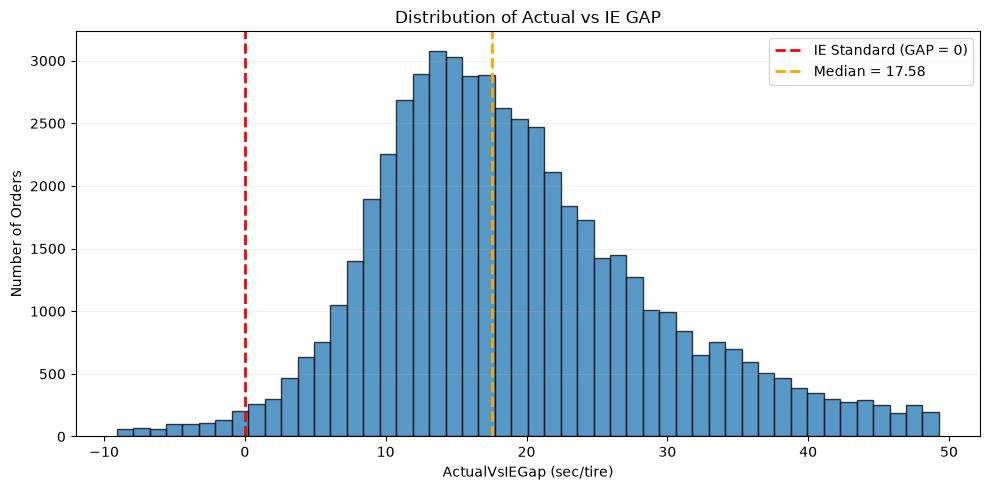

Y DISTRIBUTION SUMMARY
Orders          : 53,776
Mean GAP        : 19.05 sec/tire
Median GAP      : 17.58 sec/tire
Std             : 9.92 sec/tire
Min             : -9.10 sec/tire
Max             : 49.28 sec/tire
Above IE (GAP>0): 98.6%
Below IE (GAP<0): 1.4%


In [ ]:
# ============================================================
# Y Distribution - ActualVsIEGap
# ============================================================

import matplotlib.pyplot as plt

TARGET = "ActualVsIEGap"

y = df_model_gap[TARGET].dropna()


# ------------------------------------------------------------
# 1. Distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    y,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

# IE standard reference line
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="IE Standard (GAP = 0)"
)

# Median
plt.axvline(
    x=y.median(),
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Median = {y.median():.2f}"
)

plt.title("Distribution of Actual vs IE GAP")
plt.xlabel("ActualVsIEGap (sec/tire)")
plt.ylabel("Number of Orders")

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 2. Y summary
# ------------------------------------------------------------

print("=" * 60)
print("Y DISTRIBUTION SUMMARY")
print("=" * 60)

print(f"Orders          : {len(y):,}")
print(f"Mean GAP        : {y.mean():.2f} sec/tire")
print(f"Median GAP      : {y.median():.2f} sec/tire")
print(f"Std             : {y.std():.2f} sec/tire")
print(f"Min             : {y.min():.2f} sec/tire")
print(f"Max             : {y.max():.2f} sec/tire")
print(f"Above IE (GAP>0): {(y > 0).mean()*100:.1f}%")
print(f"Below IE (GAP<0): {(y < 0).mean()*100:.1f}%")

In [ ]:
# ============================================================
# Step 68 - Model Leakage Audit
# Purpose:
# 1. Check direct target leakage
# 2. Check formula / mathematical coupling
# 3. Check post-production features
# 4. Check Train/Test category overlap
# 5. Check duplicate records across Train and Test
# 6. Do NOT modify or retrain the model
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 68.1 - Basic dataset check
# ------------------------------------------------------------

print("=== Step 68 - Model Leakage Audit ===")

print("\nDataset:")
print("X_setup:", X_setup.shape)
print("y_setup:", y_setup.shape)

print(
    "X missing cells:",
    X_setup.isna().sum().sum()
)


# ------------------------------------------------------------
# 68.2 - Check direct target leakage columns
#
# These fields directly contain or construct Y.
# None of them should be in Model X.
# ------------------------------------------------------------

direct_leakage_candidates = [

    "ActualVsIEGap",
    "CycleTimeGapWithIE",

    "ActualTimePerTire",

    "ActualProcessingTime",
    "ActualOrderDurationSeconds",
    "ActualProductionTimeSeconds",

    "ActualEndTime",

    "IEStandardTotalTimePerTire"
]


direct_leakage_found = [
    col for col in direct_leakage_candidates
    if col in X_setup.columns
]


print("\n=== Direct Target Leakage Check ===")

print(
    "Direct leakage fields found in X:",
    direct_leakage_found
)

if len(direct_leakage_found) == 0:
    print("✅ No direct target column found in X.")
else:
    print("⚠️ Direct target leakage exists.")


# ------------------------------------------------------------
# 68.3 - Check mathematical coupling
#
# Current target:
#
# ActualVsIEGap =
# [(ActualEnd - ActualStart - 780) / QuantityDone]
# - IE Standard Time
#
# QuantityDone is therefore directly inside the Y formula.
# ------------------------------------------------------------

formula_coupled_features = [

    "QuantityDone",

    "IEStandardCycleTimePer100Tire",
    "CycleTimeTolerancePer100Tire"
]


print("\n=== Mathematical Coupling Check ===")

for col in formula_coupled_features:

    print(
        f"{col:<40}",
        col in X_setup.columns
    )


print(
    "\n⚠️ QuantityDone is mathematically coupled with Y "
    "because it is the denominator of ActualTimePerTire."
)

print(
    "IE cycle and tolerance are related to the benchmark "
    "subtracted from Y, but they are not automatically invalid. "
    "Their inclusion depends on the model purpose."
)


# ------------------------------------------------------------
# 68.4 - Check potential post-outcome features
#
# These values may only be fully known during or after production.
# They can be valid for retrospective root-cause analysis,
# but not necessarily for pre-production prediction.
# ------------------------------------------------------------

post_outcome_candidates = [

    "OperatorOverlapSeconds",
    "OperatorCoverageRatio",

    "Comment",

    "ExtTerminated",

    "QuantityDone",

    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth"
]


post_outcome_found = [
    col for col in post_outcome_candidates
    if col in X_setup.columns
]


print("\n=== Potential Post-outcome Features ===")

for col in post_outcome_found:
    print(col)


# ------------------------------------------------------------
# 68.5 - Show current importance of potential leakage features
#
# Uses Step 63 result if available.
# ------------------------------------------------------------

if "xgb_feature_importance" in globals():

    leakage_importance = (
        xgb_feature_importance[
            xgb_feature_importance[
                "Original_Feature"
            ].isin(
                post_outcome_candidates
                + formula_coupled_features
            )
        ]
        .copy()
        .sort_values(
            "Importance",
            ascending=False
        )
    )

    print(
        "\n=== Importance of Potential Leakage / Coupled Features ==="
    )

    display(leakage_importance)


# ------------------------------------------------------------
# 68.6 - Check category overlap between Train and Test
#
# If almost every Test Recipe also exists in Train,
# random split measures performance on known Recipes,
# not generalization to new Recipes.
# ------------------------------------------------------------

category_overlap_features = [

    "RecipeID",
    "OperatorUserID",
    "WorkCenterID",
    "WorkCenterNameCoupled",
    "tire_size"
]


category_overlap_results = []


for col in category_overlap_features:

    if col not in X_train.columns:
        continue

    train_values = set(
        X_train[col]
        .astype(str)
        .unique()
    )

    test_values = set(
        X_test[col]
        .astype(str)
        .unique()
    )

    shared_values = (
        train_values
        & test_values
    )

    unseen_test_values = (
        test_values
        - train_values
    )

    test_rows_seen = (
        X_test[col]
        .astype(str)
        .isin(train_values)
        .mean()
        * 100
    )

    category_overlap_results.append({

        "Feature": col,

        "Train_Unique":
            len(train_values),

        "Test_Unique":
            len(test_values),

        "Shared_Categories":
            len(shared_values),

        "Unseen_Test_Categories":
            len(unseen_test_values),

        "Test_Rows_with_Category_Seen_in_Train_%":
            test_rows_seen
    })


category_overlap_df = pd.DataFrame(
    category_overlap_results
)


print("\n=== Train / Test Category Overlap ===")

display(
    category_overlap_df.round(2)
)


# ------------------------------------------------------------
# 68.7 - Check exact duplicate X records
# ------------------------------------------------------------

train_row_hash = pd.util.hash_pandas_object(
    X_train,
    index=False
)

test_row_hash = pd.util.hash_pandas_object(
    X_test,
    index=False
)


shared_exact_rows = (
    set(train_row_hash)
    & set(test_row_hash)
)


test_duplicate_mask = (
    test_row_hash.isin(
        shared_exact_rows
    )
)


print("\n=== Exact Duplicate X Check ===")

print(
    "Exact X patterns appearing in both Train and Test:",
    len(shared_exact_rows)
)

print(
    "Test rows whose complete X pattern appears in Train:",
    test_duplicate_mask.sum()
)

print(
    "Percentage of Test rows duplicated in Train:",
    round(
        test_duplicate_mask.mean() * 100,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 68.8 - Check duplicate high-cardinality identity patterns
#
# Recipe + WorkCenter + Operator can effectively identify
# a production pattern even if OrderID is excluded.
# ------------------------------------------------------------

identity_cols = [
    col for col in [

        "RecipeID",
        "WorkCenterID",
        "OperatorUserID",
        "tire_size"

    ]
    if col in X_setup.columns
]


train_identity = (
    X_train[
        identity_cols
    ]
    .astype(str)
    .agg(
        "|".join,
        axis=1
    )
)


test_identity = (
    X_test[
        identity_cols
    ]
    .astype(str)
    .agg(
        "|".join,
        axis=1
    )
)


train_identity_set = set(
    train_identity
)


test_identity_seen_rate = (
    test_identity
    .isin(train_identity_set)
    .mean()
    * 100
)


print("\n=== Combined Identity-pattern Check ===")

print(
    "Identity columns:",
    identity_cols
)

print(
    "Test rows with same Recipe + Machine + Operator + Size "
    "pattern already present in Train:",
    round(
        test_identity_seen_rate,
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 68.9 - Check Comment cardinality and values
#
# Comment can contain production outcome or exception information.
# ------------------------------------------------------------

if "Comment" in X_setup.columns:

    print("\n=== Comment Leakage Check ===")

    print(
        "Unique Comment values:",
        X_setup["Comment"]
        .nunique(dropna=False)
    )

    comment_summary = (
        X_setup["Comment"]
        .value_counts(dropna=False)
        .head(20)
        .reset_index()
    )

    comment_summary.columns = [
        "Comment_Value",
        "Order_Count"
    ]

    display(comment_summary)


# ------------------------------------------------------------
# 68.10 - Audit summary
# ------------------------------------------------------------

print("\n=== Leakage Audit Summary ===")

print(
    "1. Direct Y leakage found:",
    len(direct_leakage_found) > 0
)

print(
    "2. QuantityDone mathematically coupled with Y:",
    "QuantityDone" in X_setup.columns
)

print(
    "3. Post-outcome Operator fields included:",
    any(
        col in X_setup.columns
        for col in [
            "OperatorOverlapSeconds",
            "OperatorCoverageRatio"
        ]
    )
)

print(
    "4. Comment included:",
    "Comment" in X_setup.columns
)

print(
    "5. Random split used:",
    True
)

print(
    "\n⚠️ Final leakage judgment requires comparison models, "
    "not only column inspection."
)

=== Step 68 - Model Leakage Audit ===

Dataset:


NameError: name 'X_setup' is not defined

In [ ]:
# ============================================================
# Step 68.0 - Check Current Model Variables
# ============================================================

variables_to_check = [
    "X_setup",
    "y_setup",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "xgb_balanced_best_pipeline"
]

for var in variables_to_check:
    if var in globals():
        obj = globals()[var]
        shape = getattr(obj, "shape", "available")
        print(f"{var:<30} ✅  {shape}")
    else:
        print(f"{var:<30} ❌  not found")

X_setup                        ❌  not found
y_setup                        ❌  not found
X_train                        ✅  (43020, 92)
X_test                         ✅  (10756, 92)
y_train                        ✅  (43020,)
y_test                         ✅  (10756,)
xgb_balanced_best_pipeline     ❌  not found


In [ ]:
# ============================================================
# Step 68 - Complete Model Leakage Audit
# Purpose:
# 1. Rebuild the current modeling dataset from Train + Test
# 2. Check direct target leakage
# 3. Check mathematical coupling with Y
# 4. Check post-production / future-information leakage
# 5. Check Recipe / Machine / Operator overlap across Train/Test
# 6. Check exact duplicate X patterns
# 7. Prepare for stricter validation
#
# IMPORTANT:
# This step DOES NOT modify any model data.
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 68.1 - Rebuild audit dataset
#
# Use the existing Train / Test data directly.
# No dependency on X_setup / y_setup.
# ------------------------------------------------------------

X_audit = pd.concat(
    [
        X_train,
        X_test
    ],
    axis=0
).copy()

y_audit = pd.concat(
    [
        y_train,
        y_test
    ],
    axis=0
).copy()


print("=== Step 68 - Model Leakage Audit ===")

print("\n=== Current Modeling Dataset ===")

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("\nCombined:")

print("X_audit :", X_audit.shape)
print("y_audit :", y_audit.shape)

print(
    "X missing cells:",
    X_audit.isna().sum().sum()
)


# ============================================================
# 68.2 - DIRECT TARGET LEAKAGE
#
# These columns should NOT appear in X because they directly
# contain Y or information used to construct Actual cycle time.
# ============================================================

dangerous_columns = [

    "ActualVsIEGap",
    "CycleTimeGapWithIE",

    "ActualTimePerTire",

    "ActualProcessingTime",

    "ActualOrderDurationSeconds",
    "ActualProductionTimeSeconds",

    "ActualEndTime",

    "IEStandardTotalTimePerTire"
]


direct_leakage_found = [

    col
    for col in dangerous_columns

    if col in X_audit.columns
]


print("\n" + "=" * 80)
print("68.2 - DIRECT TARGET LEAKAGE")
print("=" * 80)

print(
    "Direct leakage columns found:",
    direct_leakage_found
)


if len(direct_leakage_found) == 0:

    print(
        "✅ No direct target leakage detected."
    )

else:

    print(
        "⚠️ WARNING: Direct target leakage exists."
    )


# ============================================================
# 68.3 - MATHEMATICAL COUPLING
#
# Current Y:
#
# ActualVsIEGap
# =
# ((ActualDuration - 780) / QuantityDone)
# -
# ((IE Cycle + Tolerance) / 100)
#
# Therefore these X variables are mathematically connected
# to Y even though they are not direct target leakage.
# ============================================================

formula_related_features = [

    "QuantityDone",

    "IEStandardCycleTimePer100Tire",

    "CycleTimeTolerancePer100Tire"
]


print("\n" + "=" * 80)
print("68.3 - MATHEMATICAL COUPLING")
print("=" * 80)


for col in formula_related_features:

    print(
        f"{col:<40}",
        "IN MODEL"
        if col in X_audit.columns
        else "NOT IN MODEL"
    )


print(
    "\nInterpretation:"
)

print(
    "QuantityDone is mathematically linked to Y "
    "because QuantityDone is the denominator "
    "of ActualTimePerTire."
)

print(
    "IE Standard Cycle Time and Tolerance are linked "
    "to the benchmark subtracted from ActualTimePerTire."
)

print(
    "These are NOT automatically invalid, "
    "but their role must be clearly understood."
)


# ============================================================
# 68.4 - POST-OUTCOME / FUTURE INFORMATION CHECK
#
# These features may only become available during
# or after production.
# ============================================================

post_outcome_candidates = [

    "QuantityDone",

    "OperatorOverlapSeconds",
    "OperatorCoverageRatio",

    "Comment",

    "ExtTerminated",

    "ActualStartHour",
    "ActualStartDayOfWeek",
    "ActualStartMonth"
]


post_outcome_found = [

    col
    for col in post_outcome_candidates

    if col in X_audit.columns
]


print("\n" + "=" * 80)
print("68.4 - POTENTIAL POST-OUTCOME FEATURES")
print("=" * 80)


for col in post_outcome_found:

    print(col)


print(
    "\nInterpretation:"
)

print(
    "These features may be acceptable for retrospective "
    "root-cause analysis, but some would not be available "
    "for a pre-production prediction model."
)


# ============================================================
# 68.5 - COMMENT CHECK
#
# Comment is especially important because it may contain
# abnormal-event information recorded after production.
# ============================================================

print("\n" + "=" * 80)
print("68.5 - COMMENT CHECK")
print("=" * 80)


if "Comment" in X_audit.columns:

    print(
        "Unique Comment values:",
        X_audit[
            "Comment"
        ].nunique(
            dropna=False
        )
    )


    comment_summary = (

        X_audit[
            "Comment"
        ]

        .value_counts(
            dropna=False
        )

        .head(20)

        .reset_index()
    )


    comment_summary.columns = [

        "Comment_Value",

        "Order_Count"
    ]


    display(
        comment_summary
    )

else:

    print(
        "Comment is not included in Model X."
    )


# ============================================================
# 68.6 - TRAIN / TEST CATEGORY OVERLAP
#
# Critical check:
#
# Does the Test set contain the same Recipe / Operator /
# WorkCenter / Tire Size already seen in Train?
# ============================================================

category_overlap_features = [

    "RecipeID",

    "OperatorUserID",

    "WorkCenterID",

    "WorkCenterNameCoupled",

    "tire_size"
]


category_overlap_results = []


for col in category_overlap_features:


    if col not in X_train.columns:

        continue


    train_values = set(

        X_train[col]
        .astype(str)
        .unique()
    )


    test_values = set(

        X_test[col]
        .astype(str)
        .unique()
    )


    shared_values = (

        train_values
        &
        test_values
    )


    unseen_test_values = (

        test_values
        -
        train_values
    )


    test_rows_seen = (

        X_test[col]
        .astype(str)
        .isin(
            train_values
        )
        .mean()
        * 100
    )


    category_overlap_results.append({

        "Feature":
            col,

        "Train_Unique":
            len(train_values),

        "Test_Unique":
            len(test_values),

        "Shared_Categories":
            len(shared_values),

        "Unseen_Test_Categories":
            len(unseen_test_values),

        "Test_Rows_Category_Seen_in_Train_%":
            test_rows_seen
    })


category_overlap_df = pd.DataFrame(
    category_overlap_results
)


print("\n" + "=" * 80)
print("68.6 - TRAIN / TEST CATEGORY OVERLAP")
print("=" * 80)


display(
    category_overlap_df.round(2)
)


# ============================================================
# 68.7 - EXACT DUPLICATE X CHECK
#
# Check whether exactly the same 92-X pattern occurs
# in both Train and Test.
# ============================================================

train_hash = pd.util.hash_pandas_object(
    X_train,
    index=False
)


test_hash = pd.util.hash_pandas_object(
    X_test,
    index=False
)


train_hash_set = set(
    train_hash.values
)


test_duplicate_mask = (
    test_hash
    .isin(
        train_hash_set
    )
)


duplicate_test_rows = (
    test_duplicate_mask.sum()
)


duplicate_test_pct = (
    duplicate_test_rows
    /
    len(X_test)
    * 100
)


print("\n" + "=" * 80)
print("68.7 - EXACT DUPLICATE X CHECK")
print("=" * 80)


print(
    "Test rows with exact same X pattern in Train:",
    duplicate_test_rows
)

print(
    "Percentage of Test rows duplicated:",
    round(
        duplicate_test_pct,
        2
    ),
    "%"
)


# ============================================================
# 68.8 - HIGH-CARDINALITY IDENTITY PATTERN CHECK
#
# Recipe + Machine + Operator + Tire Size can act like
# a production fingerprint even without OrderID.
# ============================================================

identity_cols = [

    col
    for col in [

        "RecipeID",

        "WorkCenterID",

        "OperatorUserID",

        "tire_size"

    ]

    if col in X_train.columns
]


train_identity = (

    X_train[
        identity_cols
    ]

    .astype(str)

    .agg(
        "|".join,
        axis=1
    )
)


test_identity = (

    X_test[
        identity_cols
    ]

    .astype(str)

    .agg(
        "|".join,
        axis=1
    )
)


train_identity_set = set(
    train_identity
)


identity_seen_mask = (
    test_identity
    .isin(
        train_identity_set
    )
)


identity_seen_pct = (
    identity_seen_mask
    .mean()
    * 100
)


print("\n" + "=" * 80)
print("68.8 - COMBINED IDENTITY PATTERN CHECK")
print("=" * 80)


print(
    "Identity columns:",
    identity_cols
)


print(
    "Test rows with same Recipe + Machine + Operator + Size "
    "pattern already seen in Train:",
    round(
        identity_seen_pct,
        2
    ),
    "%"
)


# ============================================================
# 68.9 - RECIPE-SPECIFIC GENERALIZATION CHECK
#
# RecipeID is currently the largest XGBoost importance.
# This check tells us whether Test Recipes were mostly
# already present in Train.
# ============================================================

print("\n" + "=" * 80)
print("68.9 - RECIPE GENERALIZATION CHECK")
print("=" * 80)


if "RecipeID" in X_train.columns:


    train_recipes = set(

        X_train[
            "RecipeID"
        ]

        .astype(str)

        .unique()
    )


    test_recipes = set(

        X_test[
            "RecipeID"
        ]

        .astype(str)

        .unique()
    )


    shared_recipes = (
        train_recipes
        &
        test_recipes
    )


    unseen_test_recipes = (
        test_recipes
        -
        train_recipes
    )


    test_recipe_seen_pct = (

        X_test[
            "RecipeID"
        ]

        .astype(str)

        .isin(
            train_recipes
        )

        .mean()
        * 100
    )


    print(
        "Train Recipe count:",
        len(train_recipes)
    )

    print(
        "Test Recipe count:",
        len(test_recipes)
    )

    print(
        "Shared Recipes:",
        len(shared_recipes)
    )

    print(
        "Completely unseen Test Recipes:",
        len(unseen_test_recipes)
    )

    print(
        "Test rows whose Recipe was already seen in Train:",
        round(
            test_recipe_seen_pct,
            2
        ),
        "%"
    )


# ============================================================
# 68.10 - SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("68.10 - LEAKAGE AUDIT SUMMARY")
print("=" * 80)


print(
    "Direct Y leakage:",
    "YES"
    if len(direct_leakage_found) > 0
    else "NO"
)


print(
    "QuantityDone formula coupling:",
    "YES"
    if "QuantityDone" in X_audit.columns
    else "NO"
)


print(
    "Post-outcome Operator data included:",
    "YES"
    if (
        "OperatorOverlapSeconds" in X_audit.columns
        or
        "OperatorCoverageRatio" in X_audit.columns
    )
    else "NO"
)


print(
    "Comment included:",
    "YES"
    if "Comment" in X_audit.columns
    else "NO"
)


print(
    "Exact Train/Test duplicate rate:",
    round(
        duplicate_test_pct,
        2
    ),
    "%"
)


if "RecipeID" in X_train.columns:

    print(
        "Test rows with Recipe seen in Train:",
        round(
            test_recipe_seen_pct,
            2
        ),
        "%"
    )


print("\nAudit completed.")

=== Step 68 - Model Leakage Audit ===

=== Current Modeling Dataset ===
X_train : (43020, 92)
X_test  : (10756, 92)
y_train : (43020,)
y_test  : (10756,)

Combined:
X_audit : (53776, 92)
y_audit : (53776,)
X missing cells: 0

68.2 - DIRECT TARGET LEAKAGE
Direct leakage columns found: []
✅ No direct target leakage detected.

68.3 - MATHEMATICAL COUPLING
QuantityDone                             IN MODEL
IEStandardCycleTimePer100Tire            IN MODEL
CycleTimeTolerancePer100Tire             IN MODEL

Interpretation:
QuantityDone is mathematically linked to Y because QuantityDone is the denominator of ActualTimePerTire.
IE Standard Cycle Time and Tolerance are linked to the benchmark subtracted from ActualTimePerTire.
These are NOT automatically invalid, but their role must be clearly understood.

68.4 - POTENTIAL POST-OUTCOME FEATURES
QuantityDone
OperatorOverlapSeconds
OperatorCoverageRatio
Comment
ExtTerminated
ActualStartHour
ActualStartDayOfWeek
ActualStartMonth

Interpretation:
Th

,Comment_Value,Order_Count
0,1: N03303-D111V,10997
1,1: N03303-D222V,5230
2,1: N0430-D222V,5009
3,1: N03201-D111V,3467
4,1: N0430-D111V,3411
5,1: N03303-D222,2227
6,1: N03201-D222V,1982
7,1: N03303-D111T,1619
8,1: H2100-S111,1604
9,1: N0430-S121S /2: H2100-S101,1560



68.6 - TRAIN / TEST CATEGORY OVERLAP


,Feature,Train_Unique,Test_Unique,Shared_Categories,Unseen_Test_Categories,Test_Rows_Category_Seen_in_Train_%
0,RecipeID,703,664,660,4,99.95
1,OperatorUserID,257,237,235,2,99.98
2,WorkCenterID,45,45,45,0,100.00
3,WorkCenterNameCoupled,46,46,46,0,100.00
4,tire_size,147,146,146,0,100.00



68.7 - EXACT DUPLICATE X CHECK
Test rows with exact same X pattern in Train: 49
Percentage of Test rows duplicated: 0.46 %

68.8 - COMBINED IDENTITY PATTERN CHECK
Identity columns: ['RecipeID', 'WorkCenterID', 'OperatorUserID', 'tire_size']
Test rows with same Recipe + Machine + Operator + Size pattern already seen in Train: 86.03 %

68.9 - RECIPE GENERALIZATION CHECK
Train Recipe count: 703
Test Recipe count: 664
Shared Recipes: 660
Completely unseen Test Recipes: 4
Test rows whose Recipe was already seen in Train: 99.95 %

68.10 - LEAKAGE AUDIT SUMMARY
Direct Y leakage: NO
QuantityDone formula coupling: YES
Post-outcome Operator data included: YES
Comment included: YES
Exact Train/Test duplicate rate: 0.46 %
Test rows with Recipe seen in Train: 99.95 %

Audit completed.


In [ ]:
# ============================================================
# Step 69.0 - Install SHAP if needed
# ============================================================

%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 2.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
# ============================================================
# Step 69 - Prepare Final XGBoost Model for SHAP
# Purpose:
# 1. Use ONLY the confirmed final_xgb_pipeline
# 2. Extract fitted preprocessor
# 3. Extract fitted XGBoost model
# 4. Transform Test data
# 5. Prepare feature names for SHAP
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 69.1 - Safety Check
# ------------------------------------------------------------

if "final_xgb_pipeline" not in globals():
    raise RuntimeError(
        "final_xgb_pipeline is not available."
    )

print("=== Final XGBoost Pipeline ===")

print(
    "Pipeline type:",
    type(final_xgb_pipeline)
)

print(
    "Pipeline steps:",
    list(
        final_xgb_pipeline.named_steps.keys()
    )
)


# ------------------------------------------------------------
# 69.2 - Extract fitted Preprocessor and XGBoost Model
# ------------------------------------------------------------

final_preprocessor = (
    final_xgb_pipeline
    .named_steps["preprocessor"]
)

final_xgb_model = (
    final_xgb_pipeline
    .named_steps["model"]
)


print(
    "\nPreprocessor:",
    type(final_preprocessor)
)

print(
    "Model:",
    type(final_xgb_model)
)


# ------------------------------------------------------------
# 69.3 - Transform Test Data
# ------------------------------------------------------------

X_test_transformed = (
    final_preprocessor
    .transform(X_test)
)


print(
    "\nOriginal X_test:",
    X_test.shape
)

print(
    "Transformed X_test:",
    X_test_transformed.shape
)


# ------------------------------------------------------------
# 69.4 - Get Encoded Feature Names
# ------------------------------------------------------------

final_ohe = (
    final_preprocessor
    .named_transformers_["categorical"]
)


encoded_categorical_names = (
    final_ohe
    .get_feature_names_out(
        model_categorical_features
    )
)


final_feature_names = (

    list(model_numeric_features)
    +
    list(encoded_categorical_names)

)


print(
    "\nOriginal features:",
    len(model_numeric_features)
    +
    len(model_categorical_features)
)

print(
    "Encoded features:",
    len(final_feature_names)
)


# ------------------------------------------------------------
# 69.5 - Final Alignment Check
# ------------------------------------------------------------

assert (
    X_test_transformed.shape[1]
    ==
    len(final_feature_names)
), (
    "Feature-name count does not match "
    "transformed X columns."
)


print(
    "\n✅ Final model and transformed features "
    "are aligned and ready for SHAP."
)

=== Final XGBoost Pipeline ===
Pipeline type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: ['preprocessor', 'model']

Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Model: <class 'xgboost.sklearn.XGBRegressor'>

Original X_test: (10752, 92)
Transformed X_test: (10752, 2747)

Original features: 92
Encoded features: 2747

✅ Final model and transformed features are aligned and ready for SHAP.


In [78]:
# ============================================================
# Step 70 - Aggregate SHAP to Original Business Features
# Purpose:
# 1. Calculate SHAP using the confirmed final XGBoost model
# 2. Aggregate 2,747 encoded features back to 92 business X
# 3. Measure overall impact strength
# 4. Measure positive vs negative impact direction
# 5. Do NOT retrain the model
# ============================================================

import shap
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 70.1 - Sample Test Data
#
# Use 2,000 test orders for efficient SHAP calculation
# ------------------------------------------------------------

SHAP_SAMPLE_SIZE = min(
    2000,
    len(X_test)
)

X_shap_sample = (
    X_test
    .sample(
        n=SHAP_SAMPLE_SIZE,
        random_state=42
    )
    .copy()
)


# ------------------------------------------------------------
# 70.2 - Transform the SAME sample
# using the fitted final preprocessor
# ------------------------------------------------------------

X_shap_transformed = (
    final_preprocessor
    .transform(
        X_shap_sample
    )
)


print(
    "SHAP sample:",
    X_shap_sample.shape
)

print(
    "Transformed SHAP sample:",
    X_shap_transformed.shape
)


# ------------------------------------------------------------
# 70.3 - Calculate SHAP
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    final_xgb_model
)

shap_values = explainer(
    X_shap_transformed
)


print(
    "SHAP values shape:",
    shap_values.values.shape
)


# ------------------------------------------------------------
# 70.4 - Safety Check
# ------------------------------------------------------------

assert (
    shap_values.values.shape[1]
    ==
    len(final_feature_names)
)

print(
    "✅ SHAP columns aligned with encoded features."
)


# ------------------------------------------------------------
# 70.5 - Map every encoded feature
# back to the original business feature
# ------------------------------------------------------------

def map_to_original_feature(
    encoded_feature
):

    # Numeric variables remain unchanged
    if encoded_feature in model_numeric_features:

        return encoded_feature


    # One-Hot categorical variables
    for original_feature in model_categorical_features:

        prefix = (
            original_feature
            + "_"
        )

        if encoded_feature.startswith(
            prefix
        ):

            return original_feature


    return encoded_feature


feature_mapping = pd.DataFrame({

    "Encoded_Feature":
        final_feature_names

})


feature_mapping[
    "Original_Feature"
] = (

    feature_mapping[
        "Encoded_Feature"
    ]

    .apply(
        map_to_original_feature
    )

)


# ------------------------------------------------------------
# 70.6 - Calculate encoded-feature SHAP statistics
#
# Mean_Abs_SHAP:
# Overall impact strength
#
# Mean_SHAP:
# Average direction
#
# Positive_SHAP_%:
# % of observations where feature pushes GAP higher
#
# Negative_SHAP_%:
# % of observations where feature pushes GAP lower
# ------------------------------------------------------------

shap_matrix = (
    shap_values.values
)


encoded_shap_summary = pd.DataFrame({

    "Encoded_Feature":
        final_feature_names,

    "Mean_Abs_SHAP":
        np.abs(
            shap_matrix
        ).mean(
            axis=0
        ),

    "Mean_SHAP":
        shap_matrix.mean(
            axis=0
        ),

    "Positive_SHAP_%":
        (
            shap_matrix > 0
        ).mean(
            axis=0
        )
        * 100,

    "Negative_SHAP_%":
        (
            shap_matrix < 0
        ).mean(
            axis=0
        )
        * 100
})


encoded_shap_summary = (
    encoded_shap_summary
    .merge(
        feature_mapping,
        on="Encoded_Feature",
        how="left"
    )
)


# ------------------------------------------------------------
# 70.7 - Aggregate SHAP back to Original Features
#
# IMPORTANT:
#
# For each observation we first SUM the SHAP values
# of all One-Hot columns belonging to one business feature.
#
# This preserves the actual SHAP contribution direction.
# ------------------------------------------------------------

original_features = (
    list(model_numeric_features)
    +
    list(model_categorical_features)
)


aggregated_shap_rows = []


for feature in original_features:

    encoded_indices = np.where(
        feature_mapping[
            "Original_Feature"
        ].values == feature
    )[0]


    if len(encoded_indices) == 0:

        continue


    # SHAP contribution of this business feature
    # for every individual order
    feature_shap_values = (
        shap_matrix[
            :,
            encoded_indices
        ]
        .sum(
            axis=1
        )
    )


    aggregated_shap_rows.append({

        "Original_Feature":
            feature,

        # Overall strength
        "Mean_Abs_SHAP":
            np.abs(
                feature_shap_values
            ).mean(),

        # Average direction
        "Mean_SHAP":
            feature_shap_values.mean(),

        # How often it pushes GAP higher
        "Positive_SHAP_%":
            (
                feature_shap_values > 0
            ).mean()
            * 100,

        # How often it pushes GAP lower
        "Negative_SHAP_%":
            (
                feature_shap_values < 0
            ).mean()
            * 100,

        # Typical positive contribution
        "Median_SHAP":
            np.median(
                feature_shap_values
            )
    })


# ------------------------------------------------------------
# 70.8 - Create Business SHAP Summary
# ------------------------------------------------------------

business_shap_summary = pd.DataFrame(
    aggregated_shap_rows
)


# ------------------------------------------------------------
# 70.9 - Calculate SHAP Importance %
# ------------------------------------------------------------

business_shap_summary[
    "SHAP_Importance_%"
] = (

    business_shap_summary[
        "Mean_Abs_SHAP"
    ]

    /

    business_shap_summary[
        "Mean_Abs_SHAP"
    ].sum()

    * 100
)


# ------------------------------------------------------------
# 70.10 - Add simple direction classification
#
# NOTE:
# Mixed is expected for categorical features because
# some category values may push GAP up while others push down.
# ------------------------------------------------------------

def classify_direction(
    row
):

    if (
        row["Positive_SHAP_%"]
        >= 65
    ):

        return "Mostly GAP ↑"

    elif (
        row["Negative_SHAP_%"]
        >= 65
    ):

        return "Mostly GAP ↓"

    else:

        return "Mixed / Nonlinear"


business_shap_summary[
    "Direction"
] = (
    business_shap_summary
    .apply(
        classify_direction,
        axis=1
    )
)


# ------------------------------------------------------------
# 70.11 - Sort by overall SHAP importance
# ------------------------------------------------------------

business_shap_summary = (

    business_shap_summary
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(
        drop=True
    )

)


# ------------------------------------------------------------
# 70.12 - Add rank
# ------------------------------------------------------------

business_shap_summary.insert(
    0,
    "Rank",
    range(
        1,
        len(
            business_shap_summary
        ) + 1
    )
)


# ------------------------------------------------------------
# 70.13 - Round output
# ------------------------------------------------------------

round_cols = [

    "SHAP_Importance_%",

    "Mean_Abs_SHAP",

    "Mean_SHAP",

    "Median_SHAP",

    "Positive_SHAP_%",

    "Negative_SHAP_%"
]


business_shap_summary[
    round_cols
] = (

    business_shap_summary[
        round_cols
    ]

    .round(3)

)


# ------------------------------------------------------------
# 70.14 - Display Top 30
# ------------------------------------------------------------

print(
    "\n=== Step 70 - Business Feature SHAP Analysis ==="
)

print(
    "Original business features analyzed:",
    len(
        business_shap_summary
    )
)


display(
    business_shap_summary[
        [
            "Rank",
            "Original_Feature",
            "SHAP_Importance_%",
            "Mean_Abs_SHAP",
            "Mean_SHAP",
            "Positive_SHAP_%",
            "Negative_SHAP_%",
            "Direction"
        ]
    ]
    .head(30)
)

SHAP sample: (2000, 92)
Transformed SHAP sample: (2000, 2747)
SHAP values shape: (2000, 2747)
✅ SHAP columns aligned with encoded features.

=== Step 70 - Business Feature SHAP Analysis ===
Original business features analyzed: 91


,Rank,Original_Feature,SHAP_Importance_%,Mean_Abs_SHAP,Mean_SHAP,Positive_SHAP_%,Negative_SHAP_%,Direction
0,1,OperatorOverlapSeconds,28.558001,11.457,-0.590,55.65,44.35,Mixed / Nonlinear
1,2,OperatorCoverageRatio,27.563000,11.057,0.452,40.65,59.35,Mixed / Nonlinear
2,3,QuantityDone,23.687000,9.502,-0.563,50.65,49.35,Mixed / Nonlinear
3,4,IEStandardCycleTimePer100Tire,6.439000,2.583,0.138,68.95,31.05,Mostly GAP ↑
4,5,CycleTimeTolerancePer100Tire,1.300000,0.521,-0.010,49.45,50.55,Mixed / Nonlinear
5,6,PlannedQuantity,1.288000,0.517,0.288,78.10,21.90,Mostly GAP ↑
6,7,WorkCenterID,0.735000,0.295,0.020,67.10,32.90,Mostly GAP ↑
7,8,DestinationInfo,0.694000,0.278,0.017,18.75,81.25,Mostly GAP ↓
8,9,1_bead_reinforcement_-_width,0.491000,0.197,0.011,90.15,9.85,Mostly GAP ↑
9,10,rim_diameter,0.451000,0.181,-0.022,37.60,62.40,Mixed / Nonlinear


In [79]:
# ============================================================
# Step 70A - Production-friendly SHAP Direction Chart
# Purpose:
# 1. Show actual SHAP impact direction clearly
# 2. Red   = pushes GAP higher / slower than IE
# 3. Green = pushes GAP lower / faster than IE
# 4. Show positive / negative impact percentage
# 5. Aggregate One-Hot columns back to business features
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 70A.1 - Aggregate SHAP by original business feature
# ------------------------------------------------------------

result = []

for feature in (
    list(model_numeric_features)
    + list(model_categorical_features)
):

    idx = np.where(
        feature_mapping["Original_Feature"].values
        == feature
    )[0]

    if len(idx) == 0:
        continue

    # Total SHAP contribution of this business feature
    # for every sampled order
    values = shap_matrix[:, idx].sum(axis=1)

    positive_values = values[values > 0]
    negative_values = values[values < 0]

    result.append({

        "Feature": feature,

        # Overall impact magnitude
        "Mean_Abs_SHAP":
            np.abs(values).mean(),

        # % of orders pushing GAP upward
        "Positive_%":
            (values > 0).mean() * 100,

        # % of orders pushing GAP downward
        "Negative_%":
            (values < 0).mean() * 100,

        # Average positive contribution
        "Mean_Positive_SHAP":
            positive_values.mean()
            if len(positive_values) > 0
            else 0,

        # Average negative contribution
        "Mean_Negative_SHAP":
            negative_values.mean()
            if len(negative_values) > 0
            else 0
    })


shap_direction_df = (
    pd.DataFrame(result)
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 70A.2 - Select Top 15
# ------------------------------------------------------------

plot_df = (
    shap_direction_df
    .head(15)
    .sort_values(
        "Mean_Abs_SHAP",
        ascending=True
    )
    .copy()
)


# ------------------------------------------------------------
# 70A.3 - Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 8)
)

y = np.arange(len(plot_df))


# Negative contribution
ax.barh(
    y,
    plot_df["Mean_Negative_SHAP"],
    color="#2E8B57",
    label="Push GAP lower"
)


# Positive contribution
ax.barh(
    y,
    plot_df["Mean_Positive_SHAP"],
    color="#D9534F",
    label="Push GAP higher"
)


# Zero line
ax.axvline(
    0,
    color="black",
    linewidth=1
)


# Feature labels
ax.set_yticks(y)

ax.set_yticklabels(
    plot_df["Feature"]
)


# ------------------------------------------------------------
# 70A.4 - Add direction percentages
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    plot_df.iterrows()
):

    ax.text(
        row["Mean_Positive_SHAP"] + 0.15,
        i,
        f'↑ {row["Positive_%"]:.0f}%',
        va="center",
        fontsize=9,
        color="#B22222"
    )

    ax.text(
        row["Mean_Negative_SHAP"] - 0.15,
        i,
        f'↓ {row["Negative_%"]:.0f}%',
        va="center",
        ha="right",
        fontsize=9,
        color="#1F6F46"
    )


# ------------------------------------------------------------
# 70A.5 - Formatting
# ------------------------------------------------------------

ax.set_title(
    "Top Production Factors - SHAP Impact Direction",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Average SHAP impact on Actual vs IE GAP (sec/tire)"
)

ax.legend(
    loc="lower right"
)

plt.tight_layout()


# ------------------------------------------------------------
# 70A.6 - Save
# ------------------------------------------------------------

plt.savefig(
    "SHAP_Production_Impact_Direction.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 70A.7 - Display supporting table
# ------------------------------------------------------------

display(
    shap_direction_df[
        [
            "Feature",
            "Mean_Abs_SHAP",
            "Positive_%",
            "Negative_%",
            "Mean_Positive_SHAP",
            "Mean_Negative_SHAP"
        ]
    ]
    .head(15)
    .round(2)
)

C:\Users\Wangw3\AppData\Local\Temp\ipykernel_27360\2305374216.py:201: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,Feature,Mean_Abs_SHAP,Positive_%,Negative_%,Mean_Positive_SHAP,Mean_Negative_SHAP
0,OperatorOverlapSeconds,11.46,55.65,44.35,9.76,-13.58
1,OperatorCoverageRatio,11.06,40.65,59.35,14.16,-8.93
2,QuantityDone,9.50,50.65,49.35,8.83,-10.20
3,IEStandardCycleTimePer100Tire,2.58,68.95,31.05,1.97,-3.94
4,CycleTimeTolerancePer100Tire,0.52,49.45,50.55,0.52,-0.53
5,PlannedQuantity,0.52,78.10,21.90,0.52,-0.52
6,WorkCenterID,0.29,67.10,32.90,0.23,-0.42
7,DestinationInfo,0.28,18.75,81.25,0.79,-0.16
8,1_bead_reinforcement_-_width,0.20,90.15,9.85,0.12,-0.94
9,rim_diameter,0.18,37.60,62.40,0.21,-0.16


In [81]:
# ============================================================
# Step 71 - Counterfactual Analysis
# Purpose:
# 1. Analyze Top 10% highest predicted-GAP orders
# 2. Change ONE feature at a time
# 3. Use only values observed in training data
# 4. Rank factors by predicted GAP reduction
# 5. DO NOT retrain the model
# ============================================================

import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 71.1 - Select factors to test
# ------------------------------------------------------------

counterfactual_features = [

    "OperatorOverlapSeconds",
    "OperatorCoverageRatio",

    "PlannedQuantity",
    "ActualStartHour",
    "PlannedStartHour",
    "ShiftNumber",

    "WorkCenterID",
    "WorkCenterNameCoupled",

    "1_apex_-_width",
    "1_bead_reinforcement_-_width",
    "2_stage_drum_diameter",
    "1_tread_base_-_width",
    "1_sidewall_profile_-_weight",
    "rim_diameter",
    "1_belt_-_width",

    "1_sidewall_profile_-_compound"
]


counterfactual_features = [
    col
    for col in counterfactual_features
    if col in X_test.columns
]


# ------------------------------------------------------------
# 71.2 - Predict entire Test set
# ------------------------------------------------------------

original_prediction = (
    final_xgb_pipeline.predict(
        X_test
    )
)


# ------------------------------------------------------------
# 71.3 - Select Top 10% highest predicted-GAP orders
# ------------------------------------------------------------

high_gap_threshold = np.quantile(
    original_prediction,
    0.90
)


high_gap_mask = (
    original_prediction
    >= high_gap_threshold
)


X_cf = (
    X_test
    .loc[high_gap_mask]
    .copy()
)


baseline_prediction = (
    original_prediction[
        high_gap_mask
    ]
)


print(
    "High-GAP threshold:",
    round(high_gap_threshold, 2),
    "sec/tire"
)

print(
    "Orders analyzed:",
    len(X_cf)
)

print(
    "Average original predicted GAP:",
    round(
        baseline_prediction.mean(),
        2
    ),
    "sec/tire"
)


# ------------------------------------------------------------
# 71.4 - Generate realistic candidate values
#
# Numeric:
# P10 / P25 / Median / P75 / P90
#
# Categorical:
# Top 10 most commonly observed values
# ------------------------------------------------------------

def get_candidate_values(feature):

    series = (
        X_train[feature]
        .dropna()
    )


    if feature in model_numeric_features:

        return (
            series
            .quantile(
                [
                    0.10,
                    0.25,
                    0.50,
                    0.75,
                    0.90
                ]
            )
            .drop_duplicates()
            .tolist()
        )


    else:

        return (
            series
            .value_counts()
            .head(10)
            .index
            .tolist()
        )


# ------------------------------------------------------------
# 71.5 - One-feature-at-a-time What-if analysis
# ------------------------------------------------------------

results = []


for feature in counterfactual_features:

    candidate_values = (
        get_candidate_values(
            feature
        )
    )


    best_prediction = (
        baseline_prediction.copy()
    )


    for candidate in candidate_values:

        X_changed = (
            X_cf.copy()
        )

        X_changed[feature] = (
            candidate
        )


        changed_prediction = (
            final_xgb_pipeline.predict(
                X_changed
            )
        )


        best_prediction = np.minimum(
            best_prediction,
            changed_prediction
        )


    # Predicted improvement
    improvement = (
        baseline_prediction
        -
        best_prediction
    )


    results.append({

        "Feature":
            feature,

        "Orders_Analyzed":
            len(X_cf),

        "Orders_Improved_%":
            (
                improvement > 0
            ).mean()
            * 100,

        "Average_Predicted_GAP_Reduction":
            improvement.mean(),

        "Median_Predicted_GAP_Reduction":
            np.median(
                improvement
            ),

        "Maximum_Predicted_GAP_Reduction":
            improvement.max(),

        "Average_New_Predicted_GAP":
            best_prediction.mean()

    })


# ------------------------------------------------------------
# 71.6 - Create ranking
# ------------------------------------------------------------

counterfactual_ranking = (

    pd.DataFrame(results)

    .sort_values(
        by=[
            "Average_Predicted_GAP_Reduction",
            "Orders_Improved_%"
        ],
        ascending=False
    )

    .reset_index(drop=True)

)


counterfactual_ranking.insert(
    0,
    "Rank",
    range(
        1,
        len(counterfactual_ranking) + 1
    )
)


# ------------------------------------------------------------
# 71.7 - Add investigation category
# ------------------------------------------------------------

def action_type(feature):

    if feature in [

        "PlannedQuantity",
        "WorkCenterID",
        "WorkCenterNameCoupled",
        "PlannedStartHour",
        "ShiftNumber"

    ]:

        return "Production / Planning"


    elif feature in [

        "OperatorOverlapSeconds",
        "OperatorCoverageRatio"

    ]:

        return "Production Context"


    else:

        return "Spec / IE Validation"


counterfactual_ranking[
    "Investigation_Area"
] = (
    counterfactual_ranking[
        "Feature"
    ]
    .apply(action_type)
)


# ------------------------------------------------------------
# 71.8 - Round results
# ------------------------------------------------------------

value_columns = [

    "Orders_Improved_%",

    "Average_Predicted_GAP_Reduction",

    "Median_Predicted_GAP_Reduction",

    "Maximum_Predicted_GAP_Reduction",

    "Average_New_Predicted_GAP"
]


counterfactual_ranking[
    value_columns
] = (

    counterfactual_ranking[
        value_columns
    ]
    .round(2)

)


# ------------------------------------------------------------
# 71.9 - Final output
# ------------------------------------------------------------

print(
    "\n=== Step 71 - Counterfactual Factor Ranking ==="
)


display(
    counterfactual_ranking[
        [
            "Rank",
            "Feature",
            "Investigation_Area",
            "Orders_Analyzed",
            "Orders_Improved_%",
            "Average_Predicted_GAP_Reduction",
            "Median_Predicted_GAP_Reduction",
            "Maximum_Predicted_GAP_Reduction",
            "Average_New_Predicted_GAP"
        ]
    ]
)

High-GAP threshold: 31.89 sec/tire
Orders analyzed: 1076
Average original predicted GAP: 37.23 sec/tire

=== Step 71 - Counterfactual Factor Ranking ===


,Rank,Feature,Investigation_Area,Orders_Analyzed,Orders_Improved_%,Average_Predicted_GAP_Reduction,Median_Predicted_GAP_Reduction,Maximum_Predicted_GAP_Reduction,Average_New_Predicted_GAP
0,1,OperatorOverlapSeconds,Production Context,1076,94.14,43.779999,48.110001,86.769997,-6.550000
1,2,OperatorCoverageRatio,Production Context,1076,52.32,18.469999,1.020000,75.070000,18.760000
2,3,PlannedQuantity,Production / Planning,1076,88.85,1.140000,0.790000,11.210000,36.080002
3,4,WorkCenterID,Production / Planning,1076,96.19,1.060000,0.760000,8.060000,36.169998
4,5,PlannedStartHour,Production / Planning,1076,96.84,1.010000,0.710000,15.800000,36.220001
5,6,ActualStartHour,Spec / IE Validation,1076,94.89,0.970000,0.730000,17.910000,36.259998
6,7,1_bead_reinforcement_-_width,Spec / IE Validation,1076,89.41,0.520000,0.240000,3.710000,36.709999
7,8,1_apex_-_width,Spec / IE Validation,1076,68.22,0.370000,0.070000,8.890000,36.860001
8,9,2_stage_drum_diameter,Spec / IE Validation,1076,84.20,0.360000,0.210000,2.610000,36.869999
9,10,1_tread_base_-_width,Spec / IE Validation,1076,85.41,0.350000,0.180000,4.830000,36.880001
